# CounterShield: ML intrusion detection under distribution shift (Modules 1–7)

# Module 1: Dataset Acquisition & Initial Setup

## 1.1 · Project environment setup: configuration

In [ ]:
RUN = {"unsw_nb15": True, "cic_ids2017": True, "bot_iot": True}

DATASETS = {
    "bot_iot":     {"handle": "shamstahzib/bot-iot-countershield-extract", "version": None, "name": "BoT-IoT", "prebuilt": "bot_iot.parquet"},
    "cic_ids2017": {"handle": "shamstahzib/cicids2017-dataset", "version": None, "name": "CIC-IDS2017"},
    "unsw_nb15":   {"handle": "shamstahzib/unsw-nb15-train-test", "version": None, "name": "UNSW-NB15"},
}

USE_DRIVE     = True
PROJECT_DIR   = "CounterShield"
FORCE_REBUILD = False
HASH_FILES    = True

BOTIOT_MAX_PER_CLASS = 300_000
BOTIOT_FILE_PATTERN  = None
BOTIOT_CHUNKSIZE     = 1_000_000
CIC_DROP_DUPLICATES  = False
SEED = 42

## 1.1 · Project environment setup: install & helpers

In [ ]:
!pip -q install -U kagglehub pyarrow
import kagglehub, sys, datetime as dt

import os, re, gc, json, time, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd

def list_data_files(root, exts=(".csv", ".parquet")):
    root = Path(root)
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in exts)

def human(n):
    for u in ["B", "KB", "MB", "GB", "TB"]:
        if n < 1024: return f"{n:,.1f} {u}"
        n /= 1024
    return f"{n:,.1f} PB"

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def clean_columns(df):
    df.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in df.columns]
    return df

def find_col(df, candidates):
    lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    return None

def norm_label(x):
    s = str(x).strip().lower()
    s = re.sub(r"[^a-z0-9]+", "_", s).strip("_")
    s = re.sub(r"_+", "_", s)
    if s in {"benign", "normal", "0", "", "nan", "none"}:
        return "benign"
    return s

def label_family(c):
    if c == "benign": return "benign"
    if "ddos" in c: return "ddos"
    if "dos" in c: return "dos"
    if any(k in c for k in ("portscan", "reconnaissance", "recon", "scan", "fingerprint", "analysis")):
        return "recon"
    if any(k in c for k in ("patator", "brute", "password")) and "web" not in c:
        return "brute_force"
    if any(k in c for k in ("web_attack", "xss", "sql")): return "web_attack"
    if c in ("bot", "botnet"): return "botnet"
    if any(k in c for k in ("theft", "exfiltration", "keylog")): return "exfiltration_theft"
    if any(k in c for k in ("backdoor", "worm")): return "malware_backdoor"
    if any(k in c for k in ("exploit", "shellcode", "infiltration", "heartbleed")): return "exploit"
    return "other"

def downcast(df):
    for c in df.select_dtypes(include=["float64"]).columns:
        df[c] = df[c].astype("float32")
    for c in df.select_dtypes(include=["int64"]).columns:
        df[c] = pd.to_numeric(df[c], downcast="integer")
    return df

def replace_inf(df):
    num = df.select_dtypes(include=[np.number]).columns
    df[num] = df[num].replace([np.inf, -np.inf], np.nan)
    return df

def add_labels(df, cls_series, binary_series, source, split="all"):
    df["y_class"] = cls_series.map(norm_label).astype("category")
    df["y_binary"] = binary_series.astype("int8")
    df["y_family"] = df["y_class"].astype(str).map(label_family).astype("category")
    df["source_dataset"] = source
    df["split"] = split
    return df

def read_any(path, **kw):
    path = Path(path)
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    return pd.read_csv(path, low_memory=False, **kw)

def process_unsw(root):
    files = list_data_files(root)
    tt = [f for f in files if re.search(r"train|test", f.name, re.I)]
    files = tt or files
    print("UNSW-NB15 files used:", [f.name for f in files])
    parts = []
    for f in files:
        df = clean_columns(read_any(f))
        lab = find_col(df, ["label"])
        cat = find_col(df, ["attack_cat"])
        if lab is None and cat is None:
            print(f"  ! skipping {f.name}: no label/attack_cat column"); continue
        split = "train" if re.search(r"train", f.name, re.I) else ("test" if re.search(r"test", f.name, re.I) else "all")
        cls = df[cat].astype(str) if cat else df[lab].map({0: "benign", 1: "attack"})
        if lab is not None:
            binary = pd.to_numeric(df[lab], errors="coerce").fillna(1)
        else:
            binary = (cls.map(norm_label) != "benign")
        parts.append(add_labels(df, cls, binary, "unsw_nb15", split))
    out = pd.concat(parts, ignore_index=True)
    return downcast(replace_inf(out))

def process_cic(root, drop_duplicates=False):
    files = list_data_files(root)
    print(f"CIC-IDS2017: {len(files)} files")
    parts = []
    for f in files:
        df = clean_columns(read_any(f))
        lab = find_col(df, ["Label", "label", "Attack", "attack_cat"])
        if lab is None:
            print(f"  ! skipping {f.name}: no label column"); continue
        cls = df[lab].astype(str)
        binary = cls.map(norm_label) != "benign"
        df = add_labels(df, cls, binary, "cic_ids2017", "all")
        df["source_file"] = f.stem
        parts.append(downcast(replace_inf(df)))
        print(f"  {f.name:<55} {len(df):>9,} rows")
    out = pd.concat(parts, ignore_index=True)
    del parts; gc.collect()
    n0 = len(out)
    num = out.select_dtypes(include=[np.number]).columns
    out = out.dropna(subset=num).reset_index(drop=True)
    if drop_duplicates:
        out = out.drop_duplicates().reset_index(drop=True)
    print(f"  dropped {n0 - len(out):,} rows with NaN/inf" + (" or duplicates" if drop_duplicates else ""))
    for c in ("y_class", "y_family", "source_file"):
        out[c] = out[c].astype("category")
    return out

BOTIOT_FULL_COLUMNS = [
    "pkSeqID", "stime", "flgs", "proto", "saddr", "sport", "daddr", "dport", "pkts", "bytes",
    "state", "ltime", "seq", "dur", "mean", "stddev", "smac", "dmac", "sum", "min", "max",
    "soui", "doui", "sco", "dco", "spkts", "dpkts", "sbytes", "dbytes", "rate", "srate",
    "drate", "attack", "category", "subcategory",
]

def select_botiot_files(root, pattern=None):
    files = [f for f in list_data_files(root, (".csv",))]
    feat = [f for f in files if re.search(r"feature_names|features", f.name, re.I)]
    data = [f for f in files if f not in feat]
    if pattern:
        chosen = sorted(Path(root).rglob(pattern))
    else:
        full = [f for f in data if re.search(r"(^data_\d+|Dataset_\d+)\.csv$", f.name, re.I)]
        pc5 = [f for f in data if re.search(r"5pc_\d+\.csv$", f.name, re.I)]
        chosen = full or pc5 or data
    key = lambda p: [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", p.name)]
    return sorted(chosen, key=key), (feat[0] if feat else None)

def _botiot_names(path, feature_file):
    first = pd.read_csv(path, nrows=1, header=None, low_memory=False)
    row = [str(v).strip().strip('"') for v in first.iloc[0].tolist()]
    if any(v.lower() in {"pkseqid", "attack", "category", "proto"} for v in row):
        return 0, None
    if feature_file is not None:
        names = [c.strip() for c in pd.read_csv(feature_file, header=None).iloc[0].astype(str).tolist() if str(c).strip()]
        if len(names) == len(row):
            return None, names
    if len(row) == len(BOTIOT_FULL_COLUMNS):
        return None, BOTIOT_FULL_COLUMNS
    raise ValueError(f"{path.name}: no header and {len(row)} columns - set BOTIOT_FILE_PATTERN or column names manually")

def _to_port(s):
    s = s.astype(str).str.strip()
    hexm = s.str.startswith("0x")
    out = pd.to_numeric(s.where(~hexm), errors="coerce")
    if hexm.any():
        out[hexm] = s[hexm].map(lambda v: int(v, 16) if re.fullmatch(r"0x[0-9a-fA-F]+", v) else np.nan)
    return out.astype("float32")

def process_botiot(root, max_per_class=300_000, chunksize=1_000_000, pattern=None, seed=42):
    files, feature_file = select_botiot_files(root, pattern)
    if not files:
        raise FileNotFoundError("No BoT-IoT CSV files found")
    print(f"BoT-IoT: {len(files)} CSV files, total {human(sum(f.stat().st_size for f in files))}")
    specs = {f: _botiot_names(f, feature_file) for f in files}

    def iter_chunks(usecols=None):
        for f in files:
            header, names = specs[f]
            kw = dict(header=header, names=names, chunksize=chunksize, low_memory=False)
            if usecols is not None:
                kw["usecols"] = lambda c: c.strip() in usecols
            for ch in pd.read_csv(f, **kw):
                yield f, clean_columns(ch)

    counts = pd.Series(dtype="int64")
    for _, ch in iter_chunks(usecols={"category"}):
        counts = counts.add(ch["category"].astype(str).str.strip().value_counts(), fill_value=0)
    counts = counts.astype("int64").sort_values(ascending=False)
    print("  full class counts:\n" + counts.to_string())
    frac = (max_per_class / counts).clip(upper=1.0) if max_per_class else counts * 0 + 1.0

    rng = np.random.default_rng(seed)
    parts = []
    for f, ch in iter_chunks():
        cat = ch["category"].astype(str).str.strip()
        keep = rng.random(len(ch)) < cat.map(frac).fillna(1.0).to_numpy()
        if keep.any():
            parts.append(ch.loc[keep])
    df = pd.concat(parts, ignore_index=True)
    del parts; gc.collect()
    for c in ("sport", "dport"):
        if c in df.columns: df[c] = _to_port(df[c])
    lab = find_col(df, ["attack"])
    cls = df["category"].astype(str).str.strip()
    binary = pd.to_numeric(df[lab], errors="coerce").fillna(1) if lab else (cls.map(norm_label) != "benign")
    df = add_labels(df, cls, binary, "bot_iot", "all")
    if "subcategory" in df.columns:
        df["subcategory"] = df["subcategory"].astype(str).str.strip().astype("category")
    df = downcast(replace_inf(df))
    print(f"  sampled {len(df):,} rows (max_per_class={max_per_class})")
    return df, counts

ID_OR_LEAKY_COLS = {
    "unsw_nb15": ["id", "label", "attack_cat"],
    "cic_ids2017": ["Flow ID", "Source IP", "Src IP", "Destination IP", "Dst IP",
                    "Timestamp", "Label", "Attack", "source_file"],
    "bot_iot": ["pkSeqID", "stime", "ltime", "seq", "saddr", "daddr", "smac", "dmac",
                "soui", "doui", "sco", "dco", "attack", "category", "subcategory"],
}
LABEL_COLS = ["y_class", "y_binary", "y_family", "source_dataset", "split"]

def get_xy(df, target="y_binary"):
    src = str(df["source_dataset"].iloc[0])
    drop = [c for c in ID_OR_LEAKY_COLS.get(src, []) + LABEL_COLS if c in df.columns]
    X = df.drop(columns=drop)
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]) or pd.api.types.is_bool_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes.astype("int32")
    X = X.fillna(0)
    return X, df[target]

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 1.1 · Project environment setup: Google Drive

In [ ]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive") / PROJECT_DIR
else:
    BASE = Path("/content") / PROJECT_DIR
PROCESSED = BASE / "processed"
PROV_DIR  = BASE / "processed" / "provenance"
for p in (PROCESSED, PROV_DIR): p.mkdir(parents=True, exist_ok=True)
print("Outputs ->", BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Outputs -> /content/drive/MyDrive/CounterShield


## 1.2 · Dataset acquisition: Kaggle authentication

In [ ]:
def setup_kaggle_auth():
    keys = ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN")
    try:
        from google.colab import userdata
        for k in keys:
            try:
                v = userdata.get(k)
                if v: os.environ[k] = v.strip()
            except Exception:
                pass
    except ImportError:
        pass
    ok = lambda: os.environ.get("KAGGLE_API_TOKEN") or (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"))
    if ok(): return "Colab secrets"
    for p in (BASE / "kaggle.json", Path("~/.kaggle/kaggle.json").expanduser()):
        if p.exists():
            creds = json.loads(p.read_text()); break
    else:
        from google.colab import files
        print("Upload your kaggle.json")
        up = files.upload()
        creds = json.loads(next(iter(up.values())).decode())
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = creds["username"], creds["key"]
    kdir = Path("~/.kaggle").expanduser(); kdir.mkdir(exist_ok=True)
    (kdir / "kaggle.json").write_text(json.dumps(creds)); os.chmod(kdir / "kaggle.json", 0o600)
    return "kaggle.json"

print("Kaggle auth via:", setup_kaggle_auth())

Kaggle auth via: Colab secrets


## 1.2 · Dataset acquisition: download

In [ ]:
def out_path(key): return PROCESSED / f"{key}.parquet"

RAW, PROVENANCE, PREBUILT = {}, {}, {}
prov_file = PROV_DIR / "provenance.json"
if prov_file.exists():
    PROVENANCE = json.loads(prov_file.read_text())

for key, meta in DATASETS.items():
    if not RUN.get(key): continue
    force = FORCE_REBUILD if isinstance(FORCE_REBUILD, bool) else key in FORCE_REBUILD
    if out_path(key).exists() and not force:
        print(f"{meta['name']}: processed file already on Drive -> skip download"); continue
    handle = meta["handle"] + (f"/versions/{meta['version']}" if meta["version"] else "")
    t0 = time.time()
    path = Path(kagglehub.dataset_download(handle))
    if meta.get("prebuilt"):
        import shutil; shutil.copy(path / meta["prebuilt"], out_path(key))
        src_prov = path / f"provenance_{key}.json"
        PROVENANCE[key] = json.loads(src_prov.read_text()) if src_prov.exists() else {"name": meta["name"]}
        PROVENANCE[key]["published_extract"] = f"https://www.kaggle.com/datasets/{meta['handle']}"
        PREBUILT[key] = pd.read_parquet(out_path(key), columns=["split", "y_family", "y_class"]).groupby(
            ["split", "y_family", "y_class"], observed=True).size().rename("rows").reset_index()
        print(f"{meta['name']}: copied prebuilt {meta['prebuilt']} from {meta['handle']}"); continue
    RAW[key] = path
    m = re.search(r"versions/(\d+)", str(path))
    files = list_data_files(path)
    print(f"{meta['name']}: {len(files)} data files, {human(sum(f.stat().st_size for f in files))}  ({time.time()-t0:.0f}s)")
    PROVENANCE[key] = {
        "name": meta["name"],
        "kaggle_handle": meta["handle"],
        "kaggle_url": f"https://www.kaggle.com/datasets/{meta['handle']}",
        "kaggle_version": int(m.group(1)) if m else None,
        "downloaded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "kagglehub_version": kagglehub.__version__,
        "files": [{"file": str(f.relative_to(path)), "bytes": f.stat().st_size} for f in files],
    }

BoT-IoT: processed file already on Drive -> skip download


100%|██████████| 230M/230M [00:04<00:00, 53.4MB/s]

Extracting files...


CIC-IDS2017: 8 data files, 843.7 MB  (22s)


100%|██████████| 11.9M/11.9M [00:00<00:00, 48.6MB/s]

Extracting files...


UNSW-NB15: 2 data files, 45.5 MB  (2s)


## 1.3 · Dataset inventory

In [ ]:
for key, path in RAW.items():
    print(f"\n=== {DATASETS[key]['name']}  ({path})")
    for f in list_data_files(path)[:40]:
        print(f"  {human(f.stat().st_size):>10}  {f.relative_to(path)}")
    first = list_data_files(path)[0]
    peek = pd.read_parquet(first).head(3) if first.suffix == ".parquet" else pd.read_csv(first, nrows=3, low_memory=False)
    display(peek)


=== CIC-IDS2017  (/root/.cache/kagglehub/datasets/shamstahzib/cicids2017-dataset/versions/2)
     73.6 MB  CICIDS2017/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
     73.3 MB  CICIDS2017/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
     55.6 MB  CICIDS2017/Friday-WorkingHours-Morning.pcap_ISCX.csv
    168.7 MB  CICIDS2017/Monday-WorkingHours.pcap_ISCX.csv
     79.3 MB  CICIDS2017/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
     49.6 MB  CICIDS2017/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
    128.8 MB  CICIDS2017/Tuesday-WorkingHours.pcap_ISCX.csv
    214.7 MB  CICIDS2017/Wednesday-workingHours.pcap_ISCX.csv


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6,0,...,20,0,0,0,0,0,0,0,0,BENIGN



=== UNSW-NB15  (/root/.cache/kagglehub/datasets/shamstahzib/unsw-nb15-train-test/versions/2)
     14.7 MB  UNSW_NB15_testing-set.csv
     30.8 MB  UNSW_NB15_training-set.csv


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0


## 1.4 · Initial dataset verification & harmonised Parquet

In [ ]:
SUMMARY = dict(PREBUILT)

def save(key, df):
    df.to_parquet(out_path(key), index=False)
    SUMMARY[key] = df.groupby(["split", "y_family", "y_class"], observed=True).size().rename("rows").reset_index()
    print(f"saved {out_path(key)}  {df.shape[0]:,} rows x {df.shape[1]} cols  ({human(out_path(key).stat().st_size)})")

if "unsw_nb15" in RAW:
    unsw = process_unsw(RAW["unsw_nb15"]); save("unsw_nb15", unsw)
    display(unsw.groupby(["split", "y_class"], observed=True).size().unstack(0))
    del unsw; gc.collect()

UNSW-NB15 files used: ['UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']
saved /content/drive/MyDrive/CounterShield/processed/unsw_nb15.parquet  257,673 rows x 50 cols  (15.6 MB)


split,test,train
y_class,,
analysis,677,2000
backdoor,583,1746
benign,37000,56000
dos,4089,12264
exploits,11132,33393
fuzzers,6062,18184
generic,18871,40000
reconnaissance,3496,10491
shellcode,378,1133


In [ ]:
if "cic_ids2017" in RAW:
    cic = process_cic(RAW["cic_ids2017"], drop_duplicates=CIC_DROP_DUPLICATES); save("cic_ids2017", cic)
    PROVENANCE["cic_ids2017"]["processing"] = {"dropped_nan_inf": True, "drop_duplicates": CIC_DROP_DUPLICATES}
    display(cic["y_class"].value_counts().to_frame("rows"))
    del cic; gc.collect()

CIC-IDS2017: 8 files
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv          225,745 rows
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv      286,467 rows
  Friday-WorkingHours-Morning.pcap_ISCX.csv                 191,033 rows
  Monday-WorkingHours.pcap_ISCX.csv                         529,918 rows
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv   288,602 rows
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv    170,366 rows
  Tuesday-WorkingHours.pcap_ISCX.csv                        445,909 rows
  Wednesday-workingHours.pcap_ISCX.csv                      692,703 rows
  dropped 2,867 rows with NaN/inf
saved /content/drive/MyDrive/CounterShield/processed/cic_ids2017.parquet  2,827,876 rows x 85 cols  (258.2 MB)


,rows
y_class,
benign,2271320
dos_hulk,230124
portscan,158804
ddos,128025
dos_goldeneye,10293
ftp_patator,7935
ssh_patator,5897
dos_slowloris,5796
dos_slowhttptest,5499


In [ ]:
if "bot_iot" in RAW:
    files, _ = select_botiot_files(RAW["bot_iot"], BOTIOT_FILE_PATTERN)
    print("Using:", [f.name for f in files][:5], "..." if len(files) > 5 else "")
    bot, full_counts = process_botiot(RAW["bot_iot"], BOTIOT_MAX_PER_CLASS, BOTIOT_CHUNKSIZE, BOTIOT_FILE_PATTERN, SEED)
    save("bot_iot", bot)
    PROVENANCE["bot_iot"]["processing"] = {
        "files_used": [f.name for f in files],
        "full_class_counts": {k: int(v) for k, v in full_counts.items()},
        "sampling": f"stratified by category, max {BOTIOT_MAX_PER_CLASS} rows/class, seed {SEED}",
    }
    display(bot.groupby(["y_class", "subcategory"], observed=True).size().to_frame("rows"))
    del bot; gc.collect()

## 1.4 · Initial dataset verification: provenance record

In [ ]:
if HASH_FILES:
    for key, path in RAW.items():
        print("hashing", DATASETS[key]["name"], "...")
        for rec in PROVENANCE[key]["files"]:
            rec["sha256"] = sha256_file(path / rec["file"])

for key in RAW:
    PROVENANCE[key]["processed_file"] = str(out_path(key).relative_to(BASE))
    PROVENANCE[key]["processed_sha256"] = sha256_file(out_path(key))
PROVENANCE["_environment"] = {"python": sys.version.split()[0], "pandas": pd.__version__,
                              "numpy": np.__version__, "platform": platform.platform(), "seed": SEED}
prov_file.write_text(json.dumps(PROVENANCE, indent=2))

if SUMMARY:
    summary = pd.concat([s.assign(dataset=k) for k, s in SUMMARY.items()], ignore_index=True)
    old_cd = PROV_DIR / "class_distribution.csv"
    if old_cd.exists():
        old = pd.read_csv(old_cd); summary = pd.concat([old[~old.dataset.isin(list(SUMMARY))], summary], ignore_index=True)
    summary.to_csv(PROV_DIR / "class_distribution.csv", index=False)
    display(summary.pivot_table(index="y_family", columns="dataset", values="rows", aggfunc="sum", fill_value=0))
print("provenance ->", prov_file)
print({k: v.get("kaggle_version") for k, v in PROVENANCE.items() if not k.startswith("_")})

hashing CIC-IDS2017 ...
hashing UNSW-NB15 ...


dataset,bot_iot,cic_ids2017,unsw_nb15
y_family,,,
benign,9543,2271320,93000
botnet,0,1956,0
brute_force,0,13832,0
ddos,301150,128025,0
dos,299665,251712,16353
exfiltration_theft,1587,0,0
exploit,0,47,46036
malware_backdoor,0,0,2503
other,0,0,83117


provenance -> /content/drive/MyDrive/CounterShield/processed/provenance/provenance.json
{'bot_iot': 1, 'cic_ids2017': 2, 'unsw_nb15': 2}


# Module 2: Data Cleaning & Audit

## 2.0 · Configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]

DROP_CONFLICTING     = True
UNSW_DEDUP_TEST      = False
RARE_CLASS_THRESHOLD = 100

CFG = {
    "bot_iot": {
        "identifiers": ["pkSeqID", "stime", "ltime", "seq", "saddr", "daddr", "smac", "dmac", "soui", "doui", "sco", "dco"],
        "raw_label_cols": ["attack", "category", "subcategory"],
        "subclass_col": "subcategory",
        "categorical": ["flgs", "proto", "state"],
        "sentinel_fill": {"sport": -1, "dport": -1},
        "dedup_group": None,
    },
    "cic_ids2017": {
        "identifiers": ["Flow ID", "Source IP", "Src IP", "Destination IP", "Dst IP", "Source Port", "Src Port", "Destination Port", "Dst Port", "Timestamp"],
        "raw_label_cols": ["Label", "Attack"],
        "categorical": [],
        "sentinel_fill": {},
        "dedup_group": None,
    },
    "unsw_nb15": {
        "identifiers": ["id", "srcip", "dstip", "sport", "stime", "ltime"],
        "raw_label_cols": ["label", "attack_cat"],
        "categorical": ["proto", "service", "state"],
        "sentinel_fill": {},
        "dedup_group": "split",
        "dedup_skip_groups": [] if UNSW_DEDUP_TEST else ["test"],
    },
}
OPTS = {"drop_conflicting": DROP_CONFLICTING}

### Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, datetime as dt
try:
    from IPython.display import display
except ImportError:
    display = print

import os, re, gc, json, time, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd

LABEL_COLS = ["y_binary", "y_class", "y_family", "y_subclass"]
META_COLS = ["source_dataset", "split", "source_file"]

def feature_cols(df):
    return [c for c in df.columns if c not in LABEL_COLS + META_COLS]

def row_hash(df, cols):
    return pd.util.hash_pandas_object(df[cols], index=False).to_numpy()

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def human(n):
    for u in ["B", "KB", "MB", "GB", "TB"]:
        if n < 1024: return f"{n:,.1f} {u}"
        n /= 1024
    return f"{n:,.1f} PB"

def _norm_str(s):
    s = s.astype(str).str.strip().str.lower()
    return s.replace({"nan": "unknown", "": "unknown", "none": "unknown", "<na>": "unknown"})

def _norm_label(x):
    s = re.sub(r"[^a-z0-9]+", "_", str(x).strip().lower()).strip("_")
    return "benign" if s in {"benign", "normal", "0", "", "nan", "none"} else s

def clean_dataset(df, key, cfg, opts):
    df = df.copy()
    log = {"dataset": key, "rows_in": int(len(df)), "cols_in": int(df.shape[1]), "steps": []}
    def step(name, **info):
        log["steps"].append({"step": name, "rows_after": int(len(df)), "cols_after": int(df.shape[1]), **info})

    ids = [c for c in cfg["identifiers"] if c in df.columns]
    df = df.drop(columns=ids); step("drop_identifier_columns", columns=ids)
    if cfg.get("subclass_col") in df.columns:
        df["y_subclass"] = df[cfg["subclass_col"]].map(_norm_label).astype("category")
    raw_lab = [c for c in cfg["raw_label_cols"] if c in df.columns]
    df = df.drop(columns=raw_lab); step("drop_raw_label_columns", columns=raw_lab, note="kept as y_binary / y_class / y_family" + (" / y_subclass" if "y_subclass" in df.columns else ""))
    for c in ("y_class", "y_family"):
        df[c] = df[c].astype(str).astype("category")
    df["y_binary"] = df["y_binary"].astype("int8")

    cats = [c for c in cfg["categorical"] if c in df.columns]
    for c in cats:
        df[c] = _norm_str(df[c]).astype("category")
    converted, extra_cats = [], []
    for c in feature_cols(df):
        if c in cats or pd.api.types.is_numeric_dtype(df[c]): continue
        num = pd.to_numeric(df[c], errors="coerce")
        if num.notna().mean() >= 0.99:
            df[c] = num; converted.append(c)
        else:
            df[c] = _norm_str(df[c]).astype("category"); extra_cats.append(c)
    log["categorical_columns"] = cats + extra_cats
    step("standardise_types", categorical=cats + extra_cats, converted_to_numeric=converted)

    num_cols = [c for c in feature_cols(df) if pd.api.types.is_numeric_dtype(df[c])]
    n_inf = {c: int(np.isinf(df[c].to_numpy(dtype="float64", na_value=np.nan)).sum()) for c in num_cols}
    n_inf = {c: v for c, v in n_inf.items() if v}
    if n_inf:
        df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
    step("infinities_to_nan", counts=n_inf)

    feats = feature_cols(df)
    all_nan = [c for c in feats if df[c].isna().all()]
    const = [c for c in feats if c not in all_nan and df[c].nunique(dropna=False) <= 1]
    df = df.drop(columns=all_nan + const)
    step("drop_empty_and_constant_columns", all_nan=all_nan, constant=const)

    fill = {}
    for c in cfg.get("sentinel_fill", {}):
        if c in df.columns and df[c].isna().any():
            fill[c] = int(df[c].isna().sum()); df[c] = df[c].fillna(cfg["sentinel_fill"][c])
    step("sentinel_fill", filled=fill, values=cfg.get("sentinel_fill", {}))
    feats = feature_cols(df)
    nan_rows = df[feats].isna().any(axis=1)
    nan_by_col = {c: int(v) for c, v in df.loc[nan_rows, feats].isna().sum().items() if v}
    df = df.loc[~nan_rows]
    step("drop_rows_with_missing_features", rows_dropped=int(nan_rows.sum()), by_column=nan_by_col)

    neg = {}
    for c in feature_cols(df):
        if pd.api.types.is_numeric_dtype(df[c]) and c not in cfg.get("sentinel_fill", {}):
            n = int((df[c] < 0).sum())
            if n: neg[c] = n
    log["negative_value_columns"] = neg
    step("negative_value_report", policy="report_only", columns=neg)

    feats = feature_cols(df)
    groups = df[cfg["dedup_group"]].astype(str) if cfg.get("dedup_group") else pd.Series("all", index=df.index)
    keep = np.ones(len(df), dtype=bool)
    dup_info = {}
    for g in groups.unique():
        m = (groups == g).to_numpy()
        if g in cfg.get("dedup_skip_groups", []):
            sub = df.loc[m]
            hf = row_hash(sub, feats); hl = row_hash(sub, feats + ["y_class"])
            dup_info[g] = {"skipped": True, "exact_duplicates_present": int(pd.Series(hl).duplicated().sum())}
            continue
        idx = np.flatnonzero(m)
        sub = df.iloc[idx]
        hf = row_hash(sub, feats)
        tmp = pd.DataFrame({"h": hf, "y": sub["y_class"].astype(str).to_numpy()})
        nlab = tmp.groupby("h")["y"].nunique()
        conflict = tmp["h"].isin(nlab.index[nlab > 1]).to_numpy() if opts["drop_conflicting"] else np.zeros(len(tmp), bool)
        hl = row_hash(sub, feats + ["y_class"])
        exact = pd.Series(hl).duplicated(keep="first").to_numpy() & ~conflict
        keep[idx[conflict | exact]] = False
        dup_info[g] = {"conflicting_rows_removed": int(conflict.sum()),
                       "conflicting_feature_groups": int((nlab > 1).sum()),
                       "exact_duplicates_removed": int(exact.sum())}
    df = df.loc[keep]
    step("remove_duplicates", by_group=dup_info)

    for c in df.select_dtypes(include=["float64"]).columns:
        df[c] = df[c].astype("float32")
    df = df.reset_index(drop=True)
    log["rows_out"], log["cols_out"] = int(len(df)), int(df.shape[1])
    log["duplicates"] = dup_info
    return df, log

def missing_audit(raw, clean, key, log):
    rows = []
    fill = next(s for s in log["steps"] if s["step"] == "sentinel_fill")["filled"]
    dropped = next(s for s in log["steps"] if s["step"] == "drop_empty_and_constant_columns")
    by_col = next(s for s in log["steps"] if s["step"] == "drop_rows_with_missing_features")["by_column"]
    infs = next(s for s in log["steps"] if s["step"] == "infinities_to_nan")["counts"]
    for c in raw.columns:
        s = raw[c]
        n_nan = int(s.isna().sum())
        n_inf = int(np.isinf(s.to_numpy(dtype="float64", na_value=np.nan)).sum()) if pd.api.types.is_numeric_dtype(s) else 0
        if c in dropped["all_nan"]: action = "column dropped (all missing)"
        elif c in fill: action = f"filled with sentinel ({fill[c]:,} values)"
        elif c in by_col: action = f"rows dropped ({by_col[c]:,})"
        elif c not in clean.columns: action = "column removed (identifier / raw label / constant)"
        else: action = "none needed" if (n_nan + n_inf) == 0 else "handled"
        rows.append({"dataset": key, "column": c, "dtype": str(s.dtype), "missing_raw": n_nan, "inf_raw": n_inf,
                     "pct_missing_raw": round(100 * (n_nan + n_inf) / max(len(raw), 1), 4),
                     "missing_clean": int(clean[c].isna().sum()) if c in clean.columns else None, "action": action})
    return pd.DataFrame(rows)

def label_distribution(df, key, stage):
    split = df["split"].astype(str) if "split" in df.columns else pd.Series("all", index=df.index)
    out = (pd.DataFrame({"split": split, "y_family": df["y_family"].astype(str), "y_class": df["y_class"].astype(str),
                         "y_binary": df["y_binary"].astype(int)})
             .value_counts().rename("rows").reset_index())
    out.insert(0, "stage", stage); out.insert(0, "dataset", key)
    return out

def label_checks(raw, clean, key, cfg, rare_threshold):
    chk = []
    def add(name, n, detail=""):
        chk.append({"dataset": key, "check": name, "violations": int(n), "status": "PASS" if n == 0 else "FLAG", "detail": detail})
    add("no missing labels (clean)", clean[["y_binary", "y_class", "y_family"]].isna().any(axis=1).sum())
    add("y_binary in {0,1}", (~clean["y_binary"].isin([0, 1])).sum())
    add("y_binary agrees with y_class (clean)", ((clean["y_class"].astype(str) != "benign").astype(int) != clean["y_binary"]).sum())
    if key == "bot_iot" and {"attack", "category"} <= set(raw.columns):
        add("raw 'attack' agrees with raw 'category'", ((raw["category"].astype(str).str.strip().str.lower() != "normal").astype(int) != pd.to_numeric(raw["attack"], errors="coerce")).sum())
    if key == "unsw_nb15" and {"label", "attack_cat"} <= set(raw.columns):
        add("raw 'label' agrees with raw 'attack_cat'", ((raw["attack_cat"].map(_norm_label) != "benign").astype(int) != pd.to_numeric(raw["label"], errors="coerce")).sum())
    lost = sorted(set(raw["y_class"].astype(str)) - set(clean["y_class"].astype(str)))
    add("no class lost during cleaning", len(lost), ", ".join(lost))
    vc = clean["y_class"].astype(str).value_counts()
    rare = vc[vc < rare_threshold]
    add(f"classes with < {rare_threshold} rows", len(rare), ", ".join(f"{k} ({v})" for k, v in rare.items()))
    add("both benign and attack present", 0 if clean["y_binary"].nunique() == 2 else 1)
    return pd.DataFrame(chk), {"imbalance_ratio_class": round(float(vc.max() / vc.min()), 1),
                               "attack_rate": round(float(clean["y_binary"].mean()), 4),
                               "n_classes": int(len(vc))}

def validate(clean, key, cfg, log):
    feats = feature_cols(clean)
    num = [c for c in feats if pd.api.types.is_numeric_dtype(clean[c])]
    res = []
    def add(name, ok, detail=""):
        res.append({"dataset": key, "check": name, "passed": bool(ok), "detail": detail})
    add("no missing values in features", not clean[feats].isna().any().any())
    add("no infinite values", not np.isinf(clean[num].to_numpy(dtype="float64")).any() if num else True)
    groups = clean[cfg["dedup_group"]].astype(str) if cfg.get("dedup_group") else pd.Series("all", index=clean.index)
    ndup = 0
    for g in groups.unique():
        if g in cfg.get("dedup_skip_groups", []): continue
        sub = clean.loc[groups == g]
        ndup += int(pd.Series(row_hash(sub, feats + ["y_class"])).duplicated().sum())
    add("no exact duplicate rows (dedup groups)", ndup == 0, f"{ndup} found")
    bad_types = [c for c in feats if not (pd.api.types.is_numeric_dtype(clean[c]) or isinstance(clean[c].dtype, pd.CategoricalDtype))]
    add("features are numeric or categorical", not bad_types, ", ".join(bad_types))
    add("no identifier columns left", not [c for c in cfg["identifiers"] if c in clean.columns])
    add("label columns present", all(c in clean.columns for c in ["y_binary", "y_class", "y_family"]))
    add("two target classes present", clean["y_binary"].nunique() == 2)
    add("row count matches cleaning log", len(clean) == log["rows_out"])
    return pd.DataFrame(res)

BASE       = Path("/content/drive/MyDrive") / PROJECT_DIR
IN_DIR     = BASE / "processed"
OUT_DIR    = BASE / "processed" / "clean"
AUDIT_DIR  = BASE / "results" / "module2"
CONFIG_DIR = BASE / "configs"
for p in (OUT_DIR, AUDIT_DIR, CONFIG_DIR): p.mkdir(parents=True, exist_ok=True)

RAW = {}
for k in DATASETS:
    f = IN_DIR / f"{k}.parquet"
    RAW[k] = pd.read_parquet(f)
    print(f"{k:<12} {RAW[k].shape[0]:>10,} rows x {RAW[k].shape[1]:>3} cols   ({human(f.stat().st_size)})")
CLEAN, LOGS = {}, {}

def show_log(log):
    rows = []
    for s in log["steps"]:
        info = {k: v for k, v in s.items() if k not in ("step", "rows_after", "cols_after")}
        rows.append({"step": s["step"], "rows": f"{s['rows_after']:,}", "cols": s["cols_after"],
                     "details": json.dumps(info, default=str)[:180]})
    display(pd.DataFrame(rows))
    print(f"{log['dataset']}: {log['rows_in']:,} -> {log['rows_out']:,} rows ({log['rows_in']-log['rows_out']:,} removed), "
          f"{log['cols_in']} -> {log['cols_out']} columns")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bot_iot         911,828 rows x  40 cols   (35.0 MB)
cic_ids2017   2,827,876 rows x  85 cols   (258.2 MB)
unsw_nb15       257,673 rows x  50 cols   (15.6 MB)


## 2.1 · BoT-IoT cleaning

In [ ]:
CLEAN["bot_iot"], LOGS["bot_iot"] = clean_dataset(RAW["bot_iot"], "bot_iot", CFG["bot_iot"], OPTS)
show_log(LOGS["bot_iot"])

,step,rows,cols,details
0,drop_identifier_columns,"911,828",28,"{""columns"": [""pkSeqID"", ""stime"", ""ltime"", ""seq..."
1,drop_raw_label_columns,"911,828",26,"{""columns"": [""attack"", ""category"", ""subcategor..."
2,standardise_types,"911,828",26,"{""categorical"": [""flgs"", ""proto"", ""state""], ""c..."
3,infinities_to_nan,"911,828",26,"{""counts"": {}}"
4,drop_empty_and_constant_columns,"911,828",26,"{""all_nan"": [], ""constant"": []}"
5,sentinel_fill,"911,828",26,"{""filled"": {""sport"": 564, ""dport"": 564}, ""valu..."
6,drop_rows_with_missing_features,"911,828",26,"{""rows_dropped"": 0, ""by_column"": {}}"
7,negative_value_report,"911,828",26,"{""policy"": ""report_only"", ""columns"": {}}"
8,remove_duplicates,"903,922",26,"{""by_group"": {""all"": {""conflicting_rows_remove..."


bot_iot: 911,828 -> 903,922 rows (7,906 removed), 40 -> 26 columns


## 2.2 · CICIDS-2017 cleaning

In [ ]:
CLEAN["cic_ids2017"], LOGS["cic_ids2017"] = clean_dataset(RAW["cic_ids2017"], "cic_ids2017", CFG["cic_ids2017"], OPTS)
show_log(LOGS["cic_ids2017"])

,step,rows,cols,details
0,drop_identifier_columns,"2,827,876",84,"{""columns"": [""Destination Port""]}"
1,drop_raw_label_columns,"2,827,876",83,"{""columns"": [""Label""], ""note"": ""kept as y_bina..."
2,standardise_types,"2,827,876",83,"{""categorical"": [], ""converted_to_numeric"": []}"
3,infinities_to_nan,"2,827,876",83,"{""counts"": {}}"
4,drop_empty_and_constant_columns,"2,827,876",75,"{""all_nan"": [], ""constant"": [""Bwd PSH Flags"", ..."
5,sentinel_fill,"2,827,876",75,"{""filled"": {}, ""values"": {}}"
6,drop_rows_with_missing_features,"2,827,876",75,"{""rows_dropped"": 0, ""by_column"": {}}"
7,negative_value_report,"2,827,876",75,"{""policy"": ""report_only"", ""columns"": {""Flow Du..."
8,remove_duplicates,"2,198,595",75,"{""by_group"": {""all"": {""conflicting_rows_remove..."


cic_ids2017: 2,827,876 -> 2,198,595 rows (629,281 removed), 85 -> 75 columns


## 2.3 · UNSW-NB15 cleaning

In [ ]:
CLEAN["unsw_nb15"], LOGS["unsw_nb15"] = clean_dataset(RAW["unsw_nb15"], "unsw_nb15", CFG["unsw_nb15"], OPTS)
show_log(LOGS["unsw_nb15"])

,step,rows,cols,details
0,drop_identifier_columns,"257,673",49,"{""columns"": [""id""]}"
1,drop_raw_label_columns,"257,673",47,"{""columns"": [""label"", ""attack_cat""], ""note"": ""..."
2,standardise_types,"257,673",47,"{""categorical"": [""proto"", ""service"", ""state""],..."
3,infinities_to_nan,"257,673",47,"{""counts"": {}}"
4,drop_empty_and_constant_columns,"257,673",47,"{""all_nan"": [], ""constant"": []}"
5,sentinel_fill,"257,673",47,"{""filled"": {}, ""values"": {}}"
6,drop_rows_with_missing_features,"257,673",47,"{""rows_dropped"": 0, ""by_column"": {}}"
7,negative_value_report,"257,673",47,"{""policy"": ""report_only"", ""columns"": {}}"
8,remove_duplicates,"181,600",47,"{""by_group"": {""test"": {""skipped"": true, ""exact..."


unsw_nb15: 257,673 -> 181,600 rows (76,073 removed), 50 -> 47 columns


## 2.4 · Missing-value audit

In [ ]:
miss = pd.concat([missing_audit(RAW[k], CLEAN[k], k, LOGS[k]) for k in DATASETS], ignore_index=True)
miss.to_csv(AUDIT_DIR / "missing_values.csv", index=False)
issues = miss[(miss.missing_raw + miss.inf_raw) > 0]
print(f"Columns with missing or infinite values in the Module 1 output: {len(issues)}")
display(issues if len(issues) else "none")
print("Missing values left after cleaning:", int(miss.missing_clean.fillna(0).sum()))

Columns with missing or infinite values in the Module 1 output: 8


,dataset,column,dtype,missing_raw,inf_raw,pct_missing_raw,missing_clean,action
5,bot_iot,sport,float32,564,0,0.0619,0.0,filled with sentinel (564 values)
7,bot_iot,dport,float32,564,0,0.0619,0.0,filled with sentinel (564 values)
16,bot_iot,smac,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...
17,bot_iot,dmac,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...
21,bot_iot,soui,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...
22,bot_iot,doui,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...
23,bot_iot,sco,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...
24,bot_iot,dco,float32,911828,0,100.0000,NaN,column removed (identifier / raw label / const...


Missing values left after cleaning: 0


## 2.5 · Duplicate & data-integrity audit

In [ ]:
integ = []
for k in DATASETS:
    L = LOGS[k]; st = {s["step"]: s for s in L["steps"]}
    dup = L["duplicates"]
    integ.append({
        "dataset": k,
        "rows_in": L["rows_in"], "rows_out": L["rows_out"],
        "rows_removed_pct": round(100 * (L["rows_in"] - L["rows_out"]) / L["rows_in"], 2),
        "exact_duplicates_removed": sum(v.get("exact_duplicates_removed", 0) for v in dup.values()),
        "conflicting_rows_removed": sum(v.get("conflicting_rows_removed", 0) for v in dup.values()),
        "rows_with_missing_dropped": st["drop_rows_with_missing_features"]["rows_dropped"],
        "identifier_cols_dropped": len(st["drop_identifier_columns"]["columns"]),
        "constant_cols_dropped": len(st["drop_empty_and_constant_columns"]["constant"]),
        "empty_cols_dropped": len(st["drop_empty_and_constant_columns"]["all_nan"]),
        "cols_with_negatives": len(L["negative_value_columns"]),
        "features_out": len(feature_cols(CLEAN[k])),
        "memory_MB": round(CLEAN[k].memory_usage(deep=True).sum() / 2**20, 1),
    })
integ = pd.DataFrame(integ)
display(integ)

u = CLEAN["unsw_nb15"]; fu = feature_cols(u)
h = pd.Series(row_hash(u, fu))
tr, te = h[(u.split == "train").to_numpy()], h[(u.split == "test").to_numpy()]
overlap = int(te.isin(set(tr)).sum())
test_dups = LOGS["unsw_nb15"]["duplicates"].get("test", {})
print(f"UNSW-NB15: {overlap:,} of {len(te):,} test rows ({100*overlap/len(te):.1f}%) have identical features in train;"
      f" {test_dups.get('exact_duplicates_present', 0):,} exact duplicates inside the official test set (kept).")
integ["unsw_test_rows_overlapping_train"] = [overlap if k == "unsw_nb15" else None for k in DATASETS]

neg = pd.DataFrame([{"dataset": k, "column": c, "negative_rows": n} for k in DATASETS for c, n in LOGS[k]["negative_value_columns"].items()])
if len(neg): print("\nColumns containing negative values (left unchanged):"); display(neg)
integ.to_csv(AUDIT_DIR / "integrity_audit.csv", index=False)
neg.to_csv(AUDIT_DIR / "negative_values.csv", index=False)
(AUDIT_DIR / "cleaning_log.json").write_text(json.dumps(LOGS, indent=2, default=str))

,dataset,rows_in,rows_out,rows_removed_pct,exact_duplicates_removed,conflicting_rows_removed,rows_with_missing_dropped,identifier_cols_dropped,constant_cols_dropped,empty_cols_dropped,cols_with_negatives,features_out,memory_MB
0,bot_iot,911828,903922,0.87,5897,2009,0,12,0,0,0,20,157.8
1,cic_ids2017,2827876,2198595,22.25,546577,82704,0,1,8,0,13,69,746.4
2,unsw_nb15,257673,181600,29.52,45545,30528,0,1,0,0,0,42,38.9


UNSW-NB15: 5,881 of 82,332 test rows (7.1%) have identical features in train; 26,387 exact duplicates inside the official test set (kept).

Columns containing negative values (left unchanged):


,dataset,column,negative_rows
0,cic_ids2017,Flow Duration,115
1,cic_ids2017,Flow Bytes/s,85
2,cic_ids2017,Flow Packets/s,115
3,cic_ids2017,Flow IAT Mean,115
4,cic_ids2017,Flow IAT Max,115
5,cic_ids2017,Flow IAT Min,2890
6,cic_ids2017,Fwd IAT Min,17
7,cic_ids2017,Fwd Header Length,35
8,cic_ids2017,Bwd Header Length,22
9,cic_ids2017,Fwd Header Length.1,35


8169

## 2.6 · Label / target audit

In [ ]:
dist = pd.concat([label_distribution(RAW[k], k, "before") for k in DATASETS] +
                 [label_distribution(CLEAN[k], k, "after") for k in DATASETS], ignore_index=True)
dist.to_csv(AUDIT_DIR / "label_distribution.csv", index=False)

checks, stats = [], {}
for k in DATASETS:
    c, s = label_checks(RAW[k], CLEAN[k], k, CFG[k], RARE_CLASS_THRESHOLD)
    checks.append(c); stats[k] = s
checks = pd.concat(checks, ignore_index=True)
checks.to_csv(AUDIT_DIR / "label_checks.csv", index=False)
display(checks)
display(pd.DataFrame(stats).T)

for k in DATASETS:
    t = dist[dist.dataset == k].pivot_table(index="y_class", columns=["stage", "split"], values="rows", aggfunc="sum", fill_value=0)
    print(f"\n=== {k}"); display(t)

,dataset,check,violations,status,detail
0,bot_iot,no missing labels (clean),0,PASS,
1,bot_iot,"y_binary in {0,1}",0,PASS,
2,bot_iot,y_binary agrees with y_class (clean),0,PASS,
3,bot_iot,raw 'attack' agrees with raw 'category',0,PASS,
4,bot_iot,no class lost during cleaning,0,PASS,
5,bot_iot,classes with < 100 rows,0,PASS,
6,bot_iot,both benign and attack present,0,PASS,
7,cic_ids2017,no missing labels (clean),0,PASS,
8,cic_ids2017,"y_binary in {0,1}",0,PASS,
9,cic_ids2017,y_binary agrees with y_class (clean),0,PASS,


,imbalance_ratio_class,attack_rate,n_classes
bot_iot,188.4,0.9899,5.0
cic_ids2017,169310.2,0.1529,15.0
unsw_nb15,550.7,0.5118,10.0



=== bot_iot


stage,after,before
split,all,all
y_class,,
benign,9143,9543
ddos,298944,301150
dos,298284,299665
reconnaissance,295964,299883
theft,1587,1587



=== cic_ids2017


stage,after,before
split,all,all
y_class,,
benign,1862412,2271320
bot,1397,1956
ddos,128011,128025
dos_goldeneye,10286,10293
dos_hulk,172688,230124
dos_slowhttptest,5228,5499
dos_slowloris,5383,5796
ftp_patator,5931,7935



=== unsw_nb15


stage           after        before       
split            test  train   test  train
y_class                                   
analysis          677    393    677   2000
backdoor          583    403    583   1746
benign          37000  51661  37000  56000
dos              4089   2477   4089  12264
exploits        11132  18417  11132  33393
fuzzers          6062  14602   6062  18184
generic         18871   3904  18871  40000
reconnaissance   3496   6209   3496  10491
shellcode         378   1085    378   1133
worms              44    117     44    130

## 2.7 · Final cleaned-dataset validation & save

In [ ]:
val = pd.concat([validate(CLEAN[k], k, CFG[k], LOGS[k]) for k in DATASETS], ignore_index=True)
val.to_csv(AUDIT_DIR / "validation_report.csv", index=False)
display(val)
failed = val[~val.passed]
if len(failed):
    raise AssertionError(f"{len(failed)} validation checks failed. Nothing was saved. See the table above.")

manifest, schema = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                    "module": "2 - data cleaning & audit",
                    "settings": {"DROP_CONFLICTING": DROP_CONFLICTING, "UNSW_DEDUP_TEST": UNSW_DEDUP_TEST,
                                 "RARE_CLASS_THRESHOLD": RARE_CLASS_THRESHOLD},
                    "environment": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__},
                    "datasets": {}}, {}
for k in DATASETS:
    out = OUT_DIR / f"{k}_clean.parquet"
    CLEAN[k].to_parquet(out, index=False)
    feats = feature_cols(CLEAN[k])
    cats = [c for c in feats if isinstance(CLEAN[k][c].dtype, pd.CategoricalDtype)]
    schema[k] = {"features": feats, "numeric_features": [c for c in feats if c not in cats], "categorical_features": cats,
                 "label_columns": [c for c in LABEL_COLS if c in CLEAN[k].columns],
                 "meta_columns": [c for c in META_COLS if c in CLEAN[k].columns],
                 "has_official_split": k == "unsw_nb15"}
    manifest["datasets"][k] = {"input": str((IN_DIR / f"{k}.parquet").relative_to(BASE)),
                               "input_sha256": sha256_file(IN_DIR / f"{k}.parquet"),
                               "output": str(out.relative_to(BASE)), "output_sha256": sha256_file(out),
                               "rows": int(len(CLEAN[k])), "features": len(feats),
                               "attack_rate": stats[k]["attack_rate"], "n_classes": stats[k]["n_classes"]}
    print(f"saved {out.relative_to(BASE)}  {len(CLEAN[k]):,} rows, {len(feats)} features ({len(cats)} categorical)")
(CONFIG_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=2))
(AUDIT_DIR / "module2_manifest.json").write_text(json.dumps(manifest, indent=2))
print("schema   ->", (CONFIG_DIR / "feature_schema.json").relative_to(BASE))
print("manifest ->", (AUDIT_DIR / "module2_manifest.json").relative_to(BASE))

,dataset,check,passed,detail
0,bot_iot,no missing values in features,True,
1,bot_iot,no infinite values,True,
2,bot_iot,no exact duplicate rows (dedup groups),True,0 found
3,bot_iot,features are numeric or categorical,True,
4,bot_iot,no identifier columns left,True,
5,bot_iot,label columns present,True,
6,bot_iot,two target classes present,True,
7,bot_iot,row count matches cleaning log,True,
8,cic_ids2017,no missing values in features,True,
9,cic_ids2017,no infinite values,True,


saved processed/clean/bot_iot_clean.parquet  903,922 rows, 20 features (3 categorical)
saved processed/clean/cic_ids2017_clean.parquet  2,198,595 rows, 69 features (0 categorical)
saved processed/clean/unsw_nb15_clean.parquet  181,600 rows, 42 features (3 categorical)
schema   -> configs/feature_schema.json
manifest -> results/module2/module2_manifest.json


### Module 2 summary

In [ ]:
lines = ["# Module 2 — Data cleaning & audit summary", "",
         f"Run: {manifest['created_utc']}. Settings: drop conflicting duplicates = {DROP_CONFLICTING}; "
         f"deduplicate UNSW-NB15 test = {UNSW_DEDUP_TEST}.", "",
         "| Dataset | Rows in | Rows out | Removed | Exact dups | Conflicting | Features | Attack rate | Classes |",
         "|---|---|---|---|---|---|---|---|---|"]
for _, r in integ.iterrows():
    k = r.dataset
    lines.append(f"| {k} | {r.rows_in:,} | {r.rows_out:,} | {r.rows_removed_pct}% | {r.exact_duplicates_removed:,} | "
                 f"{r.conflicting_rows_removed:,} | {r.features_out} | {stats[k]['attack_rate']:.3f} | {stats[k]['n_classes']} |")
flags = checks[checks.status == "FLAG"]
lines += ["", "## Flags from the label audit", ""]
lines += [f"- **{r.dataset}**: {r.check}: {r.detail or r.violations}" for _, r in flags.iterrows()] or ["- none"]
lines += ["", f"UNSW-NB15: {overlap:,} official-test rows ({100*overlap/len(te):.1f}%) have identical features in train."]
(AUDIT_DIR / "summary.md").write_text("\n".join(lines))
print("\n".join(lines))

# Module 2 — Data cleaning & audit summary

Run: 2026-11-14T13:27:20+00:00. Settings: drop conflicting duplicates = True; deduplicate UNSW-NB15 test = False.

| Dataset | Rows in | Rows out | Removed | Exact dups | Conflicting | Features | Attack rate | Classes |
|---|---|---|---|---|---|---|---|---|
| bot_iot | 911,828 | 903,922 | 0.87% | 5,897 | 2,009 | 20 | 0.990 | 5 |
| cic_ids2017 | 2,827,876 | 2,198,595 | 22.25% | 546,577 | 82,704 | 69 | 0.153 | 15 |
| unsw_nb15 | 257,673 | 181,600 | 29.52% | 45,545 | 30,528 | 42 | 0.512 | 10 |

## Flags from the label audit

- **cic_ids2017**: classes with < 100 rows: infiltration (36), web_attack_sql_injection (21), heartbleed (11)

UNSW-NB15: 5,881 official-test rows (7.1%) have identical features in train.


# Module 3: Preprocessing & Dataset Splits

## 3.1 · Preprocessing configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
SEED = 42

SPLIT = {
    "bot_iot":     {"use_official_test": False, "test_frac": 0.15, "val_frac": 0.15, "seed": SEED},
    "cic_ids2017": {"use_official_test": False, "test_frac": 0.15, "val_frac": 0.15, "seed": SEED},
    "unsw_nb15":   {"use_official_test": True,  "test_frac": None, "val_frac": 0.15, "seed": SEED},
}
PREP = {
    "numeric_scaler": "quantile",
    "quantile_subsample": 200_000,
    "max_categories": 20,
    "seed": SEED,
}

### Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, datetime as dt
try:
    from IPython.display import display
except ImportError:
    display = print

import os, re, gc, json, time, hashlib, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import joblib, sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold

TARGET_COLS = ["y_binary", "y_class", "y_family", "y_subclass"]

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def human(n):
    for u in ["B", "KB", "MB", "GB", "TB"]:
        if n < 1024: return f"{n:,.1f} {u}"
        n /= 1024
    return f"{n:,.1f} PB"

def _strat_labels(y):
    y = pd.Series(y).astype(str)
    vc = y.value_counts()
    small = vc.index[vc < 4]
    return y.where(~y.isin(small), "__rare__").to_numpy()

def make_split_manifest(df, key, cfg):
    idx = np.arange(len(df))
    y = df["y_class"].astype(str).to_numpy()
    if cfg["use_official_test"]:
        is_test = (df["split"].astype(str) == "test").to_numpy()
        te, pool = idx[is_test], idx[~is_test]
        tr, va = train_test_split(pool, test_size=cfg["val_frac"], stratify=_strat_labels(y[pool]), random_state=cfg["seed"])
    else:
        trva, te = train_test_split(idx, test_size=cfg["test_frac"], stratify=_strat_labels(y), random_state=cfg["seed"])
        tr, va = train_test_split(trva, test_size=cfg["val_frac"] / (1 - cfg["test_frac"]),
                                  stratify=_strat_labels(y[trva]), random_state=cfg["seed"])
    split = np.empty(len(df), dtype=object)
    split[tr], split[va], split[te] = "train", "val", "test"
    man = pd.DataFrame({"row": idx, "split": split, "y_binary": df["y_binary"].to_numpy(), "y_class": y})
    return man

def split_summary(man, key):
    t = man.groupby(["split", "y_class"]).size().unstack(0, fill_value=0)
    t = t.reindex(columns=[c for c in ["train", "val", "test"] if c in t.columns])
    prop = t / t.sum()
    out = t.copy()
    for s in t.columns:
        out[f"{s}_%"] = (100 * prop[s]).round(3)
    out.insert(0, "dataset", key)
    return out.reset_index()

def build_preprocessor(num, cat, n_train, cfg):
    if cfg["numeric_scaler"] == "quantile":
        scaler = QuantileTransformer(output_distribution="normal", n_quantiles=int(min(1000, n_train)),
                                     subsample=cfg["quantile_subsample"], random_state=cfg["seed"])
    elif cfg["numeric_scaler"] == "robust":
        scaler = RobustScaler()
    else:
        scaler = StandardScaler()
    parts = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", scaler)]), num)]
    if cat:
        parts.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=cfg["max_categories"],
                                     sparse_output=False, dtype=np.float32))]), cat))
    ct = ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=True)
    return Pipeline([("columns", ct), ("drop_constant", VarianceThreshold(0.0))])

def _prep_X(df, feats, cat):
    X = df[feats].copy()
    for c in cat:
        X[c] = X[c].astype(str)
    return X

def fit_preprocessor(clean, man, schema, cfg):
    feats, cat = schema["features"], schema["categorical_features"]
    num = [c for c in feats if c not in cat]
    tr_rows = man.loc[man.split == "train", "row"].to_numpy()
    Xtr = _prep_X(clean.iloc[tr_rows], feats, cat)
    pre = build_preprocessor(num, cat, len(Xtr), cfg)
    t0 = time.time()
    pre.fit(Xtr)
    info = {"fit_rows": int(len(Xtr)), "fit_seconds": round(time.time() - t0, 1),
            "train_rows_sha256": hashlib.sha256(np.ascontiguousarray(tr_rows).tobytes()).hexdigest(),
            "n_input_features": len(feats), "n_numeric": len(num), "n_categorical": len(cat),
            "n_output_features": int(len(pre.get_feature_names_out())),
            "dropped_constant_in_train": [str(f) for f, keep in zip(pre["columns"].get_feature_names_out(), pre["drop_constant"].get_support()) if not keep]}
    return pre, info

def validate_preprocessor(pre, info, clean, man, schema, cfg, sample=200_000):
    feats, cat = schema["features"], schema["categorical_features"]
    rng = np.random.default_rng(cfg["seed"])
    res = []
    def add(name, ok, detail=""):
        res.append({"check": name, "passed": bool(ok), "detail": str(detail)})
    tr = man.loc[man.split == "train", "row"].to_numpy()
    va = man.loc[man.split == "val", "row"].to_numpy()
    add("fitted on the training split only", info["fit_rows"] == len(tr), f"{info['fit_rows']:,} rows fitted, train has {len(tr):,}")
    add("input columns match schema", list(pre["columns"].feature_names_in_) == feats)
    s_tr = rng.choice(tr, min(sample, len(tr)), replace=False)
    s_va = rng.choice(va, min(sample, len(va)), replace=False)
    Ztr = pre.transform(_prep_X(clean.iloc[s_tr], feats, cat))
    Zva = pre.transform(_prep_X(clean.iloc[s_va], feats, cat))
    names = pre.get_feature_names_out()
    add("output width = feature names", Ztr.shape[1] == len(names) == Zva.shape[1], f"{len(names)} features")
    add("no NaN/inf (train sample)", np.isfinite(Ztr).all())
    add("no NaN/inf (validation sample)", np.isfinite(Zva).all())
    numcols = [i for i, n in enumerate(names) if str(n).startswith("num__")]
    if numcols:
        A, B = Ztr[:, numcols], Zva[:, numcols]
        if cfg["numeric_scaler"] == "quantile":
            lim = float(np.abs(A).max())
            add("numeric outputs bounded (quantile-normal)", lim <= 5.3, f"max |z| {lim:.2f}")
        else:
            m = np.abs(A.mean(axis=0)); sd = A.std(axis=0)
            add("numeric features centred and scaled (train)", np.median(m) < 0.25 and 0.3 < np.median(sd) < 3,
                f"median |mean| {np.median(m):.3f}, median std {np.median(sd):.3f}")
        dm = np.abs(A.mean(axis=0) - B.mean(axis=0)); ds = np.abs(A.std(axis=0) - B.std(axis=0))
        add("validation distribution matches train", np.median(dm) < 0.1 and np.median(ds) < 0.1,
            f"median |mean diff| {np.median(dm):.3f}, median |std diff| {np.median(ds):.3f}")
    if cat:
        probe = _prep_X(clean.iloc[s_va[:50]], feats, cat)
        for c in cat: probe[c] = "__never_seen__"
        try:
            z = pre.transform(probe); add("unseen categories handled", np.isfinite(z).all())
        except Exception as e:
            add("unseen categories handled", False, repr(e)[:150])
    add("deterministic transform", np.array_equal(pre.transform(_prep_X(clean.iloc[s_va[:1000]], feats, cat)), Zva[:min(1000, len(Zva))]))
    with tempfile.TemporaryDirectory() as d:
        p = Path(d) / "pre.joblib"; joblib.dump(pre, p); pre2 = joblib.load(p)
        add("save/load round trip identical", np.array_equal(pre2.transform(_prep_X(clean.iloc[s_va[:1000]], feats, cat)), Zva[:min(1000, len(Zva))]))
    return pd.DataFrame(res)

def transform_splits(pre, clean, man, schema, out_dir, chunk=500_000):
    feats, cat = schema["features"], schema["categorical_features"]
    names = [str(n) for n in pre.get_feature_names_out()]
    labels = [c for c in TARGET_COLS if c in clean.columns]
    out_dir.mkdir(parents=True, exist_ok=True)
    info = {}
    for s in ["train", "val", "test"]:
        rows = man.loc[man.split == s, "row"].to_numpy()
        parts = []
        for i in range(0, len(rows), chunk):
            r = rows[i:i + chunk]
            Z = pre.transform(_prep_X(clean.iloc[r], feats, cat)).astype(np.float32)
            part = pd.DataFrame(Z, columns=names)
            for c in labels:
                part[c] = clean[c].iloc[r].to_numpy()
            part["row"] = r
            parts.append(part)
        d = pd.concat(parts, ignore_index=True)
        for c in ("y_class", "y_family", "y_subclass"):
            if c in d.columns: d[c] = d[c].astype(str)
        f = out_dir / f"{s}.parquet"
        d.to_parquet(f, index=False)
        info[s] = {"path": f, "rows": int(len(d)), "cols": int(d.shape[1])}
        print(f"  {s:<5} {len(d):>10,} rows x {len(names)} features -> {f.name} ({human(f.stat().st_size)})")
        del parts, d; gc.collect()
    return names, labels, info

def final_validation(key, man, names, labels, info, schema, split_cfg, tol=0.01):
    res = []
    def add(name, ok, detail=""):
        res.append({"dataset": key, "check": name, "passed": bool(ok), "detail": str(detail)})
    data = {s: pd.read_parquet(info[s]["path"]) for s in ["train", "val", "test"]}
    for s, d in data.items():
        add(f"{s}: row count matches manifest", len(d) == int((man.split == s).sum()), f"{len(d):,}")
        X = d[names].to_numpy()
        add(f"{s}: no NaN/inf", np.isfinite(X).all())
        add(f"{s}: features stored as float32", all(d[n].dtype == np.float32 for n in names))
    add("same columns in every split", len({tuple(d.columns) for d in data.values()}) == 1)
    forbidden = set(TARGET_COLS) | {"split", "source_dataset", "source_file"} | set(schema.get("meta_columns", []))
    leaked = [n for n in names if any(n.split("__", 1)[-1] == f or n.split("__", 1)[-1].startswith(f + "_") for f in forbidden)]
    add("no label/meta columns among features", not leaked, ", ".join(leaked))
    rows = {s: set(d["row"]) for s, d in data.items()}
    add("splits are disjoint", not (rows["train"] & rows["val"] or rows["train"] & rows["test"] or rows["val"] & rows["test"]))
    add("splits cover every cleaned row", sum(map(len, rows.values())) == len(man))
    tr_classes = set(data["train"]["y_class"])
    missing = (set(data["val"]["y_class"]) | set(data["test"]["y_class"])) - tr_classes
    add("every val/test class appears in train", not missing, ", ".join(sorted(missing)))
    ptr = data["train"]["y_class"].value_counts(normalize=True)
    for s in (["val"] if split_cfg["use_official_test"] else ["val", "test"]):
        p = data[s]["y_class"].value_counts(normalize=True).reindex(ptr.index, fill_value=0)
        dmax = float((p - ptr).abs().max())
        add(f"{s}: class proportions match train (stratified)", dmax < tol, f"max diff {dmax:.4f}")
    htr = set(pd.util.hash_pandas_object(data["train"][names], index=False))
    hte = pd.util.hash_pandas_object(data["test"][names], index=False)
    ov = int(hte.isin(htr).sum())
    note = {"train_test_identical_feature_rows": ov, "pct_of_test": round(100 * ov / len(hte), 2)}
    return pd.DataFrame(res), note

BASE      = Path("/content/drive/MyDrive") / PROJECT_DIR
CLEAN_DIR = BASE / "processed" / "clean"
SPLIT_DIR = BASE / "processed" / "splits"
READY_DIR = BASE / "processed" / "model_ready"
PRE_DIR   = BASE / "models" / "preprocessors"
RES_DIR   = BASE / "results" / "module3"
CONF_DIR  = BASE / "configs"
for p in (SPLIT_DIR, READY_DIR, PRE_DIR, RES_DIR, CONF_DIR): p.mkdir(parents=True, exist_ok=True)

SCHEMA = json.loads((CONF_DIR / "feature_schema.json").read_text())
(CONF_DIR / "preprocessing_config.json").write_text(json.dumps(
    {"split": SPLIT, "preprocessing": PREP, "sklearn": sklearn.__version__, "pandas": pd.__version__,
     "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2))
CLEAN = {}
for k in DATASETS:
    CLEAN[k] = pd.read_parquet(CLEAN_DIR / f"{k}_clean.parquet")
    s = SCHEMA[k]
    print(f"{k:<12} {len(CLEAN[k]):>10,} rows | {len(s['features'])} features ({len(s['categorical_features'])} categorical: {s['categorical_features']})")
PRE, PRE_INFO, MAN, NAMES, LABELS, OUT, FINAL, OVERLAP = {}, {}, {}, {}, {}, {}, [], {}
print("sklearn", sklearn.__version__, "| config ->", (CONF_DIR / "preprocessing_config.json").relative_to(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bot_iot         903,922 rows | 20 features (3 categorical: ['flgs', 'proto', 'state'])
cic_ids2017   2,198,595 rows | 69 features (0 categorical: [])
unsw_nb15       181,600 rows | 42 features (3 categorical: ['proto', 'service', 'state'])
sklearn 1.6.1 | config -> configs/preprocessing_config.json


## 3.2 · Train / validation / test split manifests

In [ ]:
summaries = []
for k in DATASETS:
    MAN[k] = make_split_manifest(CLEAN[k], k, SPLIT[k])
    MAN[k].to_parquet(SPLIT_DIR / f"{k}_split_manifest.parquet", index=False)
    summaries.append(split_summary(MAN[k], k))
    c = MAN[k].split.value_counts()
    print(f"{k:<12} train {c['train']:>9,} | val {c['val']:>8,} | test {c['test']:>8,}   "
          f"attack rate train/val/test: " + " / ".join(f"{MAN[k].loc[MAN[k].split==s,'y_binary'].mean():.3f}" for s in ['train','val','test']))
split_tab = pd.concat(summaries, ignore_index=True)
split_tab.to_csv(RES_DIR / "split_summary.csv", index=False)
display(split_tab)

bot_iot      train   632,744 | val  135,589 | test  135,589   attack rate train/val/test: 0.990 / 0.990 / 0.990
cic_ids2017  train 1,539,015 | val  329,790 | test  329,790   attack rate train/val/test: 0.153 / 0.153 / 0.153
unsw_nb15    train    84,377 | val   14,891 | test   82,332   attack rate train/val/test: 0.480 / 0.480 / 0.551


split,y_class,dataset,train,val,test,train_%,val_%,test_%
0,benign,bot_iot,6401,1371,1371,1.012,1.011,1.011
1,ddos,bot_iot,209260,44842,44842,33.072,33.072,33.072
2,dos,bot_iot,208798,44743,44743,32.999,32.999,32.999
3,reconnaissance,bot_iot,207174,44395,44395,32.742,32.742,32.742
4,theft,bot_iot,1111,238,238,0.176,0.176,0.176
5,benign,cic_ids2017,1303688,279362,279362,84.709,84.709,84.709
6,bot,cic_ids2017,978,209,210,0.064,0.063,0.064
7,ddos,cic_ids2017,89607,19202,19202,5.822,5.822,5.822
8,dos_goldeneye,cic_ids2017,7200,1543,1543,0.468,0.468,0.468
9,dos_hulk,cic_ids2017,120882,25903,25903,7.855,7.854,7.854


## 3.3 · BoT-IoT preprocessor fitting

In [ ]:
PRE["bot_iot"], PRE_INFO["bot_iot"] = fit_preprocessor(CLEAN["bot_iot"], MAN["bot_iot"], SCHEMA["bot_iot"], PREP)
joblib.dump(PRE["bot_iot"], PRE_DIR / "bot_iot_preprocessor.joblib")
display(pd.Series({k_: v for k_, v in PRE_INFO["bot_iot"].items() if k_ != "train_rows_sha256"}, dtype=object).to_frame("bot_iot"))

,bot_iot
fit_rows,632744
fit_seconds,5.7
n_input_features,20
n_numeric,17
n_categorical,3
n_output_features,46
dropped_constant_in_train,[]


## 3.4 · BoT-IoT preprocessor validation

In [ ]:
v = validate_preprocessor(PRE["bot_iot"], PRE_INFO["bot_iot"], CLEAN["bot_iot"], MAN["bot_iot"], SCHEMA["bot_iot"], PREP)
v.insert(0, "dataset", "bot_iot"); v.to_csv(RES_DIR / "bot_iot_preprocessor_validation.csv", index=False)
display(v)
assert v.passed.all(), "preprocessor validation failed - see table"

,dataset,check,passed,detail
0,bot_iot,fitted on the training split only,True,"632,744 rows fitted, train has 632,744"
1,bot_iot,input columns match schema,True,
2,bot_iot,output width = feature names,True,46 features
3,bot_iot,no NaN/inf (train sample),True,
4,bot_iot,no NaN/inf (validation sample),True,
5,bot_iot,numeric outputs bounded (quantile-normal),True,max |z| 5.20
6,bot_iot,validation distribution matches train,True,"median |mean diff| 0.003, median |std diff| 0.001"
7,bot_iot,unseen categories handled,True,
8,bot_iot,deterministic transform,True,
9,bot_iot,save/load round trip identical,True,


## 3.5 · BoT-IoT transformation

In [ ]:
NAMES["bot_iot"], LABELS["bot_iot"], OUT["bot_iot"] = transform_splits(PRE["bot_iot"], CLEAN["bot_iot"], MAN["bot_iot"], SCHEMA["bot_iot"], READY_DIR / "bot_iot")

fv, OVERLAP["bot_iot"] = final_validation("bot_iot", MAN["bot_iot"], NAMES["bot_iot"], LABELS["bot_iot"], OUT["bot_iot"], SCHEMA["bot_iot"], SPLIT["bot_iot"])
FINAL.append(fv); fv.to_csv(RES_DIR / "bot_iot_final_validation.csv", index=False)
display(fv); print("train/test identical feature rows:", OVERLAP["bot_iot"])
assert fv.passed.all(), "final validation failed - see table"
del CLEAN["bot_iot"]; gc.collect()

  train    632,744 rows x 46 features -> train.parquet (23.1 MB)
  val      135,589 rows x 46 features -> val.parquet (6.0 MB)
  test     135,589 rows x 46 features -> test.parquet (6.1 MB)


,dataset,check,passed,detail
0,bot_iot,train: row count matches manifest,True,"632,744"
1,bot_iot,train: no NaN/inf,True,
2,bot_iot,train: features stored as float32,True,
3,bot_iot,val: row count matches manifest,True,"135,589"
4,bot_iot,val: no NaN/inf,True,
5,bot_iot,val: features stored as float32,True,
6,bot_iot,test: row count matches manifest,True,"135,589"
7,bot_iot,test: no NaN/inf,True,
8,bot_iot,test: features stored as float32,True,
9,bot_iot,same columns in every split,True,


train/test identical feature rows: {'train_test_identical_feature_rows': 3, 'pct_of_test': 0.0}


0

## 3.6 · CICIDS-2017 preprocessor fitting

In [ ]:
PRE["cic_ids2017"], PRE_INFO["cic_ids2017"] = fit_preprocessor(CLEAN["cic_ids2017"], MAN["cic_ids2017"], SCHEMA["cic_ids2017"], PREP)
joblib.dump(PRE["cic_ids2017"], PRE_DIR / "cic_ids2017_preprocessor.joblib")
display(pd.Series({k_: v for k_, v in PRE_INFO["cic_ids2017"].items() if k_ != "train_rows_sha256"}, dtype=object).to_frame("cic_ids2017"))

,cic_ids2017
fit_rows,1539015
fit_seconds,45.4
n_input_features,69
n_numeric,69
n_categorical,0
n_output_features,69
dropped_constant_in_train,[]


## 3.7 · CICIDS-2017 preprocessor validation

In [ ]:
v = validate_preprocessor(PRE["cic_ids2017"], PRE_INFO["cic_ids2017"], CLEAN["cic_ids2017"], MAN["cic_ids2017"], SCHEMA["cic_ids2017"], PREP)
v.insert(0, "dataset", "cic_ids2017"); v.to_csv(RES_DIR / "cic_ids2017_preprocessor_validation.csv", index=False)
display(v)
assert v.passed.all(), "preprocessor validation failed - see table"

,dataset,check,passed,detail
0,cic_ids2017,fitted on the training split only,True,"1,539,015 rows fitted, train has 1,539,015"
1,cic_ids2017,input columns match schema,True,
2,cic_ids2017,output width = feature names,True,69 features
3,cic_ids2017,no NaN/inf (train sample),True,
4,cic_ids2017,no NaN/inf (validation sample),True,
5,cic_ids2017,numeric outputs bounded (quantile-normal),True,max |z| 5.20
6,cic_ids2017,validation distribution matches train,True,"median |mean diff| 0.006, median |std diff| 0.005"
7,cic_ids2017,deterministic transform,True,
8,cic_ids2017,save/load round trip identical,True,


## 3.8 · CICIDS-2017 transformation

In [ ]:
NAMES["cic_ids2017"], LABELS["cic_ids2017"], OUT["cic_ids2017"] = transform_splits(PRE["cic_ids2017"], CLEAN["cic_ids2017"], MAN["cic_ids2017"], SCHEMA["cic_ids2017"], READY_DIR / "cic_ids2017")

  train  1,539,015 rows x 69 features -> train.parquet (168.6 MB)
  val      329,790 rows x 69 features -> val.parquet (38.5 MB)
  test     329,790 rows x 69 features -> test.parquet (38.5 MB)


## 3.9 · CICIDS-2017 final validation

In [ ]:
fv, OVERLAP["cic_ids2017"] = final_validation("cic_ids2017", MAN["cic_ids2017"], NAMES["cic_ids2017"], LABELS["cic_ids2017"], OUT["cic_ids2017"], SCHEMA["cic_ids2017"], SPLIT["cic_ids2017"])
FINAL.append(fv); fv.to_csv(RES_DIR / "cic_ids2017_final_validation.csv", index=False)
display(fv); print("train/test identical feature rows:", OVERLAP["cic_ids2017"])
assert fv.passed.all(), "final validation failed - see table"
del CLEAN["cic_ids2017"]; gc.collect()

,dataset,check,passed,detail
0,cic_ids2017,train: row count matches manifest,True,"1,539,015"
1,cic_ids2017,train: no NaN/inf,True,
2,cic_ids2017,train: features stored as float32,True,
3,cic_ids2017,val: row count matches manifest,True,"329,790"
4,cic_ids2017,val: no NaN/inf,True,
5,cic_ids2017,val: features stored as float32,True,
6,cic_ids2017,test: row count matches manifest,True,"329,790"
7,cic_ids2017,test: no NaN/inf,True,
8,cic_ids2017,test: features stored as float32,True,
9,cic_ids2017,same columns in every split,True,


train/test identical feature rows: {'train_test_identical_feature_rows': 44, 'pct_of_test': 0.01}


0

## 3.10 · UNSW-NB15 preprocessor fitting

In [ ]:
PRE["unsw_nb15"], PRE_INFO["unsw_nb15"] = fit_preprocessor(CLEAN["unsw_nb15"], MAN["unsw_nb15"], SCHEMA["unsw_nb15"], PREP)
joblib.dump(PRE["unsw_nb15"], PRE_DIR / "unsw_nb15_preprocessor.joblib")
display(pd.Series({k_: v for k_, v in PRE_INFO["unsw_nb15"].items() if k_ != "train_rows_sha256"}, dtype=object).to_frame("unsw_nb15"))

,unsw_nb15
fit_rows,84377
fit_seconds,2.3
n_input_features,42
n_numeric,39
n_categorical,3
n_output_features,81
dropped_constant_in_train,[]


## 3.11 · UNSW-NB15 preprocessor validation

In [ ]:
v = validate_preprocessor(PRE["unsw_nb15"], PRE_INFO["unsw_nb15"], CLEAN["unsw_nb15"], MAN["unsw_nb15"], SCHEMA["unsw_nb15"], PREP)
v.insert(0, "dataset", "unsw_nb15"); v.to_csv(RES_DIR / "unsw_nb15_preprocessor_validation.csv", index=False)
display(v)
assert v.passed.all(), "preprocessor validation failed - see table"

,dataset,check,passed,detail
0,unsw_nb15,fitted on the training split only,True,"84,377 rows fitted, train has 84,377"
1,unsw_nb15,input columns match schema,True,
2,unsw_nb15,output width = feature names,True,81 features
3,unsw_nb15,no NaN/inf (train sample),True,
4,unsw_nb15,no NaN/inf (validation sample),True,
5,unsw_nb15,numeric outputs bounded (quantile-normal),True,max |z| 5.20
6,unsw_nb15,validation distribution matches train,True,"median |mean diff| 0.020, median |std diff| 0.012"
7,unsw_nb15,unseen categories handled,True,
8,unsw_nb15,deterministic transform,True,
9,unsw_nb15,save/load round trip identical,True,


## 3.12 · UNSW-NB15 transformation

In [ ]:
NAMES["unsw_nb15"], LABELS["unsw_nb15"], OUT["unsw_nb15"] = transform_splits(PRE["unsw_nb15"], CLEAN["unsw_nb15"], MAN["unsw_nb15"], SCHEMA["unsw_nb15"], READY_DIR / "unsw_nb15")

  train     84,377 rows x 81 features -> train.parquet (6.7 MB)
  val       14,891 rows x 81 features -> val.parquet (1.2 MB)
  test      82,332 rows x 81 features -> test.parquet (4.9 MB)


## 3.13 · UNSW-NB15 final validation

In [ ]:
fv, OVERLAP["unsw_nb15"] = final_validation("unsw_nb15", MAN["unsw_nb15"], NAMES["unsw_nb15"], LABELS["unsw_nb15"], OUT["unsw_nb15"], SCHEMA["unsw_nb15"], SPLIT["unsw_nb15"])
FINAL.append(fv); fv.to_csv(RES_DIR / "unsw_nb15_final_validation.csv", index=False)
display(fv); print("train/test identical feature rows:", OVERLAP["unsw_nb15"])
assert fv.passed.all(), "final validation failed - see table"
del CLEAN["unsw_nb15"]; gc.collect()

,dataset,check,passed,detail
0,unsw_nb15,train: row count matches manifest,True,"84,377"
1,unsw_nb15,train: no NaN/inf,True,
2,unsw_nb15,train: features stored as float32,True,
3,unsw_nb15,val: row count matches manifest,True,"14,891"
4,unsw_nb15,val: no NaN/inf,True,
5,unsw_nb15,val: features stored as float32,True,
6,unsw_nb15,test: row count matches manifest,True,"82,332"
7,unsw_nb15,test: no NaN/inf,True,
8,unsw_nb15,test: features stored as float32,True,
9,unsw_nb15,same columns in every split,True,


train/test identical feature rows: {'train_test_identical_feature_rows': 5162, 'pct_of_test': 6.27}


0

### Module 3 manifest & summary

In [ ]:
manifest = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "module": "3 - preprocessing & splits",
            "split": SPLIT, "preprocessing": PREP, "sklearn": sklearn.__version__, "datasets": {}}
lines = ["# Module 3 — Preprocessing & splits summary", "",
         f"Scaler: {PREP['numeric_scaler']}; one-hot cap {PREP['max_categories']}; seed {SEED}. All preprocessors fitted on the training split only.", "",
         "| Dataset | Train | Val | Test | Input features | Model features | Attack rate (train) | Train/test identical rows |",
         "|---|---|---|---|---|---|---|---|"]
for k in DATASETS:
    c = MAN[k].split.value_counts()
    manifest["datasets"][k] = {
        "split_manifest": str((SPLIT_DIR / f"{k}_split_manifest.parquet").relative_to(BASE)),
        "preprocessor": str((PRE_DIR / f"{k}_preprocessor.joblib").relative_to(BASE)),
        "preprocessor_sha256": sha256_file(PRE_DIR / f"{k}_preprocessor.joblib"),
        "files": {s: {"path": str(OUT[k][s]["path"].relative_to(BASE)), "rows": OUT[k][s]["rows"],
                      "sha256": sha256_file(OUT[k][s]["path"])} for s in ["train", "val", "test"]},
        "feature_names": NAMES[k], "label_columns": LABELS[k], "fit": PRE_INFO[k], "train_test_overlap": OVERLAP[k]}
    lines.append(f"| {k} | {c['train']:,} | {c['val']:,} | {c['test']:,} | {PRE_INFO[k]['n_input_features']} | {len(NAMES[k])} | "
                 f"{MAN[k].loc[MAN[k].split=='train','y_binary'].mean():.3f} | {OVERLAP[k]['train_test_identical_feature_rows']:,} ({OVERLAP[k]['pct_of_test']}%) |")
(RES_DIR / "module3_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
pd.concat(FINAL, ignore_index=True).to_csv(RES_DIR / "final_validation_all.csv", index=False)
(RES_DIR / "summary.md").write_text("\n".join(lines))
print("\n".join(lines))

# Module 3 — Preprocessing & splits summary

Scaler: quantile; one-hot cap 20; seed 42. All preprocessors fitted on the training split only.

| Dataset | Train | Val | Test | Input features | Model features | Attack rate (train) | Train/test identical rows |
|---|---|---|---|---|---|---|---|
| bot_iot | 632,744 | 135,589 | 135,589 | 20 | 46 | 0.990 | 3 (0.0%) |
| cic_ids2017 | 1,539,015 | 329,790 | 329,790 | 69 | 69 | 0.153 | 44 (0.01%) |
| unsw_nb15 | 84,377 | 14,891 | 82,332 | 42 | 81 | 0.480 | 5,162 (6.27%) |


# Module 4: Classical ML Training & Evaluation

## 4.1 · Training configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
SEED = 42
TARGET = "y_binary"

DEV_TRAIN_CAP    = 300_000
FINAL_TRAIN_CAP  = 1_000_000
SELECTION_METRIC = "f1_macro"
FORCE_RETRAIN    = False

MODELS = {
    "logreg":        {"C": 1.0, "max_iter": 2000, "solver": "lbfgs", "class_weight": "balanced"},
    "random_forest": {"n_estimators": 150, "max_features": "sqrt", "min_samples_leaf": 1, "class_weight": "balanced_subsample"},
    "hist_gb":       {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 63, "early_stopping": True,
                      "validation_fraction": 0.1, "n_iter_no_change": 20, "class_weight": "balanced"},
    "mlp":           {"hidden_layer_sizes": (128, 64), "activation": "relu", "alpha": 1e-4, "batch_size": 1024,
                      "learning_rate_init": 1e-3, "max_iter": 40, "early_stopping": True, "n_iter_no_change": 5},
}

### Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

import os, gc, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import joblib, sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix)

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def make_model(name, params, seed):
    p = dict(params)
    if name == "logreg":
        return LogisticRegression(random_state=seed, **p)
    if name == "random_forest":
        return RandomForestClassifier(random_state=seed, n_jobs=-1, **p)
    if name == "hist_gb":
        return HistGradientBoostingClassifier(random_state=seed, **p)
    if name == "mlp":
        return MLPClassifier(random_state=seed, **p)
    raise ValueError(name)

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42):
    info = m3["datasets"][key]
    feats = info["feature_names"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=feats + ["y_binary", "y_class", "row"])
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32)
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {
        "threshold": thr,
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision_attack": precision_score(y, pred, zero_division=0),
        "recall_attack": recall_score(y, pred, zero_division=0),
        "f1_attack": f1_score(y, pred, zero_division=0),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y, pred),
        "roc_auc": roc_auc_score(y, prob) if both else np.nan,
        "pr_auc": average_precision_score(y, prob) if both else np.nan,
        "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    scores = [(t, binary_metrics(y, prob, t)[metric]) for t in grid]
    best = max(scores, key=lambda s: (s[1], -abs(s[0] - 0.5)))
    return float(best[0]), float(best[1])

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    df = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred})
    g = df.groupby("y_class").agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def train_or_load(name, params, X, y, path, seed, force=False):
    if path.exists() and not force:
        obj = joblib.load(path)
        return obj["model"], obj["fit_seconds"], True
    model = make_model(name, params, seed)
    t0 = time.time(); model.fit(X, y); secs = time.time() - t0
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": model, "fit_seconds": secs, "n_train": int(len(y)), "params": params,
                 "sklearn": sklearn.__version__}, path)
    return model, secs, False

def predict_proba1(model, X, chunk=500_000):
    return np.concatenate([model.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)]).astype(np.float32)

BASE      = Path("/content/drive/MyDrive") / PROJECT_DIR
M3        = json.loads((BASE / "results" / "module3" / "module3_manifest.json").read_text())
MODEL_DIR = BASE / "models" / "module4"
RES       = BASE / "results" / "module4"
for p in (MODEL_DIR / "dev", MODEL_DIR / "final", RES / "val_probs", RES / "test_predictions", RES / "figures"):
    p.mkdir(parents=True, exist_ok=True)
(RES / "training_config.json").write_text(json.dumps({
    "datasets": DATASETS, "seed": SEED, "target": TARGET, "dev_train_cap": DEV_TRAIN_CAP, "final_train_cap": FINAL_TRAIN_CAP,
    "selection_metric": SELECTION_METRIC, "models": MODELS, "sklearn": sklearn.__version__,
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2, default=str))
DEV, VAL, VALPROB, VALROWS = {}, {}, {}, {}

def run_model(name):
    rows = []
    for k in DATASETS:
        Xtr, ytr, _, _ = DEV[k]; Xva, yva, _, _ = VAL[k]
        model, secs, cached = train_or_load(name, MODELS[name], Xtr, ytr, MODEL_DIR / "dev" / f"{k}__{name}.joblib", SEED, FORCE_RETRAIN)
        t0 = time.time(); p = predict_proba1(model, Xva); ps = time.time() - t0
        VALPROB[(k, name)] = p; np.save(RES / "val_probs" / f"{k}__{name}.npy", p)
        m = binary_metrics(yva, p)
        m.update(dataset=k, model=name, fit_seconds=round(secs, 1), predict_seconds=round(ps, 1), n_train=int(len(ytr)), loaded_from_checkpoint=cached)
        VALROWS[(k, name)] = m; rows.append(m)
        print(f"{k:<12} {name:<14} fit {secs:8.1f}s{' (checkpoint)' if cached else '             '} | val F1-macro {m['f1_macro']:.4f} "
              f"| PR-AUC {m['pr_auc']:.4f} | FPR {m['fpr']:.4f} | FNR {m['fnr']:.4f}")
        del model; gc.collect()
    return pd.DataFrame(rows)
print("Module 3 manifest:", M3["created_utc"], "| sklearn", sklearn.__version__, "| CPUs", os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Module 3 manifest: 2026-11-14T13:30:52+00:00 | sklearn 1.6.1 | CPUs 2


## 4.2 · Dataset & model readiness validation

In [ ]:
checks = []
def chk(k, name, ok, detail=""):
    checks.append({"dataset": k, "check": name, "passed": bool(ok), "detail": str(detail)})
for k in DATASETS:
    info = M3["datasets"][k]
    for s in ["train", "val", "test"]:
        f = BASE / info["files"][s]["path"]
        chk(k, f"{s} file present", f.exists(), info["files"][s]["path"])
        chk(k, f"{s} file unchanged since Module 3 (sha256)", f.exists() and sha256_file(f) == info["files"][s]["sha256"])
    DEV[k] = load_split(BASE, M3, k, "train", cap=DEV_TRAIN_CAP, seed=SEED)
    VAL[k] = load_split(BASE, M3, k, "val")
    for s, (X, y, c, r) in {"dev-train": DEV[k], "val": VAL[k]}.items():
        chk(k, f"{s}: finite float32 features", X.dtype == np.float32 and np.isfinite(X).all(), f"{X.shape[0]:,} x {X.shape[1]}")
        chk(k, f"{s}: both classes present", set(np.unique(y)) == {0, 1}, f"attack rate {y.mean():.3f}")
    chk(k, "feature count matches manifest", DEV[k][0].shape[1] == len(info["feature_names"]), len(info["feature_names"]))
for name, params in MODELS.items():
    try:
        make_model(name, params, SEED); chk("all", f"model '{name}' builds", True)
    except Exception as e:
        chk("all", f"model '{name}' builds", False, repr(e)[:120])
chk("all", "sklearn version matches Module 3", sklearn.__version__ == M3["sklearn"], f"now {sklearn.__version__}, M3 {M3['sklearn']}")
ready = pd.DataFrame(checks); ready.to_csv(RES / "readiness_checks.csv", index=False)
display(ready)
hard = ready[~ready.passed & ~ready.check.str.startswith("sklearn version")]
assert hard.empty, "readiness checks failed - see table"

,dataset,check,passed,detail
0,bot_iot,train file present,True,processed/model_ready/bot_iot/train.parquet
1,bot_iot,train file unchanged since Module 3 (sha256),True,
2,bot_iot,val file present,True,processed/model_ready/bot_iot/val.parquet
3,bot_iot,val file unchanged since Module 3 (sha256),True,
4,bot_iot,test file present,True,processed/model_ready/bot_iot/test.parquet
5,bot_iot,test file unchanged since Module 3 (sha256),True,
6,bot_iot,dev-train: finite float32 features,True,"300,000 x 46"
7,bot_iot,dev-train: both classes present,True,attack rate 0.990
8,bot_iot,val: finite float32 features,True,"135,589 x 46"
9,bot_iot,val: both classes present,True,attack rate 0.990


## 4.3 · Logistic Regression baseline

In [ ]:
res_logreg = run_model("logreg")

bot_iot      logreg         fit     37.0s (checkpoint) | val F1-macro 0.8957 | PR-AUC 1.0000 | FPR 0.0168 | FNR 0.0050
cic_ids2017  logreg         fit     97.3s              | val F1-macro 0.9566 | PR-AUC 0.9655 | FPR 0.0250 | FNR 0.0159
unsw_nb15    logreg         fit     25.9s              | val F1-macro 0.9061 | PR-AUC 0.9669 | FPR 0.1368 | FNR 0.0473


## 4.4 · Random Forest

In [ ]:
res_random_forest = run_model("random_forest")

bot_iot      random_forest  fit     66.7s (checkpoint) | val F1-macro 0.9974 | PR-AUC 1.0000 | FPR 0.0080 | FNR 0.0000
cic_ids2017  random_forest  fit    145.3s              | val F1-macro 0.9972 | PR-AUC 0.9997 | FPR 0.0005 | FNR 0.0068
unsw_nb15    random_forest  fit     28.3s              | val F1-macro 0.9333 | PR-AUC 0.9825 | FPR 0.0817 | FNR 0.0504


## 4.5 · HistGradientBoosting

In [ ]:
res_hist_gb = run_model("hist_gb")

bot_iot      hist_gb        fit     11.1s (checkpoint) | val F1-macro 0.9943 | PR-AUC 1.0000 | FPR 0.0080 | FNR 0.0001
cic_ids2017  hist_gb        fit     21.5s              | val F1-macro 0.9977 | PR-AUC 0.9999 | FPR 0.0010 | FNR 0.0021
unsw_nb15    hist_gb        fit     15.2s              | val F1-macro 0.9343 | PR-AUC 0.9832 | FPR 0.0748 | FNR 0.0556


## 4.6 · MLP baseline

In [ ]:
res_mlp = run_model("mlp")

bot_iot      mlp            fit     25.9s (checkpoint) | val F1-macro 0.9900 | PR-AUC 1.0000 | FPR 0.0299 | FNR 0.0001
cic_ids2017  mlp            fit     61.6s              | val F1-macro 0.9944 | PR-AUC 0.9988 | FPR 0.0018 | FNR 0.0093
unsw_nb15    mlp            fit     13.0s              | val F1-macro 0.9164 | PR-AUC 0.9738 | FPR 0.1013 | FNR 0.0644


## 4.7 · Validation metrics

In [ ]:
val_tab = pd.DataFrame(VALROWS.values())
cols = ["dataset", "model", "f1_macro", "f1_attack", "precision_attack", "recall_attack", "mcc", "roc_auc", "pr_auc",
        "balanced_accuracy", "accuracy", "fpr", "fnr", "tp", "fp", "tn", "fn", "fit_seconds", "predict_seconds", "n_train"]
val_tab = val_tab[cols].sort_values(["dataset", SELECTION_METRIC], ascending=[True, False])
val_tab.to_csv(RES / "validation_metrics.csv", index=False)
display(val_tab.style.format({c: "{:.4f}" for c in cols[2:13]}).hide(axis="index"))

dataset,model,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,accuracy,fpr,fnr,tp,fp,tn,fn,fit_seconds,predict_seconds,n_train
bot_iot,random_forest,0.9974,0.9999,0.9999,1.0000,0.9948,1.0000,1.0000,0.9960,0.9999,0.0080,0.0000,134215,11,1360,3,66.700000,0.500000,300000
bot_iot,hist_gb,0.9943,0.9999,0.9999,0.9999,0.9886,1.0000,1.0000,0.9959,0.9998,0.0080,0.0001,134198,11,1360,20,11.100000,1.200000,300000
bot_iot,mlp,0.9900,0.9998,0.9997,0.9999,0.9800,0.9989,1.0000,0.9850,0.9996,0.0299,0.0001,134205,41,1330,13,25.900000,0.200000,300000
bot_iot,logreg,0.8957,0.9974,0.9998,0.9950,0.8070,0.9975,1.0000,0.9891,0.9948,0.0168,0.0050,133542,23,1348,676,37.000000,0.000000,300000
cic_ids2017,hist_gb,0.9977,0.9962,0.9945,0.9979,0.9955,1.0000,0.9999,0.9984,0.9988,0.0010,0.0021,50321,279,279083,107,21.500000,5.800000,300000
cic_ids2017,random_forest,0.9972,0.9953,0.9974,0.9932,0.9944,0.9999,0.9997,0.9963,0.9986,0.0005,0.0068,50083,131,279231,345,145.300000,5.100000,300000
cic_ids2017,mlp,0.9944,0.9905,0.9902,0.9907,0.9888,0.9997,0.9988,0.9945,0.9971,0.0018,0.0093,49961,493,278869,467,61.600000,0.300000,300000
cic_ids2017,logreg,0.9566,0.9272,0.8766,0.9841,0.9154,0.9953,0.9655,0.9796,0.9764,0.0250,0.0159,49628,6988,272374,800,97.300000,0.200000,300000
unsw_nb15,hist_gb,0.9343,0.9325,0.9208,0.9444,0.8690,0.9862,0.9832,0.9348,0.9344,0.0748,0.0556,6744,580,7170,397,15.200000,0.300000,84377
unsw_nb15,random_forest,0.9333,0.9318,0.9146,0.9496,0.8672,0.9856,0.9825,0.9340,0.9333,0.0817,0.0504,6781,633,7117,360,28.300000,0.400000,84377


## 4.8 · Cross-model comparison


f1_macro


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.8957,0.9566,0.9061
random_forest,0.9974,0.9972,0.9333
hist_gb,0.9943,0.9977,0.9343
mlp,0.9900,0.9944,0.9164



pr_auc


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,1.0,0.9655,0.9669
random_forest,1.0,0.9997,0.9825
hist_gb,1.0,0.9999,0.9832
mlp,1.0,0.9988,0.9738



mcc


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.8070,0.9154,0.8165
random_forest,0.9948,0.9944,0.8672
hist_gb,0.9886,0.9955,0.8690
mlp,0.9800,0.9888,0.8336



fpr


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.0168,0.0250,0.1368
random_forest,0.0080,0.0005,0.0817
hist_gb,0.0080,0.0010,0.0748
mlp,0.0299,0.0018,0.1013



rank by f1_macro


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,4,4,4
random_forest,1,2,2
hist_gb,2,1,1
mlp,3,3,3


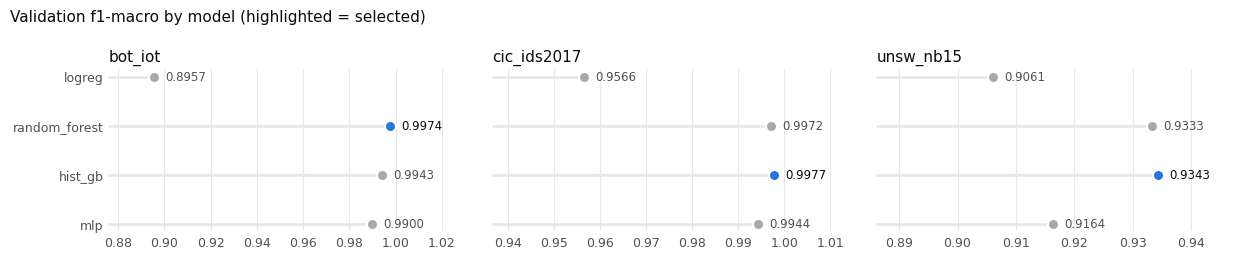

In [ ]:
import matplotlib.pyplot as plt
comp = {m: val_tab.pivot(index="model", columns="dataset", values=m).reindex(list(MODELS)) for m in ["f1_macro", "pr_auc", "mcc", "fpr"]}
rank = val_tab.assign(rank=val_tab.groupby("dataset")[SELECTION_METRIC].rank(ascending=False, method="min")) \
              .pivot(index="model", columns="dataset", values="rank").reindex(list(MODELS))
for m, t in comp.items():
    print(f"\n{m}"); display(t.round(4))
print("\nrank by", SELECTION_METRIC); display(rank.astype(int))
pd.concat({m: t for m, t in comp.items()}, names=["metric"]).to_csv(RES / "model_comparison.csv")

INK, MUTED, GRID, HIGHLIGHT, OTHER = "#0b0b0b", "#52514e", "#e8e7e2", "#2a78d6", "#a9a8a2"
order = list(MODELS)
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.2 * len(DATASETS), 2.6), sharey=True)
for ax, k in zip(np.atleast_1d(axes), DATASETS):
    vals = np.array([VALROWS[(k, m)][SELECTION_METRIC] for m in order])
    best = int(np.argmax(vals)); lo = max(0.0, vals.min() - 0.02); span = max(vals.max() - lo, 1e-3)
    for i, v in enumerate(vals):
        ax.hlines(i, lo, v, color=GRID, linewidth=2, zorder=1)
        ax.scatter(v, i, s=64, color=HIGHLIGHT if i == best else OTHER, zorder=3, edgecolor="white", linewidth=1.5)
        ax.text(v + 0.04 * span, i, f"{v:.4f}", ha="left", va="center", fontsize=8.5, color=INK if i == best else MUTED)
    ax.set_xlim(lo, vals.max() + 0.3 * span)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, color=INK)
    ax.set_title(k, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, labelsize=9, length=0); ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ax.spines.values(): s.set_visible(False)
    ax.invert_yaxis()
fig.suptitle(f"Validation {SELECTION_METRIC.replace('_', '-')} by model (highlighted = selected)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "validation_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

## 4.9 · Model selection

In [ ]:
SELECTED = {}
for k in DATASETS:
    t = val_tab[val_tab.dataset == k].sort_values([SELECTION_METRIC, "pr_auc", "fit_seconds"], ascending=[False, False, True])
    best = t.iloc[0]
    thr, score = tune_threshold(VAL[k][1], VALPROB[(k, best.model)], SELECTION_METRIC)
    SELECTED[k] = {"model": best.model, "params": MODELS[best.model], "val_" + SELECTION_METRIC: float(best[SELECTION_METRIC]),
                   "val_pr_auc": float(best.pr_auc), "tuned_threshold": thr, "val_" + SELECTION_METRIC + "_at_tuned": score,
                   "runner_up": t.iloc[1].model if len(t) > 1 else None,
                   "margin_over_runner_up": float(best[SELECTION_METRIC] - t.iloc[1][SELECTION_METRIC]) if len(t) > 1 else None}
    print(f"{k:<12} -> {best.model:<14} val {SELECTION_METRIC} {best[SELECTION_METRIC]:.4f} (runner-up {SELECTED[k]['runner_up']}, "
          f"+{SELECTED[k]['margin_over_runner_up']:.4f}) | tuned threshold {thr:.3f} -> {score:.4f}")
(RES / "model_selection.json").write_text(json.dumps(SELECTED, indent=2, default=str))

bot_iot      -> random_forest  val f1_macro 0.9974 (runner-up hist_gb, +0.0031) | tuned threshold 0.660 -> 0.9978
cic_ids2017  -> hist_gb        val f1_macro 0.9977 (runner-up random_forest, +0.0005) | tuned threshold 0.790 -> 0.9980
unsw_nb15    -> hist_gb        val f1_macro 0.9343 (runner-up random_forest, +0.0011) | tuned threshold 0.480 -> 0.9350


1486

## 4.10 · Final model retraining

In [ ]:
FINAL = {}
for k in DATASETS:
    name = SELECTED[k]["model"]
    Xa, ya, ca, _ = load_split(BASE, M3, k, "train"); Xb, yb, cb, _ = VAL[k]
    X = np.concatenate([Xa, Xb]); y = np.concatenate([ya, yb]); c = np.concatenate([ca, cb]); del Xa
    if FINAL_TRAIN_CAP and len(y) > FINAL_TRAIN_CAP:
        keep, _ = train_test_split(np.arange(len(y)), train_size=FINAL_TRAIN_CAP, stratify=_strat(c), random_state=SEED)
        X, y = X[np.sort(keep)], y[np.sort(keep)]
    path = MODEL_DIR / "final" / f"{k}__{name}.joblib"
    model, secs, cached = train_or_load(name, MODELS[name], X, y, path, SEED, FORCE_RETRAIN)
    FINAL[k] = {"model": name, "path": path, "n_train": int(len(y)), "fit_seconds": round(secs, 1), "attack_rate": float(y.mean())}
    print(f"{k:<12} {name:<14} {len(y):>10,} rows  fit {secs:8.1f}s{' (checkpoint)' if cached else ''} -> {path.relative_to(BASE)}")
    del X, y, model; gc.collect()

bot_iot      random_forest     768,333 rows  fit    189.9s (checkpoint) -> models/module4/final/bot_iot__random_forest.joblib
cic_ids2017  hist_gb         1,000,000 rows  fit     58.4s -> models/module4/final/cic_ids2017__hist_gb.joblib
unsw_nb15    hist_gb            99,268 rows  fit     15.9s -> models/module4/final/unsw_nb15__hist_gb.joblib


## 4.11 · Held-out test evaluation

In [ ]:
TEST_ROWS, PERCLASS = [], []
for k in DATASETS:
    model = joblib.load(FINAL[k]["path"])["model"]
    Xte, yte, cte, rte = load_split(BASE, M3, k, "test")
    t0 = time.time(); p = predict_proba1(model, Xte); ps = time.time() - t0
    pd.DataFrame({"row": rte, "y_binary": yte, "y_class": cte, "prob_attack": p}).to_parquet(RES / "test_predictions" / f"{k}.parquet", index=False)
    for label, thr in [("default_0.5", 0.5), ("tuned_on_val", SELECTED[k]["tuned_threshold"])]:
        m = binary_metrics(yte, p, thr); m.update(dataset=k, model=FINAL[k]["model"], threshold_rule=label, predict_seconds=round(ps, 1), n_test=int(len(yte)))
        TEST_ROWS.append(m)
    pc = per_class_detection(cte, yte, p, SELECTED[k]["tuned_threshold"]); pc.insert(0, "dataset", k); PERCLASS.append(pc)
    del model, Xte; gc.collect()
test_tab = pd.DataFrame(TEST_ROWS)[["dataset", "model", "threshold_rule", "threshold", "f1_macro", "f1_attack", "precision_attack",
                                    "recall_attack", "mcc", "roc_auc", "pr_auc", "balanced_accuracy", "accuracy", "fpr", "fnr",
                                    "tp", "fp", "tn", "fn", "n_test", "predict_seconds"]]
test_tab.to_csv(RES / "test_metrics.csv", index=False)
perclass = pd.concat(PERCLASS, ignore_index=True); perclass.to_csv(RES / "test_per_class_detection.csv", index=False)
display(test_tab.style.format({c: "{:.4f}" for c in test_tab.columns[3:15]}).hide(axis="index"))
print("Per-class detection on test (tuned threshold): detection_rate for attack classes, false_alarm_rate for benign")
display(perclass.round(4))

dataset,model,threshold_rule,threshold,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,accuracy,fpr,fnr,tp,fp,tn,fn,n_test,predict_seconds
bot_iot,random_forest,default_0.5,0.5000,0.9982,1.0000,1.0000,1.0000,0.9963,1.0000,1.0000,0.9978,0.9999,0.0044,0.0000,134214,6,1365,4,135589,0.500000
bot_iot,random_forest,tuned_on_val,0.6600,0.9978,1.0000,1.0000,0.9999,0.9956,1.0000,1.0000,0.9992,0.9999,0.0015,0.0001,134208,2,1369,10,135589,0.500000
cic_ids2017,hist_gb,default_0.5,0.5000,0.9979,0.9965,0.9936,0.9993,0.9958,0.9999,0.9988,0.9991,0.9989,0.0012,0.0007,50394,323,279039,34,329790,4.500000
cic_ids2017,hist_gb,tuned_on_val,0.7900,0.9985,0.9974,0.9973,0.9974,0.9969,0.9999,0.9988,0.9985,0.9992,0.0005,0.0026,50299,135,279227,129,329790,4.500000
unsw_nb15,hist_gb,default_0.5,0.5000,0.8590,0.8888,0.8147,0.9777,0.7409,0.9775,0.9831,0.8526,0.8653,0.2725,0.0223,44322,10083,26917,1010,82332,1.700000
unsw_nb15,hist_gb,tuned_on_val,0.4800,0.8544,0.8861,0.8089,0.9795,0.7345,0.9775,0.9831,0.8480,0.8613,0.2835,0.0205,44404,10490,26510,928,82332,1.700000


Per-class detection on test (tuned threshold): detection_rate for attack classes, false_alarm_rate for benign


,dataset,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,benign,1371,0,NaN,0.0015
1,bot_iot,ddos,44842,1,1.0000,NaN
2,bot_iot,dos,44743,1,1.0000,NaN
3,bot_iot,reconnaissance,44395,1,1.0000,NaN
4,bot_iot,theft,238,1,0.9748,NaN
5,cic_ids2017,benign,279362,0,NaN,0.0005
6,cic_ids2017,bot,210,1,0.6667,NaN
7,cic_ids2017,ddos,19202,1,0.9995,NaN
8,cic_ids2017,dos_goldeneye,1543,1,1.0000,NaN
9,cic_ids2017,dos_hulk,25903,1,0.9993,NaN


## 4.12 · Final performance summary

In [ ]:
lines = ["# Module 4 — Classical ML results", "",
         f"Binary detection (benign vs attack). Models compared on validation after training on a stratified {DEV_TRAIN_CAP:,}-row subsample of train; "
         f"the selected model is retrained on train + val (cap {FINAL_TRAIN_CAP:,}) and evaluated once on test. Seed {SEED}.", "",
         "## Validation (model comparison)", "", "| Dataset | " + " | ".join(MODELS) + " |", "|---|" + "---|" * len(MODELS)]
for k in DATASETS:
    lines.append(f"| {k} | " + " | ".join(f"{VALROWS[(k, m)][SELECTION_METRIC]:.4f}" for m in MODELS) + " |")
lines += ["", f"Values are validation {SELECTION_METRIC}.", "", "## Held-out test (selected model)", "",
          "| Dataset | Model | Threshold | Macro-F1 | Attack F1 | Precision | Recall | MCC | ROC-AUC | PR-AUC | FPR | FNR |",
          "|---|---|---|---|---|---|---|---|---|---|---|---|"]
for _, r in test_tab.iterrows():
    lines.append(f"| {r.dataset} | {r.model} | {r.threshold:.3f} | {r.f1_macro:.4f} | {r.f1_attack:.4f} | {r.precision_attack:.4f} | "
                 f"{r.recall_attack:.4f} | {r.mcc:.4f} | {r.roc_auc:.4f} | {r.pr_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |")
weak = perclass[(perclass.detection_rate < 0.9)]
lines += ["", "## Attack classes detected below 90% on test (tuned threshold)", ""]
lines += [f"- {r.dataset} / {r.y_class}: {r.detection_rate:.3f} of {r.rows:,} rows" for _, r in weak.iterrows()] or ["- none"]
(RES / "summary.md").write_text("\n".join(lines))
manifest = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "module": "4 - classical ML",
            "module3_manifest_created": M3["created_utc"], "selection": SELECTED,
            "final_models": {k: {**{kk: vv for kk, vv in v.items() if kk != "path"}, "path": str(v["path"].relative_to(BASE)),
                                 "sha256": sha256_file(v["path"])} for k, v in FINAL.items()},
            "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "cpus": os.cpu_count(), "platform": platform.platform()}}
(RES / "module4_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("\n".join(lines))

# Module 4 — Classical ML results

Binary detection (benign vs attack). Models compared on validation after training on a stratified 300,000-row subsample of train; the selected model is retrained on train + val (cap 1,000,000) and evaluated once on test. Seed 42.

## Validation (model comparison)

| Dataset | logreg | random_forest | hist_gb | mlp |
|---|---|---|---|---|
| bot_iot | 0.8957 | 0.9974 | 0.9943 | 0.9900 |
| cic_ids2017 | 0.9566 | 0.9972 | 0.9977 | 0.9944 |
| unsw_nb15 | 0.9061 | 0.9333 | 0.9343 | 0.9164 |

Values are validation f1_macro.

## Held-out test (selected model)

| Dataset | Model | Threshold | Macro-F1 | Attack F1 | Precision | Recall | MCC | ROC-AUC | PR-AUC | FPR | FNR |
|---|---|---|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | 0.500 | 0.9982 | 1.0000 | 1.0000 | 1.0000 | 0.9963 | 1.0000 | 1.0000 | 0.0044 | 0.0000 |
| bot_iot | random_forest | 0.660 | 0.9978 | 1.0000 | 1.0000 | 0.9999 | 0.9956 | 1.0000 | 1.0000 | 0.0015 | 0.0001 |
| cic_ids

# Module 5: Neural Network / MLP Experiments

## 5.1 · MLP configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
SEEDS = [42, 7, 2026]
MAX_EPOCHS, PATIENCE = 40, 6
CLASS_WEIGHTING = "balanced"
SELECTION_METRIC = "f1_macro"
CPU_TRAIN_CAP = 300_000
FORCE_RETRAIN = False

EXPERIMENTS = {
    "mlp_128_64":     {"hidden": [128, 64],      "dropout": 0.1, "batchnorm": False, "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 2048},
    "mlp_256_128_64": {"hidden": [256, 128, 64], "dropout": 0.2, "batchnorm": True,  "lr": 1e-3, "weight_decay": 1e-5, "batch_size": 2048},
    "mlp_512_256":    {"hidden": [512, 256],     "dropout": 0.3, "batchnorm": True,  "lr": 5e-4, "weight_decay": 1e-4, "batch_size": 4096},
}

## 5.2 · GPU setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
try:
    from IPython.display import display
except ImportError:
    display = print

import os, gc, json, time, copy, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix)

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42):
    info = m3["datasets"][key]; feats = info["feature_names"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=feats + ["y_binary", "y_class", "row"])
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    return (d[feats].to_numpy(dtype=np.float32), d["y_binary"].to_numpy().astype(int),
            d["y_class"].astype(str).to_numpy(), d["row"].to_numpy())

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": thr, "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    scores = [(t, binary_metrics(y, prob, t)[metric]) for t in grid]
    best = max(scores, key=lambda s: (s[1], -abs(s[0] - 0.5)))
    return float(best[0]), float(best[1])

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.1, batchnorm=False):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

def n_params(model):
    return int(sum(p.numel() for p in model.parameters()))

@torch.no_grad()
def predict_logits(model, X, device, batch=65536):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = X[i:i + batch]
        xb = xb if isinstance(xb, torch.Tensor) else torch.from_numpy(xb)
        out.append(model(xb.to(device, non_blocking=True)).float().cpu())
    return torch.cat(out)

def predict_proba(model, X, device):
    return torch.sigmoid(predict_logits(model, X, device)).numpy().astype(np.float32)

def train_mlp(exp, Xtr, ytr, Xva, yva, device, seed, max_epochs, patience, class_weighting="balanced",
              fixed_epochs=None, log=print):
    set_seed(seed)
    model = MLP(Xtr.shape[1], exp["hidden"], exp["dropout"], exp["batchnorm"]).to(device)
    pos = float(ytr.mean())
    pos_weight = torch.tensor([(1 - pos) / pos if class_weighting == "balanced" else 1.0], device=device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.AdamW(model.parameters(), lr=exp["lr"], weight_decay=exp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2) if fixed_epochs is None else None
    Xt = torch.from_numpy(Xtr).to(device); yt = torch.from_numpy(ytr.astype(np.float32)).to(device)
    Xv = torch.from_numpy(Xva).to(device) if Xva is not None else None
    yv_t = torch.from_numpy(yva.astype(np.float32)).to(device) if yva is not None else None
    g = torch.Generator(device="cpu").manual_seed(seed)
    n, bs = len(Xt), exp["batch_size"]
    hist, best, best_state, best_epoch, bad = [], -1.0, None, 0, 0
    epochs = fixed_epochs or max_epochs
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(n, generator=g).to(device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xt[idx]), yt[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        row = {"epoch": ep, "train_loss": tot / n, "lr": opt.param_groups[0]["lr"]}
        if Xv is not None:
            logits = predict_logits(model, Xv, device)
            row["val_loss"] = float(loss_fn(logits.to(device), yv_t).item())
            p = torch.sigmoid(logits).numpy()
            row["val_f1_macro"] = f1_score(yva, (p >= 0.5).astype(int), average="macro", zero_division=0)
            row["val_pr_auc"] = average_precision_score(yva, p)
        row["seconds"] = time.time() - t0
        hist.append(row)
        if Xv is not None:
            sched.step(row["val_f1_macro"])
            if row["val_f1_macro"] > best + 1e-5:
                best, best_epoch, bad = row["val_f1_macro"], ep, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
            if ep == 1 or ep % 5 == 0 or bad == 0:
                log(f"      epoch {ep:>2}  train {row['train_loss']:.4f}  val {row['val_loss']:.4f}  "
                    f"F1 {row['val_f1_macro']:.4f}  PR-AUC {row['val_pr_auc']:.4f}  {row['seconds']:.1f}s{'  *' if bad == 0 else ''}")
            if bad >= patience:
                log(f"      early stop at epoch {ep} (best epoch {best_epoch})"); break
    if best_state is None:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; best_epoch = len(hist)
    model.load_state_dict(best_state)
    del Xt, yt, Xv; torch.cuda.empty_cache() if device.type == "cuda" else None
    return model, pd.DataFrame(hist), best_epoch, float(pos_weight.item())

def save_ckpt(path, model, exp, hist, best_epoch, pos_weight, seed, n_train, n_features, extra=None):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": model.state_dict(), "exp": exp, "history": hist.to_dict("list"), "best_epoch": best_epoch,
                "pos_weight": pos_weight, "seed": seed, "n_train": n_train, "n_features": n_features,
                "torch": torch.__version__, **(extra or {})}, path)

def load_ckpt(path, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = MLP(ck["n_features"], ck["exp"]["hidden"], ck["exp"]["dropout"], ck["exp"]["batchnorm"]).to(device)
    m.load_state_dict(ck["state_dict"])
    return m, pd.DataFrame(ck["history"]), ck

def mcnemar(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    if b + c == 0:
        return b, c, 1.0
    if b + c < 25:
        p = stats.binomtest(b, b + c, 0.5).pvalue
    else:
        p = stats.chi2.sf((abs(b - c) - 1) ** 2 / (b + c), 1)
    return b, c, float(p)

def _macro_f1_counts(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return (f1a + f1b) / 2

def bootstrap_f1_diff(y, pred_a, pred_b, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pa, pb = y.astype(bool), pred_a.astype(bool), pred_b.astype(bool)
    n, diffs = len(y), []
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        diffs.append(_macro_f1_counts(y[idx], pb[idx]) - _macro_f1_counts(y[idx], pa[idx]))
    d = np.concatenate(diffs)
    point = float(_macro_f1_counts(y[None], pb[None])[0] - _macro_f1_counts(y[None], pa[None])[0])
    return point, float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

BASE      = Path("/content/drive/MyDrive") / PROJECT_DIR
M3        = json.loads((BASE / "results" / "module3" / "module3_manifest.json").read_text())
M4_RES    = BASE / "results" / "module4"
MODEL_DIR = BASE / "models" / "module5"
RES       = BASE / "results" / "module5"
for p in (MODEL_DIR / "dev", MODEL_DIR / "final", RES / "histories", RES / "val_probs", RES / "test_predictions", RES / "figures"):
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    GPU = {"name": props.name, "memory_GB": round(props.total_memory / 2**30, 1), "cuda": torch.version.cuda}
    print(f"GPU: {GPU['name']} ({GPU['memory_GB']} GB), CUDA {GPU['cuda']}, torch {torch.__version__}")
else:
    GPU = None
    warnings.warn(f"No GPU found - training on CPU with train capped at {CPU_TRAIN_CAP:,} rows. Use Runtime -> Change runtime type -> T4 GPU.")
TRAIN_CAP = None if GPU else CPU_TRAIN_CAP
(RES / "mlp_config.json").write_text(json.dumps({
    "datasets": DATASETS, "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "class_weighting": CLASS_WEIGHTING,
    "selection_metric": SELECTION_METRIC, "train_cap": TRAIN_CAP, "experiments": EXPERIMENTS, "device": GPU or "cpu",
    "torch": torch.__version__, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2))
DATA = {}
for k in DATASETS:
    DATA[k] = {"train": load_split(BASE, M3, k, "train", cap=TRAIN_CAP), "val": load_split(BASE, M3, k, "val")}
    Xtr, ytr = DATA[k]["train"][:2]
    print(f"{k:<12} train {Xtr.shape[0]:>9,} x {Xtr.shape[1]:<3} | val {len(DATA[k]['val'][1]):>8,} | attack rate {ytr.mean():.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4 (14.6 GB), CUDA 13.0, torch 2.14.1+cu130
bot_iot      train   632,744 x 46  | val  135,589 | attack rate 0.990
cic_ids2017  train 1,539,015 x 69  | val  329,790 | attack rate 0.153
unsw_nb15    train    84,377 x 81  | val   14,891 | attack rate 0.480


## 5.3 · Training

In [ ]:
RUNS = {}
for k in DATASETS:
    Xtr, ytr, _, _ = DATA[k]["train"]; Xva, yva, _, _ = DATA[k]["val"]
    for name, exp in EXPERIMENTS.items():
        for seed in SEEDS:
            path = MODEL_DIR / "dev" / f"{k}__{name}__s{seed}.pt"
            if path.exists() and not FORCE_RETRAIN:
                model, hist, ck = load_ckpt(path, DEVICE); best_epoch, secs = ck["best_epoch"], ck["train_seconds"]
                print(f"{k:<12} {name:<15} seed {seed:<5} loaded checkpoint (best epoch {best_epoch})")
            else:
                print(f"{k:<12} {name:<15} seed {seed:<5} training on {DEVICE.type}...")
                t0 = time.time()
                model, hist, best_epoch, pw = train_mlp(exp, Xtr, ytr, Xva, yva, DEVICE, seed, MAX_EPOCHS, PATIENCE, CLASS_WEIGHTING)
                secs = time.time() - t0
                save_ckpt(path, model, exp, hist, best_epoch, pw, seed, len(ytr), Xtr.shape[1], {"train_seconds": secs, "dataset": k})
                print(f"      done in {secs:.0f}s, best epoch {best_epoch}")
            hist.to_csv(RES / "histories" / f"{k}__{name}__s{seed}.csv", index=False)
            p = predict_proba(model, Xva, DEVICE); np.save(RES / "val_probs" / f"{k}__{name}__s{seed}.npy", p)
            RUNS[(k, name, seed)] = {"hist": hist, "best_epoch": best_epoch, "train_seconds": secs, "params": n_params(model), "val_prob": p}
            del model; gc.collect()

bot_iot      mlp_128_64      seed 42    loaded checkpoint (best epoch 3)
bot_iot      mlp_128_64      seed 7     loaded checkpoint (best epoch 4)
bot_iot      mlp_128_64      seed 2026  loaded checkpoint (best epoch 4)
bot_iot      mlp_256_128_64  seed 42    loaded checkpoint (best epoch 5)
bot_iot      mlp_256_128_64  seed 7     loaded checkpoint (best epoch 3)
bot_iot      mlp_256_128_64  seed 2026  loaded checkpoint (best epoch 5)
bot_iot      mlp_512_256     seed 42    loaded checkpoint (best epoch 3)
bot_iot      mlp_512_256     seed 7     loaded checkpoint (best epoch 3)
bot_iot      mlp_512_256     seed 2026  loaded checkpoint (best epoch 5)
cic_ids2017  mlp_128_64      seed 42    training on cuda...
      epoch  1  train 0.1144  val 0.0487  F1 0.9818  PR-AUC 0.9976  2.5s  *
      epoch  2  train 0.0472  val 0.0385  F1 0.9896  PR-AUC 0.9985  1.8s  *
      epoch  3  train 0.0388  val 0.0310  F1 0.9926  PR-AUC 0.9989  1.7s  *
      epoch  5  train 0.0309  val 0.0264  F1 0.9929  PR

## 5.4 · Validation

In [ ]:
rows = []
for (k, name, seed), r in RUNS.items():
    m = binary_metrics(DATA[k]["val"][1], r["val_prob"])
    m.update(dataset=k, experiment=name, seed=seed, best_epoch=r["best_epoch"], epochs_run=len(r["hist"]),
             train_seconds=round(r["train_seconds"], 1), params=r["params"])
    rows.append(m)
val_runs = pd.DataFrame(rows)
val_runs.to_csv(RES / "validation_runs.csv", index=False)
agg = val_runs.groupby(["dataset", "experiment"]).agg(
    f1_macro_mean=("f1_macro", "mean"), f1_macro_std=("f1_macro", "std"), pr_auc_mean=("pr_auc", "mean"),
    mcc_mean=("mcc", "mean"), fpr_mean=("fpr", "mean"), fnr_mean=("fnr", "mean"), best_epoch_mean=("best_epoch", "mean"),
    train_seconds_mean=("train_seconds", "mean"), params=("params", "first")).reset_index()
agg.to_csv(RES / "validation_summary.csv", index=False)
display(agg.style.format({c: "{:.4f}" for c in ["f1_macro_mean", "f1_macro_std", "pr_auc_mean", "mcc_mean", "fpr_mean", "fnr_mean"]}).hide(axis="index"))

dataset,experiment,f1_macro_mean,f1_macro_std,pr_auc_mean,mcc_mean,fpr_mean,fnr_mean,best_epoch_mean,train_seconds_mean,params
bot_iot,mlp_128_64,0.9688,0.0085,1.0000,0.9389,0.0117,0.0012,3.666667,8.266667,14337
bot_iot,mlp_256_128_64,0.9644,0.0044,1.0000,0.9308,0.0071,0.0015,4.333333,10.000000,54145
bot_iot,mlp_512_256,0.9588,0.0045,1.0000,0.9202,0.0078,0.0017,3.666667,4.900000,157185
cic_ids2017,mlp_128_64,0.9961,0.0001,0.9996,0.9922,0.0014,0.0054,26.666667,62.333333,17281
cic_ids2017,mlp_256_128_64,0.9959,0.0000,0.9996,0.9917,0.0016,0.0053,24.333333,81.966667,60033
cic_ids2017,mlp_512_256,0.9955,0.0002,0.9996,0.9910,0.0018,0.0052,26.666667,44.766667,168961
unsw_nb15,mlp_128_64,0.9157,0.0019,0.9734,0.8347,0.1221,0.0434,14.000000,2.266667,18817
unsw_nb15,mlp_256_128_64,0.9193,0.0016,0.9769,0.8397,0.1003,0.0594,25.000000,4.800000,63105
unsw_nb15,mlp_512_256,0.9177,0.0012,0.9750,0.8369,0.1068,0.0557,31.333333,2.933333,175105


## 5.5 · Training-history analysis

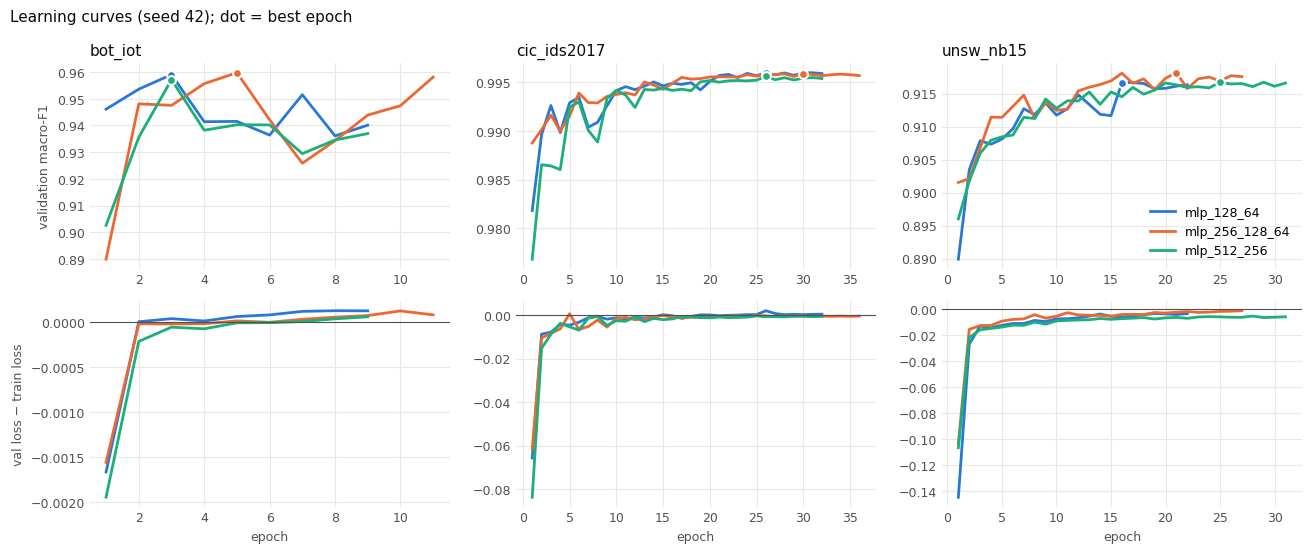

epochs_run  best_epoch  gap_at_best  gap_at_end  \
dataset     experiment                                                        
bot_iot     mlp_128_64          9.6667      3.6667       0.0001      0.0001   
            mlp_256_128_64     10.3333      4.3333       0.0000      0.0001   
            mlp_512_256         9.6667      3.6667      -0.0000      0.0001   
cic_ids2017 mlp_128_64         32.6667     26.6667       0.0008      0.0003   
            mlp_256_128_64     30.3333     24.3333      -0.0005     -0.0003   
            mlp_512_256        32.6667     26.6667      -0.0011     -0.0006   
unsw_nb15   mlp_128_64         20.0000     14.0000      -0.0071     -0.0036   
            mlp_256_128_64     30.3333     25.0000      -0.0017     -0.0002   
            mlp_512_256        36.0000     31.3333      -0.0048     -0.0047   

                            sec_per_epoch  
dataset     experiment                     
bot_iot     mlp_128_64             0.6451  
            mlp_256_128_64         0.9628  
            mlp_512_256            0.5082  
cic_ids2017 mlp_128_64             1.8380  
            mlp_256_128_64         2.6971  
            mlp_512_256            1.3657  
unsw_nb15   mlp_128_64             0.1101  
            mlp_256_128_64         0.1584  
            mlp_512_256            0.0796

In [ ]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
COLOR = {name: SERIES[i % len(SERIES)] for i, name in enumerate(EXPERIMENTS)}
s0 = SEEDS[0]
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.4 * len(DATASETS), 5.6), sharex=False)
for j, k in enumerate(DATASETS):
    for name in EXPERIMENTS:
        h = RUNS[(k, name, s0)]["hist"]; be = RUNS[(k, name, s0)]["best_epoch"]
        a = axes[0, j]; a.plot(h.epoch, h.val_f1_macro, color=COLOR[name], linewidth=2, label=name)
        a.scatter([be], [h.val_f1_macro[h.epoch == be].iloc[0]], s=40, color=COLOR[name], edgecolor="white", linewidth=1.5, zorder=3)
        b = axes[1, j]; b.plot(h.epoch, h.val_loss - h.train_loss, color=COLOR[name], linewidth=2, label=name)
    axes[0, j].set_title(k, loc="left", fontsize=11, color=INK)
    axes[1, j].axhline(0, color=MUTED, linewidth=0.8)
    for a in axes[:, j]:
        a.grid(color=GRID, linewidth=0.8); a.set_axisbelow(True); a.tick_params(colors=MUTED, labelsize=9, length=0)
        for s in a.spines.values(): s.set_visible(False)
    axes[1, j].set_xlabel("epoch", color=MUTED, fontsize=9)
axes[0, 0].set_ylabel("validation macro-F1", color=MUTED, fontsize=9)
axes[1, 0].set_ylabel("val loss − train loss", color=MUTED, fontsize=9)
axes[0, -1].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle(f"Learning curves (seed {s0}); dot = best epoch", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "learning_curves.png", dpi=200, bbox_inches="tight"); plt.show()

hist_tab = []
for (k, name, seed), r in RUNS.items():
    h = r["hist"]; be = r["best_epoch"]; hb = h[h.epoch == be].iloc[0]
    hist_tab.append({"dataset": k, "experiment": name, "seed": seed, "epochs_run": len(h), "best_epoch": be,
                     "stopped_early": len(h) < MAX_EPOCHS, "train_loss_at_best": hb.train_loss, "val_loss_at_best": hb.val_loss,
                     "gap_at_best": hb.val_loss - hb.train_loss, "gap_at_end": h.val_loss.iloc[-1] - h.train_loss.iloc[-1],
                     "sec_per_epoch": h.seconds.mean()})
hist_tab = pd.DataFrame(hist_tab); hist_tab.to_csv(RES / "training_history_summary.csv", index=False)
display(hist_tab.groupby(["dataset", "experiment"])[["epochs_run", "best_epoch", "gap_at_best", "gap_at_end", "sec_per_epoch"]].mean().round(4))

## 5.6 · Hyperparameter / experiment comparison

In [ ]:
SELECTED = {}
for k in DATASETS:
    t = agg[agg.dataset == k].sort_values(["f1_macro_mean", "pr_auc_mean"], ascending=False)
    best = t.iloc[0]; name = best.experiment
    thr, score = tune_threshold(DATA[k]["val"][1], RUNS[(k, name, SEEDS[0])]["val_prob"], SELECTION_METRIC)
    SELECTED[k] = {"experiment": name, "config": EXPERIMENTS[name], "val_f1_macro_mean": float(best.f1_macro_mean),
                   "val_f1_macro_std": float(best.f1_macro_std) if pd.notna(best.f1_macro_std) else 0.0,
                   "best_epoch_seed0": int(RUNS[(k, name, SEEDS[0])]["best_epoch"]), "tuned_threshold": thr, "val_f1_macro_at_tuned": score,
                   "runner_up": t.iloc[1].experiment if len(t) > 1 else None,
                   "margin": float(best.f1_macro_mean - t.iloc[1].f1_macro_mean) if len(t) > 1 else None}
    print(f"{k:<12} -> {name:<15} val F1 {best.f1_macro_mean:.4f} ± {SELECTED[k]['val_f1_macro_std']:.4f} "
          f"(runner-up {SELECTED[k]['runner_up']}, +{SELECTED[k]['margin']:.4f}) | threshold {thr:.3f}")
(RES / "experiment_selection.json").write_text(json.dumps(SELECTED, indent=2))
pv = agg.pivot(index="experiment", columns="dataset", values="f1_macro_mean").reindex(list(EXPERIMENTS))
display(pv.round(4))

bot_iot      -> mlp_128_64      val F1 0.9688 ± 0.0085 (runner-up mlp_256_128_64, +0.0044) | threshold 0.020
cic_ids2017  -> mlp_128_64      val F1 0.9961 ± 0.0001 (runner-up mlp_256_128_64, +0.0002) | threshold 0.700
unsw_nb15    -> mlp_256_128_64  val F1 0.9193 ± 0.0016 (runner-up mlp_512_256, +0.0016) | threshold 0.500


dataset,bot_iot,cic_ids2017,unsw_nb15
experiment,,,
mlp_128_64,0.9688,0.9961,0.9157
mlp_256_128_64,0.9644,0.9959,0.9193
mlp_512_256,0.9588,0.9955,0.9177


## 5.7 · Final MLP evaluation

In [ ]:
FINAL, TEST_ROWS, PERCLASS = {}, [], []
for k in DATASETS:
    sel = SELECTED[k]; name = sel["experiment"]; exp = EXPERIMENTS[name]
    path = MODEL_DIR / "final" / f"{k}__{name}.pt"
    if path.exists() and not FORCE_RETRAIN:
        model, _, ck = load_ckpt(path, DEVICE); secs = ck["train_seconds"]; print(f"{k:<12} {name:<15} loaded final checkpoint")
    else:
        Xa, ya, ca, _ = DATA[k]["train"]; Xb, yb, cb, _ = DATA[k]["val"]
        X = np.concatenate([Xa, Xb]); y = np.concatenate([ya, yb])
        print(f"{k:<12} {name:<15} retraining on train+val ({len(y):,} rows) for {sel['best_epoch_seed0']} epochs...")
        t0 = time.time()
        model, hist, _, pw = train_mlp(exp, X, y, None, None, DEVICE, SEEDS[0], MAX_EPOCHS, PATIENCE, CLASS_WEIGHTING,
                                       fixed_epochs=sel["best_epoch_seed0"])
        secs = time.time() - t0
        save_ckpt(path, model, exp, hist, sel["best_epoch_seed0"], pw, SEEDS[0], len(y), X.shape[1], {"train_seconds": secs, "dataset": k})
        del X, y
    Xte, yte, cte, rte = load_split(BASE, M3, k, "test")
    p = predict_proba(model, Xte, DEVICE)
    pd.DataFrame({"row": rte, "y_binary": yte, "y_class": cte, "prob_attack": p}).to_parquet(RES / "test_predictions" / f"{k}.parquet", index=False)
    for label, thr in [("default_0.5", 0.5), ("tuned_on_val", sel["tuned_threshold"])]:
        m = binary_metrics(yte, p, thr); m.update(dataset=k, model=f"torch_{name}", threshold_rule=label, n_test=int(len(yte)))
        TEST_ROWS.append(m)
    pc = per_class_detection(cte, yte, p, sel["tuned_threshold"]); pc.insert(0, "dataset", k); PERCLASS.append(pc)
    FINAL[k] = {"experiment": name, "path": path, "train_seconds": round(secs, 1), "params": n_params(model)}
    del model, Xte; gc.collect()
test_tab = pd.DataFrame(TEST_ROWS)[["dataset", "model", "threshold_rule", "threshold", "f1_macro", "f1_attack", "precision_attack",
                                    "recall_attack", "mcc", "roc_auc", "pr_auc", "balanced_accuracy", "fpr", "fnr", "tp", "fp", "tn", "fn", "n_test"]]
test_tab.to_csv(RES / "test_metrics.csv", index=False)
perclass = pd.concat(PERCLASS, ignore_index=True); perclass.to_csv(RES / "test_per_class_detection.csv", index=False)
display(test_tab.style.format({c: "{:.4f}" for c in test_tab.columns[3:14]}).hide(axis="index"))
display(perclass.round(4))

bot_iot      mlp_128_64      loaded final checkpoint
cic_ids2017  mlp_128_64      retraining on train+val (1,868,805 rows) for 26 epochs...
unsw_nb15    mlp_256_128_64  retraining on train+val (99,268 rows) for 21 epochs...


dataset,model,threshold_rule,threshold,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,fpr,fnr,tp,fp,tn,fn,n_test
bot_iot,torch_mlp_128_64,default_0.5,0.5000,0.9739,0.9994,1.0000,0.9989,0.9489,0.9998,1.0000,0.9976,0.0036,0.0011,134074,5,1366,144,135589
bot_iot,torch_mlp_128_64,tuned_on_val,0.0200,0.9880,0.9998,0.9999,0.9997,0.9760,0.9998,1.0000,0.9925,0.0146,0.0003,134172,20,1351,46,135589
cic_ids2017,torch_mlp_128_64,default_0.5,0.5000,0.9926,0.9874,0.9795,0.9955,0.9852,0.9999,0.9995,0.9959,0.0038,0.0045,50199,1049,278313,229,329790
cic_ids2017,torch_mlp_128_64,tuned_on_val,0.7000,0.9943,0.9904,0.9872,0.9935,0.9886,0.9999,0.9995,0.9956,0.0023,0.0065,50102,650,278712,326,329790
unsw_nb15,torch_mlp_256_128_64,default_0.5,0.5000,0.8589,0.8896,0.8119,0.9838,0.7438,0.9809,0.9860,0.8523,0.2793,0.0162,44599,10333,26667,733,82332
unsw_nb15,torch_mlp_256_128_64,tuned_on_val,0.5000,0.8589,0.8896,0.8119,0.9838,0.7438,0.9809,0.9860,0.8523,0.2793,0.0162,44599,10333,26667,733,82332


,dataset,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,benign,1371,0,NaN,0.0146
1,bot_iot,ddos,44842,1,0.9999,NaN
2,bot_iot,dos,44743,1,1.0000,NaN
3,bot_iot,reconnaissance,44395,1,0.9993,NaN
4,bot_iot,theft,238,1,0.9622,NaN
5,cic_ids2017,benign,279362,0,NaN,0.0023
6,cic_ids2017,bot,210,1,0.4714,NaN
7,cic_ids2017,ddos,19202,1,0.9997,NaN
8,cic_ids2017,dos_goldeneye,1543,1,0.9994,NaN
9,cic_ids2017,dos_hulk,25903,1,0.9946,NaN


## 5.8 · Comparison with classical models

,0,1,2
dataset,bot_iot,cic_ids2017,unsw_nb15
classical_model,random_forest,hist_gb,hist_gb
mlp_experiment,mlp_128_64,mlp_128_64,mlp_256_128_64
classical_test_f1_macro,0.9978,0.99846,0.85444
mlp_test_f1_macro,0.98796,0.9943,0.8589
f1_diff_mlp_minus_classical,-0.00984,-0.00415,0.00446
diff_ci95_low,-0.01281,-0.00449,0.0029
diff_ci95_high,-0.00719,-0.00382,0.00614
classical_pr_auc,1.0,0.99881,0.98309
mlp_pr_auc,1.0,0.9995,0.98599


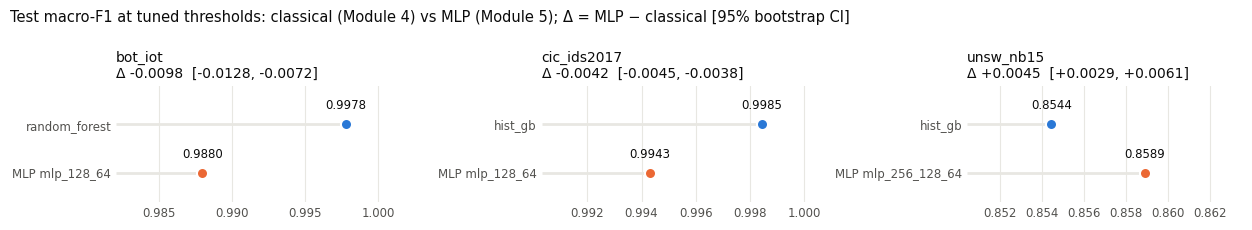

# Module 5 — MLP experiments

PyTorch MLPs on GPU Tesla T4; 3 experiments × 3 seeds per dataset, early stopping on validation macro-F1 (patience 6), class-balanced BCE. Final model retrained on train + val for its best epoch count.

## Validation macro-F1 (mean ± std over seeds)

| Experiment | bot_iot | cic_ids2017 | unsw_nb15 |
|---|---|---|---|
| mlp_128_64 | 0.9688 ± 0.0085 | 0.9961 ± 0.0001 | 0.9157 ± 0.0019 |
| mlp_256_128_64 | 0.9644 ± 0.0044 | 0.9959 ± 0.0000 | 0.9193 ± 0.0016 |
| mlp_512_256 | 0.9588 ± 0.0045 | 0.9955 ± 0.0002 | 0.9177 ± 0.0012 |

## Test: MLP vs classical (tuned thresholds)

| Dataset | Classical | MLP | Classical F1 | MLP F1 | Δ F1 [95% CI] | MLP FPR | Classical FPR | McNemar p |
|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | mlp_128_64 | 0.9978 | 0.9880 | -0.0098 [-0.0128, -0.0072] | 0.0146 | 0.0015 | 3.47e-11 |
| cic_ids2017 | hist_gb | mlp_128_64 | 0.9985 | 0.9943 | -0.0042 [-0.0045, -0.0038] | 0.0023 | 0.0005 | 1.63e-121 |
| unsw_nb15 

In [ ]:
m4_sel = json.loads((M4_RES / "model_selection.json").read_text())
m4_test = pd.read_csv(M4_RES / "test_metrics.csv"); m4_val = pd.read_csv(M4_RES / "validation_metrics.csv")
CMP = []
for k in DATASETS:
    a = pd.read_parquet(M4_RES / "test_predictions" / f"{k}.parquet"); b = pd.read_parquet(RES / "test_predictions" / f"{k}.parquet")
    assert (a.row.values == b.row.values).all(), "test rows differ between Module 4 and Module 5"
    y = a.y_binary.values
    pa = (a.prob_attack.values >= m4_sel[k]["tuned_threshold"]).astype(int)
    pb = (b.prob_attack.values >= SELECTED[k]["tuned_threshold"]).astype(int)
    b_, c_, pval = mcnemar(y, pa, pb)
    diff, lo, hi = bootstrap_f1_diff(y, pa, pb)
    ra = m4_test[(m4_test.dataset == k) & (m4_test.threshold_rule == "tuned_on_val")].iloc[0]
    rb = test_tab[(test_tab.dataset == k) & (test_tab.threshold_rule == "tuned_on_val")].iloc[0]
    sk = m4_val[(m4_val.dataset == k) & (m4_val.model == "mlp")].iloc[0]
    CMP.append({"dataset": k, "classical_model": m4_sel[k]["model"], "mlp_experiment": SELECTED[k]["experiment"],
                "classical_test_f1_macro": ra.f1_macro, "mlp_test_f1_macro": rb.f1_macro, "f1_diff_mlp_minus_classical": diff,
                "diff_ci95_low": lo, "diff_ci95_high": hi, "classical_pr_auc": ra.pr_auc, "mlp_pr_auc": rb.pr_auc,
                "classical_fpr": ra.fpr, "mlp_fpr": rb.fpr, "classical_fnr": ra.fnr, "mlp_fnr": rb.fnr,
                "mcnemar_only_classical_right": b_, "mcnemar_only_mlp_right": c_, "mcnemar_p": pval,
                "sklearn_mlp_val_f1_macro": sk.f1_macro, "torch_mlp_val_f1_macro": SELECTED[k]["val_f1_macro_mean"]})
cmp = pd.DataFrame(CMP); cmp.to_csv(RES / "comparison_with_classical.csv", index=False)
display(cmp.round(5).T)

C_CL, C_MLP = SERIES[0], SERIES[1]
fig, axes = plt.subplots(1, len(cmp), figsize=(4.2 * len(cmp), 2.3))
for ax, (_, r) in zip(np.atleast_1d(axes), cmp.iterrows()):
    vals = [r.classical_test_f1_macro, r.mlp_test_f1_macro]; labels = [f"{r.classical_model}", f"MLP {r.mlp_experiment}"]
    lo = min(vals) - max(0.004, 0.6 * abs(vals[0] - vals[1])); hi = min(1.0, max(vals) + max(0.004, 0.6 * abs(vals[0] - vals[1])))
    for i, (v, c) in enumerate(zip(vals, [C_CL, C_MLP])):
        ax.hlines(i, lo, v, color=GRID, linewidth=2, zorder=1)
        ax.scatter(v, i, s=64, color=c, edgecolor="white", linewidth=1.5, zorder=3)
        ax.text(v, i - 0.32, f"{v:.4f}", ha="center", fontsize=8.5, color=INK)
    ax.set_xlim(lo, hi + (hi - lo) * 0.05); ax.set_ylim(1.6, -0.8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels, color=INK)
    ax.set_title(f"{r.dataset}\nΔ {r.f1_diff_mlp_minus_classical:+.4f}  [{r.diff_ci95_low:+.4f}, {r.diff_ci95_high:+.4f}]",
                 loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
fig.suptitle("Test macro-F1 at tuned thresholds: classical (Module 4) vs MLP (Module 5); Δ = MLP − classical [95% bootstrap CI]",
             x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "mlp_vs_classical_test.png", dpi=200, bbox_inches="tight"); plt.show()

lines = ["# Module 5 — MLP experiments", "",
         f"PyTorch MLPs on {'GPU ' + GPU['name'] if GPU else 'CPU'}; {len(EXPERIMENTS)} experiments × {len(SEEDS)} seeds per dataset, "
         f"early stopping on validation macro-F1 (patience {PATIENCE}), class-balanced BCE. Final model retrained on train + val for its best epoch count.", "",
         "## Validation macro-F1 (mean ± std over seeds)", "", "| Experiment | " + " | ".join(DATASETS) + " |", "|---|" + "---|" * len(DATASETS)]
for name in EXPERIMENTS:
    cells = []
    for k in DATASETS:
        r = agg[(agg.dataset == k) & (agg.experiment == name)].iloc[0]
        cells.append(f"{r.f1_macro_mean:.4f} ± {0 if pd.isna(r.f1_macro_std) else r.f1_macro_std:.4f}")
    lines.append(f"| {name} | " + " | ".join(cells) + " |")
lines += ["", "## Test: MLP vs classical (tuned thresholds)", "",
          "| Dataset | Classical | MLP | Classical F1 | MLP F1 | Δ F1 [95% CI] | MLP FPR | Classical FPR | McNemar p |", "|---|---|---|---|---|---|---|---|---|"]
for _, r in cmp.iterrows():
    lines.append(f"| {r.dataset} | {r.classical_model} | {r.mlp_experiment} | {r.classical_test_f1_macro:.4f} | {r.mlp_test_f1_macro:.4f} | "
                 f"{r.f1_diff_mlp_minus_classical:+.4f} [{r.diff_ci95_low:+.4f}, {r.diff_ci95_high:+.4f}] | {r.mlp_fpr:.4f} | {r.classical_fpr:.4f} | {r.mcnemar_p:.3g} |")
(RES / "summary.md").write_text("\n".join(lines))
manifest = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "module": "5 - MLP experiments",
            "device": GPU or "cpu", "torch": torch.__version__, "selection": SELECTED,
            "final_models": {k: {**{kk: vv for kk, vv in v.items() if kk != "path"}, "path": str(v["path"].relative_to(BASE)),
                                 "sha256": sha256_file(v["path"])} for k, v in FINAL.items()}}
(RES / "module5_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("\n".join(lines))

# Module 6: Cross-Dataset Analysis

## 6.0 · Setup

In [ ]:
PROJECT_DIR = "CounterShield"
SEED = 42
N_BOOT = 500
ADV_SAMPLE = 50_000
TRANSFER_TRAIN_CAP = 300_000
SHARED_FEATURES = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "proto", "state"]

from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, datetime as dt
warnings.filterwarnings("ignore", category=UserWarning)
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib.pyplot as plt

import os, gc, json, time, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
MODEL_COLOR = {"classical": SERIES[0], "mlp": SERIES[1], "ensemble": SERIES[2]}

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42, with_features=True):
    info = m3["datasets"][key]; feats = info["feature_names"]
    cols = (feats if with_features else []) + ["y_binary", "y_class", "row"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=cols)
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32) if with_features else None
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def label_family(c):
    if c == "benign": return "benign"
    if "ddos" in c: return "ddos"
    if "dos" in c: return "dos"
    if any(k in c for k in ("portscan", "reconnaissance", "recon", "scan", "fingerprint", "analysis")): return "recon"
    if any(k in c for k in ("patator", "brute", "password")) and "web" not in c: return "brute_force"
    if any(k in c for k in ("web_attack", "xss", "sql")): return "web_attack"
    if c in ("bot", "botnet"): return "botnet"
    if any(k in c for k in ("theft", "exfiltration", "keylog")): return "exfiltration_theft"
    if any(k in c for k in ("backdoor", "worm")): return "malware_backdoor"
    if any(k in c for k in ("exploit", "shellcode", "infiltration", "heartbleed")): return "exploit"
    return "other"

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(thr), "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def _counts_metrics(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return {"precision_attack": prec, "recall_attack": rec, "f1_attack": f1a, "f1_macro": (f1a + f1b) / 2,
            "fpr": fp / np.maximum(fp + tn, 1), "fnr": fn / np.maximum(fn + tp, 1)}

def bootstrap_ci(y, pred, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pred = y.astype(bool), pred.astype(bool)
    n, acc = len(y), {}
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        for k, v in _counts_metrics(y[idx], pred[idx]).items():
            acc.setdefault(k, []).append(v)
    return {k: (float(np.percentile(np.concatenate(v), 2.5)), float(np.percentile(np.concatenate(v), 97.5))) for k, v in acc.items()}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    yb = y.astype(bool)
    P = prob[None, :] >= grid[:, None]
    scores = _counts_metrics(np.broadcast_to(yb, P.shape), P)[metric] if metric in ("f1_macro", "f1_attack") else None
    i = int(np.lexsort((np.abs(grid - 0.5), -scores))[0])
    return float(grid[i]), float(scores[i])

def threshold_for_fpr(y, prob, target):
    pb = np.sort(prob[y == 0])
    if len(pb) == 0: return 0.5
    k = int(np.floor(target * len(pb)))
    t = pb[len(pb) - k - 1] if k < len(pb) else pb[0]
    return float(np.nextafter(t, np.inf))

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for s in ax.spines.values(): s.set_visible(False)

def load_predictions(base):
    m4 = json.loads((base / "results/module4/model_selection.json").read_text())
    m5 = json.loads((base / "results/module5/experiment_selection.json").read_text())
    P, THR, NAMES = {}, {}, {}
    for k in DATASETS:
        a = pd.read_parquet(base / "results/module4/test_predictions" / f"{k}.parquet")
        b = pd.read_parquet(base / "results/module5/test_predictions" / f"{k}.parquet")
        assert (a.row.values == b.row.values).all(), f"{k}: Module 4 and Module 5 test rows differ"
        P[k] = pd.DataFrame({"row": a.row.values, "y_binary": a.y_binary.values.astype(int), "y_class": a.y_class.astype(str).values,
                             "p_classical": a.prob_attack.values.astype(np.float32), "p_mlp": b.prob_attack.values.astype(np.float32)})
        P[k]["y_family"] = P[k].y_class.map(label_family)
        THR[k] = {"classical": m4[k]["tuned_threshold"], "mlp": m5[k]["tuned_threshold"]}
        NAMES[k] = {"classical": m4[k]["model"], "mlp": "torch_" + m5[k]["experiment"]}
    return P, THR, NAMES, m4, m5

BASE = Path("/content/drive/MyDrive") / PROJECT_DIR
RES  = BASE / "results" / "module6"
(RES / "figures").mkdir(parents=True, exist_ok=True)
M2 = json.loads((BASE / "results/module2/module2_manifest.json").read_text())
M3 = json.loads((BASE / "results/module3/module3_manifest.json").read_text())
PRED, THR, MODEL_NAME, M4SEL, M5SEL = load_predictions(BASE)
MODELS = ["classical", "mlp"]
for k in DATASETS:
    print(f"{k:<12} test rows {len(PRED[k]):>9,} | classical = {MODEL_NAME[k]['classical']} @ {THR[k]['classical']:.3f} | "
          f"MLP = {MODEL_NAME[k]['mlp']} @ {THR[k]['mlp']:.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bot_iot      test rows   135,589 | classical = random_forest @ 0.660 | MLP = torch_mlp_128_64 @ 0.020
cic_ids2017  test rows   329,790 | classical = hist_gb @ 0.790 | MLP = torch_mlp_128_64 @ 0.700
unsw_nb15    test rows    82,332 | classical = hist_gb @ 0.480 | MLP = torch_mlp_256_128_64 @ 0.500


## 6.1 · Dataset-wise performance comparison

In [ ]:
overview, perf = [], []
for k in DATASETS:
    d, m2, m3 = PRED[k], M2["datasets"][k], M3["datasets"][k]
    overview.append({"dataset": k, "clean_rows": m2["rows"], "input_features": m2["features"], "model_features": len(m3["feature_names"]),
                     "classes": m2["n_classes"], "attack_rate": m2["attack_rate"],
                     "train": m3["files"]["train"]["rows"], "val": m3["files"]["val"]["rows"], "test": m3["files"]["test"]["rows"],
                     "test_benign": int((d.y_binary == 0).sum()), "test_attack": int(d.y_binary.sum())})
    for m in MODELS:
        r = binary_metrics(d.y_binary.values, d[f"p_{m}"].values, THR[k][m]); r.update(dataset=k, model=m, name=MODEL_NAME[k][m]); perf.append(r)
overview = pd.DataFrame(overview); perf = pd.DataFrame(perf)
overview.to_csv(RES / "dataset_overview.csv", index=False); perf.to_csv(RES / "performance_by_dataset.csv", index=False)
display(overview)
cols = ["dataset", "model", "name", "f1_macro", "f1_attack", "precision_attack", "recall_attack", "mcc", "balanced_accuracy", "roc_auc", "pr_auc", "fpr", "fnr"]
display(perf[cols].style.format({c: "{:.4f}" for c in cols[3:]}).hide(axis="index"))

,dataset,clean_rows,input_features,model_features,classes,attack_rate,train,val,test,test_benign,test_attack
0,bot_iot,903922,20,46,5,0.9899,632744,135589,135589,1371,134218
1,cic_ids2017,2198595,69,69,15,0.1529,1539015,329790,329790,279362,50428
2,unsw_nb15,181600,42,81,10,0.5118,84377,14891,82332,37000,45332


dataset,model,name,f1_macro,f1_attack,precision_attack,recall_attack,mcc,balanced_accuracy,roc_auc,pr_auc,fpr,fnr
bot_iot,classical,random_forest,0.9978,1.0000,1.0000,0.9999,0.9956,0.9992,1.0000,1.0000,0.0015,0.0001
bot_iot,mlp,torch_mlp_128_64,0.9880,0.9998,0.9999,0.9997,0.9760,0.9925,0.9998,1.0000,0.0146,0.0003
cic_ids2017,classical,hist_gb,0.9985,0.9974,0.9973,0.9974,0.9969,0.9985,0.9999,0.9988,0.0005,0.0026
cic_ids2017,mlp,torch_mlp_128_64,0.9943,0.9904,0.9872,0.9935,0.9886,0.9956,0.9999,0.9995,0.0023,0.0065
unsw_nb15,classical,hist_gb,0.8544,0.8861,0.8089,0.9795,0.7345,0.8480,0.9775,0.9831,0.2835,0.0205
unsw_nb15,mlp,torch_mlp_256_128_64,0.8589,0.8896,0.8119,0.9838,0.7438,0.8523,0.9809,0.9860,0.2793,0.0162


## 6.2 · Attack / normal class analysis

Detection rate by attack family (benign row = specificity), classical model:


dataset,bot_iot,cic_ids2017,unsw_nb15
family,,,
benign,0.9985,0.9995,0.7165
botnet,NaN,0.6667,NaN
brute_force,NaN,0.9956,NaN
ddos,1.0000,0.9995,NaN
dos,1.0000,0.9991,0.9768
exfiltration_theft,0.9748,NaN,NaN
exploit,NaN,0.5714,0.9877
malware_backdoor,NaN,NaN,0.9856
other,NaN,NaN,0.9740


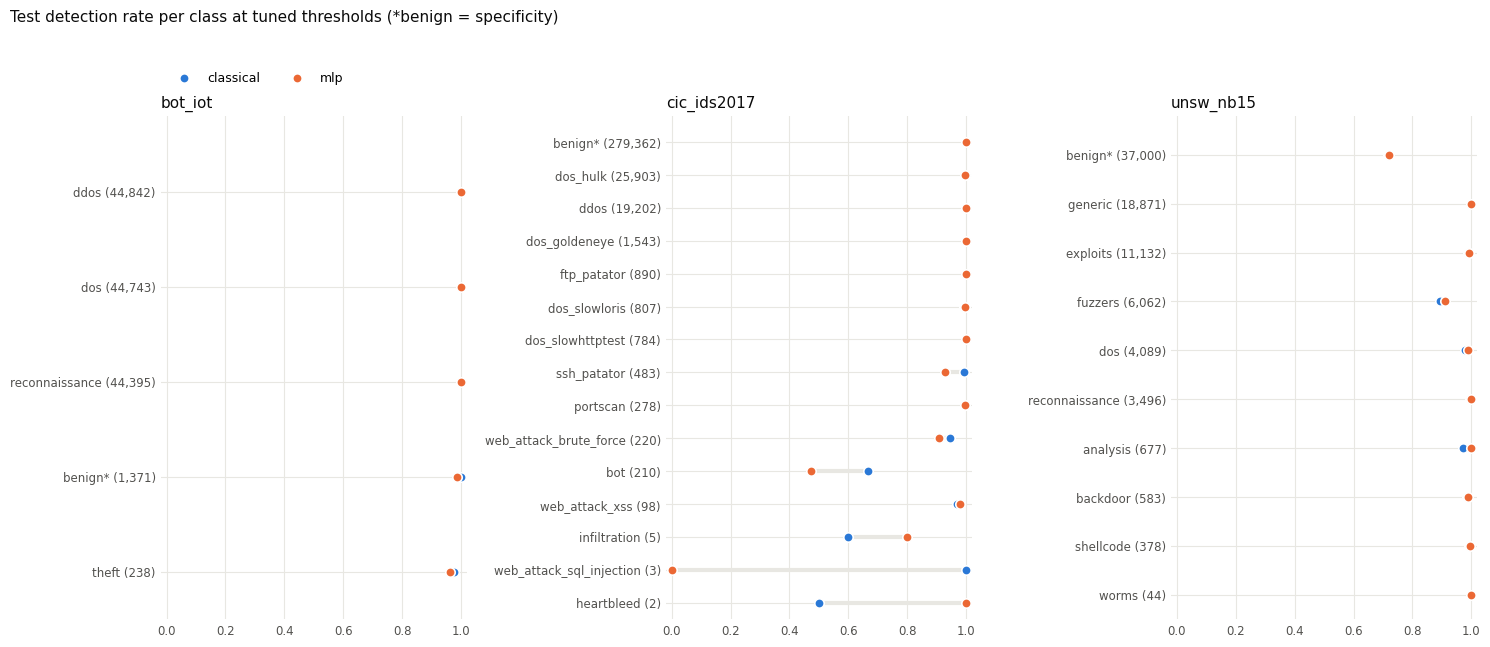

In [ ]:
pcs = []
for k in DATASETS:
    d = PRED[k]
    for m in MODELS:
        pc = per_class_detection(d.y_class.values, d.y_binary.values, d[f"p_{m}"].values, THR[k][m])
        pc.insert(0, "model", m); pc.insert(0, "dataset", k); pcs.append(pc)
per_class = pd.concat(pcs, ignore_index=True)
per_class["family"] = per_class.y_class.map(label_family)
per_class.to_csv(RES / "per_class_detection.csv", index=False)

fam = []
for k in DATASETS:
    d = PRED[k]
    for m in MODELS:
        pred = d[f"p_{m}"].values >= THR[k][m]
        g = pd.DataFrame({"family": d.y_family, "y": d.y_binary, "pred": pred}).groupby("family").agg(rows=("y", "size"), flagged=("pred", "mean"))
        for f, r in g.iterrows():
            fam.append({"dataset": k, "model": m, "family": f, "rows": int(r.rows),
                        "rate": r.flagged if f != "benign" else 1 - r.flagged})
family = pd.DataFrame(fam)
family.to_csv(RES / "family_detection.csv", index=False)
print("Detection rate by attack family (benign row = specificity), classical model:")
display(family[family.model == "classical"].pivot(index="family", columns="dataset", values="rate").round(4))

nmax = max(per_class[per_class.dataset == k].y_class.nunique() for k in DATASETS)
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.0 * len(DATASETS), 0.9 + 0.36 * nmax))
for ax, k in zip(axes, DATASETS):
    t = per_class[per_class.dataset == k].copy()
    t["score"] = np.where(t.is_attack == 1, t.detection_rate, 1 - t.false_alarm_rate)
    order = t[t.model == "classical"].sort_values("rows", ascending=False).y_class.tolist()
    for i, c in enumerate(order):
        a, b = [t[(t.model == m) & (t.y_class == c)].score.iloc[0] for m in MODELS]
        ax.hlines(i, min(a, b), max(a, b), color=GRID, linewidth=3, zorder=1)
        for m, v in zip(MODELS, (a, b)):
            ax.scatter(v, i, s=46, color=MODEL_COLOR[m], edgecolor="white", linewidth=1.2, zorder=3, label=m if i == 0 else None)
    n_rows = t[t.model == "classical"].set_index("y_class").rows
    ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{c} ({n_rows[c]:,})" if c != "benign" else f"benign* ({n_rows[c]:,})" for c in order], fontsize=8, color=INK)
    ax.set_ylim(len(order) - 0.5, -0.8); ax.set_xlim(-0.02, 1.02); style_axes(ax); ax.set_title(k, loc="left", fontsize=11, color=INK)
axes[0].legend(frameon=False, fontsize=9, loc="lower left", ncol=2, bbox_to_anchor=(0, 1.04))
fig.suptitle("Test detection rate per class at tuned thresholds (*benign = specificity)", x=0.01, ha="left", fontsize=11, color=INK, y=1.02)
fig.tight_layout(); fig.savefig(RES / "figures" / "per_class_detection.png", dpi=200, bbox_inches="tight"); plt.show()

## 6.3 · Precision / recall / F1 comparison

In [ ]:
prf = []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values
    for m in MODELS:
        pred = (d[f"p_{m}"].values >= THR[k][m])
        point = {kk: float(v[0]) for kk, v in _counts_metrics(y[None].astype(bool), pred[None]).items()}
        ci = bootstrap_ci(y, pred, N_BOOT, SEED)
        row = {"dataset": k, "model": m}
        for met in ["precision_attack", "recall_attack", "f1_attack", "f1_macro", "fpr", "fnr"]:
            row[met] = point[met]; row[met + "_lo"], row[met + "_hi"] = ci[met]
        prf.append(row)
prf = pd.DataFrame(prf); prf.to_csv(RES / "precision_recall_f1_ci.csv", index=False)
show = prf[["dataset", "model"]].copy()
for met in ["precision_attack", "recall_attack", "f1_attack", "f1_macro", "fpr"]:
    show[met] = [f"{r[met]:.4f} [{r[met + '_lo']:.4f}, {r[met + '_hi']:.4f}]" for _, r in prf.iterrows()]
display(show)

,dataset,model,precision_attack,recall_attack,f1_attack,f1_macro,fpr
0,bot_iot,classical,"1.0000 [1.0000, 1.0000]","0.9999 [0.9999, 1.0000]","1.0000 [0.9999, 1.0000]","0.9978 [0.9964, 0.9989]","0.0015 [0.0000, 0.0037]"
1,bot_iot,mlp,"0.9999 [0.9998, 0.9999]","0.9997 [0.9996, 0.9998]","0.9998 [0.9997, 0.9998]","0.9880 [0.9848, 0.9907]","0.0146 [0.0088, 0.0208]"
2,cic_ids2017,classical,"0.9973 [0.9969, 0.9978]","0.9974 [0.9970, 0.9979]","0.9974 [0.9971, 0.9977]","0.9985 [0.9983, 0.9986]","0.0005 [0.0004, 0.0006]"
3,cic_ids2017,mlp,"0.9872 [0.9862, 0.9880]","0.9935 [0.9928, 0.9943]","0.9904 [0.9897, 0.9909]","0.9943 [0.9939, 0.9946]","0.0023 [0.0022, 0.0025]"
4,unsw_nb15,classical,"0.8089 [0.8054, 0.8123]","0.9795 [0.9782, 0.9807]","0.8861 [0.8839, 0.8882]","0.8544 [0.8521, 0.8569]","0.2835 [0.2790, 0.2878]"
5,unsw_nb15,mlp,"0.8119 [0.8084, 0.8149]","0.9838 [0.9826, 0.9849]","0.8896 [0.8875, 0.8915]","0.8589 [0.8566, 0.8614]","0.2793 [0.2750, 0.2834]"


## 6.4 · ROC-AUC and PR-AUC comparison

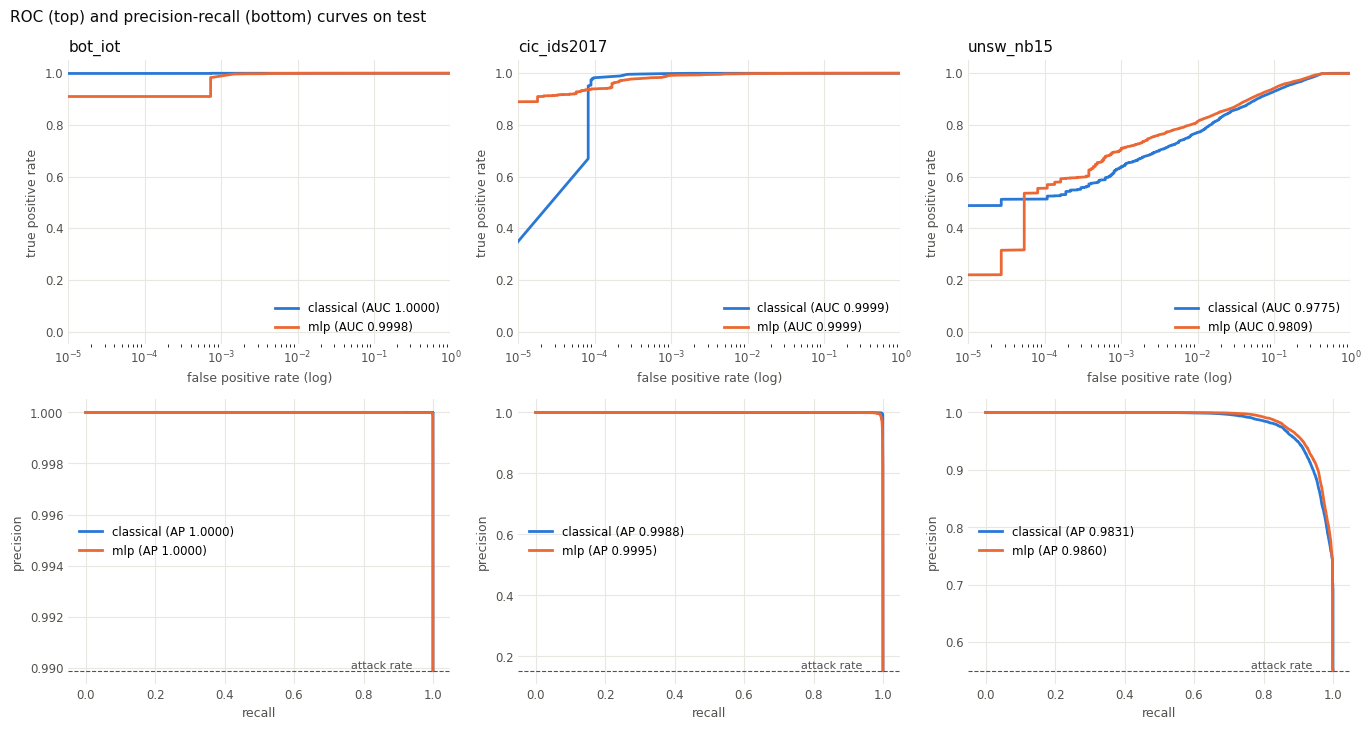

,dataset,model,roc_auc,pauc_fpr_1pct,pr_auc,pr_baseline
0,bot_iot,classical,1.00000,0.99996,1.00000,0.98989
1,bot_iot,mlp,0.99983,0.99612,1.00000,0.98989
2,cic_ids2017,classical,0.99986,0.99556,0.99881,0.15291
3,cic_ids2017,mlp,0.99988,0.99697,0.99950,0.15291
4,unsw_nb15,classical,0.97749,0.85452,0.98309,0.55060
5,unsw_nb15,mlp,0.98094,0.88050,0.98599,0.55060


In [ ]:
auc_rows = []
fig, axes = plt.subplots(2, len(DATASETS), figsize=(4.6 * len(DATASETS), 7.4))
for j, k in enumerate(DATASETS):
    d = PRED[k]; y = d.y_binary.values; prev = y.mean()
    for m in MODELS:
        p = d[f"p_{m}"].values
        fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
        auc_rows.append({"dataset": k, "model": m, "roc_auc": roc_auc_score(y, p), "pauc_fpr_1pct": roc_auc_score(y, p, max_fpr=0.01),
                         "pr_auc": average_precision_score(y, p), "pr_baseline": prev})
        keep = np.unique(np.linspace(0, len(fpr) - 1, min(len(fpr), 3000)).astype(int))
        axes[0, j].plot(np.clip(fpr[keep], 1e-6, 1), tpr[keep], color=MODEL_COLOR[m], linewidth=2, label=f"{m} (AUC {auc_rows[-1]['roc_auc']:.4f})")
        keep = np.unique(np.linspace(0, len(rec) - 1, min(len(rec), 3000)).astype(int))
        axes[1, j].plot(rec[keep], prec[keep], color=MODEL_COLOR[m], linewidth=2, label=f"{m} (AP {auc_rows[-1]['pr_auc']:.4f})")
    axes[0, j].set_xscale("log"); axes[0, j].set_xlim(1e-5, 1); axes[0, j].set_title(k, loc="left", fontsize=11, color=INK)
    axes[0, j].set_xlabel("false positive rate (log)", color=MUTED, fontsize=9); axes[0, j].set_ylabel("true positive rate", color=MUTED, fontsize=9)
    axes[1, j].axhline(prev, color=MUTED, linewidth=0.8, linestyle="--"); axes[1, j].text(0.95, prev, "attack rate ", color=MUTED, fontsize=8, va="bottom", ha="right")
    axes[1, j].set_xlabel("recall", color=MUTED, fontsize=9); axes[1, j].set_ylabel("precision", color=MUTED, fontsize=9)
    for a in axes[:, j]:
        style_axes(a); a.legend(frameon=False, fontsize=8.5, loc="lower right" if a is axes[0, j] else "center left")
fig.suptitle("ROC (top) and precision-recall (bottom) curves on test", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "roc_pr_curves.png", dpi=200, bbox_inches="tight"); plt.show()
aucs = pd.DataFrame(auc_rows); aucs.to_csv(RES / "auc_comparison.csv", index=False)
display(aucs.round(5))

## 6.5 · Confusion-matrix analysis

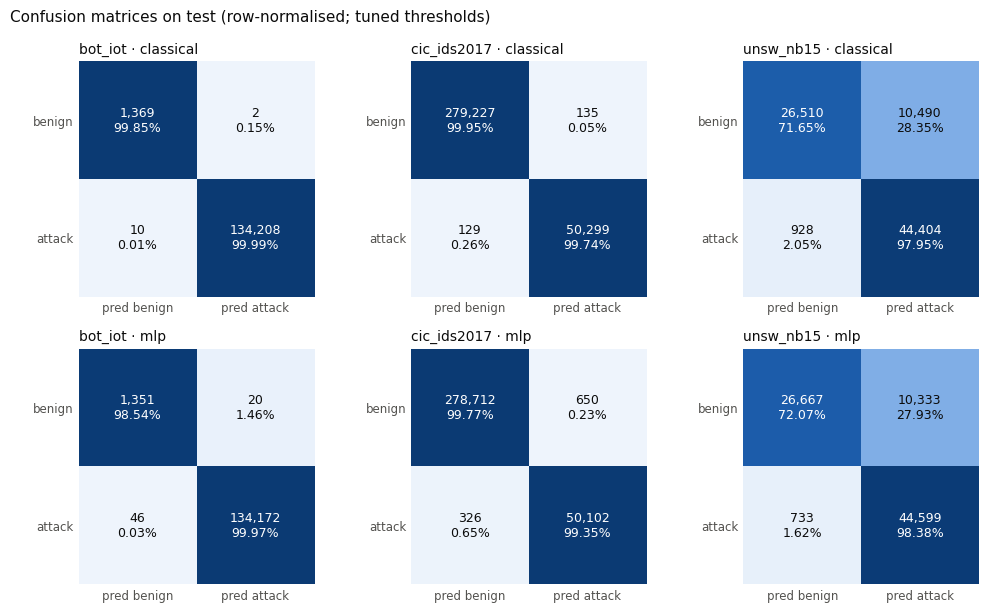

,dataset,model,tn,fp,fn,tp,tnr,fpr,fnr,tpr
0,bot_iot,classical,1369,2,10,134208,0.99854,0.00146,0.00007,0.99993
1,cic_ids2017,classical,279227,135,129,50299,0.99952,0.00048,0.00256,0.99744
2,unsw_nb15,classical,26510,10490,928,44404,0.71649,0.28351,0.02047,0.97953
3,bot_iot,mlp,1351,20,46,134172,0.98541,0.01459,0.00034,0.99966
4,cic_ids2017,mlp,278712,650,326,50102,0.99767,0.00233,0.00646,0.99354
5,unsw_nb15,mlp,26667,10333,733,44599,0.72073,0.27927,0.01617,0.98383


In [ ]:
cm_rows = []
fig, axes = plt.subplots(len(MODELS), len(DATASETS), figsize=(3.4 * len(DATASETS), 3.1 * len(MODELS)))
from matplotlib.colors import LinearSegmentedColormap
BLUES = LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#2a78d6", "#0b3a73"])
for i, m in enumerate(MODELS):
    for j, k in enumerate(DATASETS):
        d = PRED[k]; y = d.y_binary.values; pred = (d[f"p_{m}"].values >= THR[k][m]).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1]); cmn = cm / cm.sum(axis=1, keepdims=True)
        cm_rows.append({"dataset": k, "model": m, "tn": cm[0, 0], "fp": cm[0, 1], "fn": cm[1, 0], "tp": cm[1, 1],
                        "tnr": cmn[0, 0], "fpr": cmn[0, 1], "fnr": cmn[1, 0], "tpr": cmn[1, 1]})
        ax = axes[i, j]; ax.imshow(cmn, cmap=BLUES, vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a, b]:,}\n{cmn[a, b]:.2%}", ha="center", va="center", fontsize=9,
                        color="white" if cmn[a, b] > 0.55 else INK)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred benign", "pred attack"], fontsize=8.5, color=MUTED)
        ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "attack"], fontsize=8.5, color=MUTED)
        ax.tick_params(length=0)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title(f"{k} · {m}", loc="left", fontsize=10, color=INK)
fig.suptitle("Confusion matrices on test (row-normalised; tuned thresholds)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()
cms = pd.DataFrame(cm_rows); cms.to_csv(RES / "confusion_matrices.csv", index=False)
display(cms.round(5))

## 6.6 · Generalization analysis

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
gap = []
for k in DATASETS:
    r = perf[perf.dataset == k].set_index("model")
    gap.append({"dataset": k, "model": "classical", "val_f1_macro": M4SEL[k]["val_f1_macro_at_tuned"], "test_f1_macro": r.loc["classical", "f1_macro"]})
    gap.append({"dataset": k, "model": "mlp", "val_f1_macro": M5SEL[k]["val_f1_macro_at_tuned"], "test_f1_macro": r.loc["mlp", "f1_macro"]})
gap = pd.DataFrame(gap); gap["gap"] = gap.test_f1_macro - gap.val_f1_macro
gap.to_csv(RES / "val_test_gap.csv", index=False); display(gap.round(4))

adv = []
for k in DATASETS:
    feats = M3["datasets"][k]["feature_names"]
    Xa, _, _, _ = load_split(BASE, M3, k, "train", cap=ADV_SAMPLE, seed=SEED)
    Xb, _, _, _ = load_split(BASE, M3, k, "test", cap=ADV_SAMPLE, seed=SEED)
    X = np.concatenate([Xa, Xb]); z = np.r_[np.zeros(len(Xa)), np.ones(len(Xb))].astype(int)
    Xtr, Xte, ztr, zte = train_test_split(X, z, test_size=0.3, stratify=z, random_state=SEED)
    rf = RandomForestClassifier(n_estimators=100, max_depth=14, n_jobs=-1, random_state=SEED).fit(Xtr, ztr)
    auc = roc_auc_score(zte, rf.predict_proba(Xte)[:, 1])
    top = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False).head(5)
    adv.append({"dataset": k, "train_vs_test_auc": auc, "shift_level": "strong" if auc > 0.75 else ("moderate" if auc > 0.6 else "none/weak"),
                "top_shift_features": ", ".join(f"{f.split('__', 1)[-1]} ({v:.2f})" for f, v in top.items())})
    del X, Xa, Xb, rf; gc.collect()
adv = pd.DataFrame(adv); adv.to_csv(RES / "adversarial_validation.csv", index=False); display(adv)

TR_SETS = ["bot_iot", "unsw_nb15"]
clean = {k: pd.read_parquet(BASE / M2["datasets"][k]["output"]) for k in TR_SETS}
man = {k: pd.read_parquet(BASE / M3["datasets"][k]["split_manifest"]) for k in TR_SETS}
shared = [f for f in SHARED_FEATURES if all(f in clean[k].columns for k in TR_SETS)]
num_sh = [f for f in shared if f not in ("proto", "state")]; cat_sh = [f for f in shared if f in ("proto", "state")]
cat_levels = {c: sorted(set.intersection(*[set(clean[k][c].astype(str).str.lower().value_counts().head(8).index) for k in TR_SETS])) for c in cat_sh}
def shared_X(df):
    parts = [np.log1p(df[num_sh].astype("float64").clip(lower=0)).to_numpy()] if num_sh else []
    for c in cat_sh:
        v = df[c].astype(str).str.lower().to_numpy()
        parts.append(np.stack([(v == lv) for lv in cat_levels[c]] + [~np.isin(v, cat_levels[c])], axis=1).astype(float))
    return np.concatenate(parts, axis=1).astype(np.float32)
print("shared features:", num_sh, "| categorical:", {c: cat_levels[c] for c in cat_sh})
transfer = []
if len(shared) >= 2:
    for src in TR_SETS:
        tr_rows = man[src].loc[man[src].split == "train", "row"].to_numpy()
        if len(tr_rows) > TRANSFER_TRAIN_CAP:
            tr_rows, _ = train_test_split(tr_rows, train_size=TRANSFER_TRAIN_CAP, stratify=_strat(man[src].set_index("row").loc[tr_rows, "y_class"]), random_state=SEED)
        s = clean[src].iloc[tr_rows]
        mdl = HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED).fit(shared_X(s), s.y_binary.values)
        for tgt in TR_SETS:
            te_rows = man[tgt].loc[man[tgt].split == "test", "row"].to_numpy(); t = clean[tgt].iloc[te_rows]
            p = mdl.predict_proba(shared_X(t))[:, 1]; r = binary_metrics(t.y_binary.values, p, 0.5)
            transfer.append({"train_on": src, "test_on": tgt, "setting": "in-domain" if src == tgt else "cross-domain",
                             "f1_macro": r["f1_macro"], "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"], "fpr": r["fpr"], "fnr": r["fnr"],
                             "test_attack_rate": float(t.y_binary.mean())})
transfer = pd.DataFrame(transfer); transfer.to_csv(RES / "cross_dataset_transfer.csv", index=False)
display(transfer.round(4) if len(transfer) else "not enough shared features for transfer")
del clean; gc.collect()

,dataset,model,val_f1_macro,test_f1_macro,gap
0,bot_iot,classical,0.9978,0.9978,0.0000
1,bot_iot,mlp,0.9860,0.9880,0.0019
2,cic_ids2017,classical,0.9980,0.9985,0.0005
3,cic_ids2017,mlp,0.9964,0.9943,-0.0021
4,unsw_nb15,classical,0.9350,0.8544,-0.0805
5,unsw_nb15,mlp,0.9182,0.8589,-0.0593


,dataset,train_vs_test_auc,shift_level,top_shift_features
0,bot_iot,0.493762,none/weak,"sport (0.14), dur (0.10), rate (0.10), srate (..."
1,cic_ids2017,0.501718,none/weak,"Flow Duration (0.03), Fwd Packets/s (0.03), Fl..."
2,unsw_nb15,0.874172,strong,"ct_dst_sport_ltm (0.07), dbytes (0.06), sbytes..."


shared features: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate'] | categorical: {'proto': ['arp', 'tcp', 'udp'], 'state': ['acc', 'con', 'eco', 'fin', 'int', 'req', 'rst']}


,train_on,test_on,setting,f1_macro,roc_auc,pr_auc,fpr,fnr,test_attack_rate
0,bot_iot,bot_iot,in-domain,0.9893,0.9996,1.0000,0.0080,0.0004,0.9899
1,bot_iot,unsw_nb15,cross-domain,0.3097,0.3458,0.4871,0.6901,0.6892,0.5506
2,unsw_nb15,bot_iot,cross-domain,0.2572,0.1489,0.9661,0.9555,0.6517,0.9899
3,unsw_nb15,unsw_nb15,in-domain,0.8467,0.9719,0.9784,0.2917,0.0271,0.5506


64

## 6.7 · Error analysis

In [ ]:
overlap, fn_cls, conf, drivers = [], [], [], []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values.astype(bool)
    wrong = {m: (d[f"p_{m}"].values >= THR[k][m]) != y for m in MODELS}
    overlap.append({"dataset": k, "both_correct": int((~wrong["classical"] & ~wrong["mlp"]).sum()),
                    "only_classical_wrong": int((wrong["classical"] & ~wrong["mlp"]).sum()),
                    "only_mlp_wrong": int((~wrong["classical"] & wrong["mlp"]).sum()),
                    "both_wrong": int((wrong["classical"] & wrong["mlp"]).sum())})
    for m in MODELS:
        p = d[f"p_{m}"].values; t = THR[k][m]; err = wrong[m]
        fn = err & y
        g = pd.Series(d.y_class.values[fn]).value_counts()
        for c, n in g.items():
            fn_cls.append({"dataset": k, "model": m, "y_class": c, "false_negatives": int(n), "share_of_fn": n / max(fn.sum(), 1),
                           "class_miss_rate": n / int((d.y_class.values == c).sum())})
        near = err & (np.abs(p - t) <= 0.1); sure = err & ((p <= 0.05) | (p >= 0.95))
        conf.append({"dataset": k, "model": m, "errors": int(err.sum()), "borderline_within_0.1": int(near.sum()),
                     "confident_errors": int(sure.sum()), "pct_borderline": near.sum() / max(err.sum(), 1),
                     "pct_confident": sure.sum() / max(err.sum(), 1)})
    feats = M3["datasets"][k]["feature_names"]
    X, yy, _, rows = load_split(BASE, M3, k, "test")
    assert (rows == d.row.values).all()
    pc = d.p_classical.values >= THR[k]["classical"]
    for label, a_mask, b_mask in [("false_alarm_vs_true_negative", (~y) & pc, (~y) & ~pc), ("missed_vs_detected_attack", y & ~pc, y & pc)]:
        if a_mask.sum() >= 5 and b_mask.sum() >= 5:
            A, B = X[a_mask], X[b_mask]
            smd = (A.mean(0) - B.mean(0)) / np.sqrt((A.var(0) + B.var(0)) / 2 + 1e-9)
            for i in np.argsort(-np.abs(smd))[:6]:
                drivers.append({"dataset": k, "comparison": label, "feature": feats[i].split("__", 1)[-1], "std_mean_diff": float(smd[i]),
                                "n_error_rows": int(a_mask.sum())})
    del X; gc.collect()
overlap = pd.DataFrame(overlap); fn_cls = pd.DataFrame(fn_cls); conf = pd.DataFrame(conf); drivers = pd.DataFrame(drivers)
for n, t in [("error_overlap", overlap), ("false_negatives_by_class", fn_cls), ("error_confidence", conf), ("error_feature_drivers", drivers)]:
    t.to_csv(RES / f"{n}.csv", index=False)
print("Error overlap between classical and MLP:"); display(overlap)
print("\nMissed attacks by class (classical, top 5 per dataset):")
display(fn_cls[fn_cls.model == "classical"].sort_values(["dataset", "false_negatives"], ascending=[True, False]).groupby("dataset").head(5).round(4))
print("\nBorderline vs confident errors:"); display(conf.round(4))
print("\nFeatures that most separate errors from correct predictions (standardised mean difference, classical model):"); display(drivers.round(3))

Error overlap between classical and MLP:


,dataset,both_correct,only_classical_wrong,only_mlp_wrong,both_wrong
0,bot_iot,135518,5,59,7
1,cic_ids2017,328710,104,816,160
2,unsw_nb15,68936,2330,1978,9088



Missed attacks by class (classical, top 5 per dataset):


,dataset,model,y_class,false_negatives,share_of_fn,class_miss_rate
0,bot_iot,classical,theft,6,0.6000,0.0252
1,bot_iot,classical,reconnaissance,2,0.2000,0.0000
2,bot_iot,classical,dos,1,0.1000,0.0000
3,bot_iot,classical,ddos,1,0.1000,0.0000
8,cic_ids2017,classical,bot,70,0.5426,0.3333
9,cic_ids2017,classical,dos_hulk,18,0.1395,0.0007
10,cic_ids2017,classical,web_attack_brute_force,12,0.0930,0.0545
11,cic_ids2017,classical,ddos,9,0.0698,0.0005
12,cic_ids2017,classical,dos_slowloris,6,0.0465,0.0074
32,unsw_nb15,classical,fuzzers,641,0.6907,0.1057



Borderline vs confident errors:


,dataset,model,errors,borderline_within_0.1,confident_errors,pct_borderline,pct_confident
0,bot_iot,classical,12,2,3,0.1667,0.2500
1,bot_iot,mlp,66,54,52,0.8182,0.7879
2,cic_ids2017,classical,264,117,82,0.4432,0.3106
3,cic_ids2017,mlp,976,198,297,0.2029,0.3043
4,unsw_nb15,classical,11418,2231,925,0.1954,0.0810
5,unsw_nb15,mlp,11066,3853,703,0.3482,0.0635



Features that most separate errors from correct predictions (standardised mean difference, classical model):


,dataset,comparison,feature,std_mean_diff,n_error_rows
0,bot_iot,missed_vs_detected_attack,drate,2.196,10
1,bot_iot,missed_vs_detected_attack,state_con,2.157,10
2,bot_iot,missed_vs_detected_attack,dbytes,1.592,10
3,bot_iot,missed_vs_detected_attack,dpkts,1.582,10
4,bot_iot,missed_vs_detected_attack,spkts,1.063,10
5,bot_iot,missed_vs_detected_attack,sbytes,1.060,10
6,cic_ids2017,false_alarm_vs_true_negative,Fwd Packet Length Mean,-1.826,135
7,cic_ids2017,false_alarm_vs_true_negative,Avg Fwd Segment Size,-1.826,135
8,cic_ids2017,false_alarm_vs_true_negative,Subflow Fwd Bytes,-1.811,135
9,cic_ids2017,false_alarm_vs_true_negative,Total Length of Fwd Packets,-1.811,135


### Module 6 summary

In [ ]:
lines = ["# Module 6 — Cross-dataset analysis", "", "## Test performance (tuned thresholds)", "",
         "| Dataset | Model | Macro-F1 [95% CI] | Precision | Recall | ROC-AUC | pAUC@1% | PR-AUC | FPR | FNR |", "|---|---|---|---|---|---|---|---|---|---|"]
for k in DATASETS:
    for m in MODELS:
        r = prf[(prf.dataset == k) & (prf.model == m)].iloc[0]; a = aucs[(aucs.dataset == k) & (aucs.model == m)].iloc[0]
        lines.append(f"| {k} | {MODEL_NAME[k][m]} | {r.f1_macro:.4f} [{r.f1_macro_lo:.4f}, {r.f1_macro_hi:.4f}] | {r.precision_attack:.4f} | "
                     f"{r.recall_attack:.4f} | {a.roc_auc:.4f} | {a.pauc_fpr_1pct:.4f} | {a.pr_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |")
lines += ["", "## Generalization", "", "| Dataset | Model | Val macro-F1 | Test macro-F1 | Gap |", "|---|---|---|---|---|"]
lines += [f"| {r.dataset} | {r.model} | {r.val_f1_macro:.4f} | {r.test_f1_macro:.4f} | {r.gap:+.4f} |" for _, r in gap.iterrows()]
lines += ["", "Adversarial validation (train vs test ROC-AUC): " + "; ".join(f"{r.dataset} {r.train_vs_test_auc:.3f} ({r.shift_level})" for _, r in adv.iterrows())]
if len(transfer):
    lines += ["", "Cross-dataset transfer on shared Argus features (" + ", ".join(shared) + "):", "",
              "| Train on | Test on | Macro-F1 | ROC-AUC | FPR | FNR |", "|---|---|---|---|---|---|"]
    lines += [f"| {r.train_on} | {r.test_on} | {r.f1_macro:.4f} | {r.roc_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |" for _, r in transfer.iterrows()]
lines += ["", "## Errors", ""] + [f"- {r.dataset}: both models wrong on {r.both_wrong:,} rows; only classical wrong {r.only_classical_wrong:,}; only MLP wrong {r.only_mlp_wrong:,}"
                                  for _, r in overlap.iterrows()]
(RES / "summary.md").write_text("\n".join(lines))
(RES / "module6_manifest.json").write_text(json.dumps({"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "module": "6 - cross-dataset analysis", "thresholds": THR, "models": MODEL_NAME, "n_boot": N_BOOT, "shared_features": shared,
    "outputs": sorted(str(p.relative_to(BASE)) for p in RES.rglob("*") if p.is_file())}, indent=2, default=str))
print("\n".join(lines))

# Module 6 — Cross-dataset analysis

## Test performance (tuned thresholds)

| Dataset | Model | Macro-F1 [95% CI] | Precision | Recall | ROC-AUC | pAUC@1% | PR-AUC | FPR | FNR |
|---|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | 0.9978 [0.9964, 0.9989] | 1.0000 | 0.9999 | 1.0000 | 1.0000 | 1.0000 | 0.0015 | 0.0001 |
| bot_iot | torch_mlp_128_64 | 0.9880 [0.9848, 0.9907] | 0.9999 | 0.9997 | 0.9998 | 0.9961 | 1.0000 | 0.0146 | 0.0003 |
| cic_ids2017 | hist_gb | 0.9985 [0.9983, 0.9986] | 0.9973 | 0.9974 | 0.9999 | 0.9956 | 0.9988 | 0.0005 | 0.0026 |
| cic_ids2017 | torch_mlp_128_64 | 0.9943 [0.9939, 0.9946] | 0.9872 | 0.9935 | 0.9999 | 0.9970 | 0.9995 | 0.0023 | 0.0065 |
| unsw_nb15 | hist_gb | 0.8544 [0.8521, 0.8569] | 0.8089 | 0.9795 | 0.9775 | 0.8545 | 0.9831 | 0.2835 | 0.0205 |
| unsw_nb15 | torch_mlp_256_128_64 | 0.8589 [0.8566, 0.8614] | 0.8119 | 0.9838 | 0.9809 | 0.8805 | 0.9860 | 0.2793 | 0.0162 |

## Generalization

| Dataset | Model | Val macro-F1 | Test macr

# Module 7: CounterShield Evaluation

## 7.1 · CounterShield evaluation configuration

In [ ]:
PROJECT_DIR = "CounterShield"
SEED = 42
CANDIDATES = ["classical", "mlp", "ensemble"]
OPERATING_POINTS = {"max_f1": None, "fpr_1pct": 0.01, "fpr_0.1pct": 0.001}
PRIMARY_OP = "max_f1"
N_BOOT = 500
ROBUSTNESS = {"n_rows": 100_000,
              "noise_sigma": [0.05, 0.1, 0.25, 0.5],
              "feature_dropout": [0.1, 0.25, 0.5],
              "threshold_shift": [-0.1, -0.05, 0.05, 0.1]}

from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
warnings.filterwarnings("ignore", category=UserWarning)
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib.pyplot as plt
import joblib, sklearn, torch, torch.nn as nn

import os, gc, json, time, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
MODEL_COLOR = {"classical": SERIES[0], "mlp": SERIES[1], "ensemble": SERIES[2]}

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42, with_features=True):
    info = m3["datasets"][key]; feats = info["feature_names"]
    cols = (feats if with_features else []) + ["y_binary", "y_class", "row"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=cols)
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32) if with_features else None
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def label_family(c):
    if c == "benign": return "benign"
    if "ddos" in c: return "ddos"
    if "dos" in c: return "dos"
    if any(k in c for k in ("portscan", "reconnaissance", "recon", "scan", "fingerprint", "analysis")): return "recon"
    if any(k in c for k in ("patator", "brute", "password")) and "web" not in c: return "brute_force"
    if any(k in c for k in ("web_attack", "xss", "sql")): return "web_attack"
    if c in ("bot", "botnet"): return "botnet"
    if any(k in c for k in ("theft", "exfiltration", "keylog")): return "exfiltration_theft"
    if any(k in c for k in ("backdoor", "worm")): return "malware_backdoor"
    if any(k in c for k in ("exploit", "shellcode", "infiltration", "heartbleed")): return "exploit"
    return "other"

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(thr), "accuracy": accuracy_score(y, pred), "balanced_accuracy": balanced_accuracy_score(y, pred),
            "precision_attack": precision_score(y, pred, zero_division=0), "recall_attack": recall_score(y, pred, zero_division=0),
            "f1_attack": f1_score(y, pred, zero_division=0), "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "mcc": matthews_corrcoef(y, pred), "roc_auc": roc_auc_score(y, prob) if both else np.nan,
            "pr_auc": average_precision_score(y, prob) if both else np.nan,
            "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def _counts_metrics(y, p):
    tp = (y & p).sum(-1); fp = (~y & p).sum(-1); fn = (y & ~p).sum(-1); tn = (~y & ~p).sum(-1)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    f1a = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f1b = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return {"precision_attack": prec, "recall_attack": rec, "f1_attack": f1a, "f1_macro": (f1a + f1b) / 2,
            "fpr": fp / np.maximum(fp + tn, 1), "fnr": fn / np.maximum(fn + tp, 1)}

def bootstrap_ci(y, pred, n_boot=500, seed=42, chunk=20):
    rng = np.random.default_rng(seed)
    y, pred = y.astype(bool), pred.astype(bool)
    n, acc = len(y), {}
    for s in range(0, n_boot, chunk):
        idx = rng.integers(0, n, size=(min(chunk, n_boot - s), n))
        for k, v in _counts_metrics(y[idx], pred[idx]).items():
            acc.setdefault(k, []).append(v)
    return {k: (float(np.percentile(np.concatenate(v), 2.5)), float(np.percentile(np.concatenate(v), 97.5))) for k, v in acc.items()}

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    yb = y.astype(bool)
    P = prob[None, :] >= grid[:, None]
    scores = _counts_metrics(np.broadcast_to(yb, P.shape), P)[metric] if metric in ("f1_macro", "f1_attack") else None
    i = int(np.lexsort((np.abs(grid - 0.5), -scores))[0])
    return float(grid[i]), float(scores[i])

def threshold_for_fpr(y, prob, target):
    pb = np.sort(prob[y == 0])
    if len(pb) == 0: return 0.5
    k = int(np.floor(target * len(pb)))
    t = pb[len(pb) - k - 1] if k < len(pb) else pb[0]
    return float(np.nextafter(t, np.inf))

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    g = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred}).groupby("y_class") \
          .agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def style_axes(ax):
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    for s in ax.spines.values(): s.set_visible(False)

def load_predictions(base):
    m4 = json.loads((base / "results/module4/model_selection.json").read_text())
    m5 = json.loads((base / "results/module5/experiment_selection.json").read_text())
    P, THR, NAMES = {}, {}, {}
    for k in DATASETS:
        a = pd.read_parquet(base / "results/module4/test_predictions" / f"{k}.parquet")
        b = pd.read_parquet(base / "results/module5/test_predictions" / f"{k}.parquet")
        assert (a.row.values == b.row.values).all(), f"{k}: Module 4 and Module 5 test rows differ"
        P[k] = pd.DataFrame({"row": a.row.values, "y_binary": a.y_binary.values.astype(int), "y_class": a.y_class.astype(str).values,
                             "p_classical": a.prob_attack.values.astype(np.float32), "p_mlp": b.prob_attack.values.astype(np.float32)})
        P[k]["y_family"] = P[k].y_class.map(label_family)
        THR[k] = {"classical": m4[k]["tuned_threshold"], "mlp": m5[k]["tuned_threshold"]}
        NAMES[k] = {"classical": m4[k]["model"], "mlp": "torch_" + m5[k]["experiment"]}
    return P, THR, NAMES, m4, m5

class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.1, batchnorm=False):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers += [nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def load_mlp(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = MLP(ck["n_features"], ck["exp"]["hidden"], ck["exp"]["dropout"], ck["exp"]["batchnorm"]).to(DEVICE)
    m.load_state_dict(ck["state_dict"]); m.eval(); return m

@torch.no_grad()
def mlp_proba(model, X, batch=65536):
    return np.concatenate([torch.sigmoid(model(torch.from_numpy(X[i:i + batch]).to(DEVICE))).float().cpu().numpy()
                           for i in range(0, len(X), batch)]).astype(np.float32)

def classical_proba(model, X, chunk=200_000):
    return np.concatenate([model.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)]).astype(np.float32)

BASE = Path("/content/drive/MyDrive") / PROJECT_DIR
RES  = BASE / "results" / "module7"
(RES / "figures").mkdir(parents=True, exist_ok=True)
M3 = json.loads((BASE / "results/module3/module3_manifest.json").read_text())
M4 = json.loads((BASE / "results/module4/module4_manifest.json").read_text())
M5 = json.loads((BASE / "results/module5/module5_manifest.json").read_text())
PRED, THR5, MODEL_NAME, M4SEL, M5SEL = load_predictions(BASE)

VAL = {}
for k in DATASETS:
    _, yv, cv, _ = load_split(BASE, M3, k, "val", with_features=False)
    pc = np.load(BASE / "results/module4/val_probs" / f"{k}__{M4SEL[k]['model']}.npy")
    pm = np.load(BASE / "results/module5/val_probs" / f"{k}__{M5SEL[k]['experiment']}__s42.npy")
    assert len(pc) == len(pm) == len(yv), f"{k}: validation probabilities do not line up"
    VAL[k] = {"y": yv, "y_class": cv, "classical": pc, "mlp": pm, "ensemble": (pc + pm) / 2}
    PRED[k]["p_ensemble"] = (PRED[k].p_classical + PRED[k].p_mlp) / 2
(RES / "evaluation_config.json").write_text(json.dumps({"candidates": CANDIDATES, "operating_points": OPERATING_POINTS, "primary": PRIMARY_OP,
    "n_boot": N_BOOT, "robustness": ROBUSTNESS, "seed": SEED, "device": str(DEVICE),
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2))
print("device:", DEVICE, "| config ->", (RES / "evaluation_config.json").relative_to(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | config -> results/module7/evaluation_config.json


### Detector selection and operating points (validation only)

In [ ]:
SEL, OPS, cand_rows = {}, {}, []
for k in DATASETS:
    v = VAL[k]
    for c in CANDIDATES:
        thr, f1v = tune_threshold(v["y"], v[c])
        cand_rows.append({"dataset": k, "candidate": c, "val_f1_macro_tuned": f1v, "val_threshold": thr,
                          "val_pr_auc": average_precision_score(v["y"], v[c])})
    t = pd.DataFrame([r for r in cand_rows if r["dataset"] == k]).sort_values(["val_f1_macro_tuned", "val_pr_auc"], ascending=False)
    SEL[k] = t.iloc[0].candidate
    OPS[k] = {}
    for op, target in OPERATING_POINTS.items():
        OPS[k][op] = tune_threshold(v["y"], v[SEL[k]])[0] if target is None else threshold_for_fpr(v["y"], v[SEL[k]], target)
    print(f"{k:<12} CounterShield = {SEL[k]:<10} (val macro-F1 {t.iloc[0].val_f1_macro_tuned:.4f}) | thresholds " +
          ", ".join(f"{op} {th:.4f}" for op, th in OPS[k].items()) + f" | val benign rows {int((v['y'] == 0).sum()):,}")
cands = pd.DataFrame(cand_rows); cands.to_csv(RES / "candidate_selection.csv", index=False)
display(cands.pivot(index="candidate", columns="dataset", values="val_f1_macro_tuned").round(4))
(RES / "countershield_selection.json").write_text(json.dumps({k: {"detector": SEL[k], "thresholds": OPS[k]} for k in DATASETS}, indent=2))

bot_iot      CounterShield = classical  (val macro-F1 0.9978) | thresholds max_f1 0.6600, fpr_1pct 0.4933, fpr_0.1pct 0.9600 | val benign rows 1,371
cic_ids2017  CounterShield = classical  (val macro-F1 0.9980) | thresholds max_f1 0.7900, fpr_1pct 0.0045, fpr_0.1pct 0.4970 | val benign rows 279,362
unsw_nb15    CounterShield = classical  (val macro-F1 0.9350) | thresholds max_f1 0.4800, fpr_1pct 0.9094, fpr_0.1pct 0.9991 | val benign rows 7,750


dataset,bot_iot,cic_ids2017,unsw_nb15
candidate,,,
classical,0.9978,0.9980,0.9350
ensemble,0.9961,0.9977,0.9340
mlp,0.9860,0.9964,0.9182


545

## 7.2 · Detection-performance analysis

In [ ]:
det = []
for k in DATASETS:
    d = PRED[k]; y = d.y_binary.values
    for op, thr in OPS[k].items():
        p = d[f"p_{SEL[k]}"].values; r = binary_metrics(y, p, thr); ci = bootstrap_ci(y, p >= thr, N_BOOT, SEED)
        r.update(dataset=k, detector=SEL[k], operating_point=op, f1_macro_lo=ci["f1_macro"][0], f1_macro_hi=ci["f1_macro"][1],
                 recall_lo=ci["recall_attack"][0], recall_hi=ci["recall_attack"][1], fpr_lo=ci["fpr"][0], fpr_hi=ci["fpr"][1],
                 alerts_per_100k_benign=100_000 * r["fpr"], missed_per_100k_attacks=100_000 * r["fnr"])
        det.append(r)
det = pd.DataFrame(det); det.to_csv(RES / "detection_performance.csv", index=False)
cols = ["dataset", "detector", "operating_point", "threshold", "f1_macro", "f1_macro_lo", "f1_macro_hi", "precision_attack", "recall_attack",
        "mcc", "roc_auc", "pr_auc", "fpr", "fnr"]
display(det[cols].style.format({c: "{:.4f}" for c in cols[3:]}).hide(axis="index"))

allc = []
for k in DATASETS:
    thr_c = {c: cands[(cands.dataset == k) & (cands.candidate == c)].val_threshold.iloc[0] for c in CANDIDATES}
    for c in CANDIDATES:
        r = binary_metrics(PRED[k].y_binary.values, PRED[k][f"p_{c}"].values, thr_c[c]); r.update(dataset=k, candidate=c, selected=c == SEL[k]); allc.append(r)
allc = pd.DataFrame(allc); allc.to_csv(RES / "all_candidates_test.csv", index=False)
print("All candidates on test (each at its validation max-F1 threshold); selected = chosen on validation:")
display(allc[["dataset", "candidate", "selected", "threshold", "f1_macro", "pr_auc", "fpr", "fnr"]].round(4))

pcs = []
for k in DATASETS:
    for op, thr in OPS[k].items():
        pc = per_class_detection(PRED[k].y_class.values, PRED[k].y_binary.values, PRED[k][f"p_{SEL[k]}"].values, thr)
        pc.insert(0, "operating_point", op); pc.insert(0, "dataset", k); pcs.append(pc)
perclass = pd.concat(pcs, ignore_index=True); perclass.to_csv(RES / "per_class_detection.csv", index=False)
print("Per-class detection (attacks) / false-alarm rate (benign), primary operating point:")
display(perclass[perclass.operating_point == PRIMARY_OP].round(4))

dataset,detector,operating_point,threshold,f1_macro,f1_macro_lo,f1_macro_hi,precision_attack,recall_attack,mcc,roc_auc,pr_auc,fpr,fnr
bot_iot,classical,max_f1,0.6600,0.9978,0.9964,0.9989,1.0000,0.9999,0.9956,1.0000,1.0000,0.0015,0.0001
bot_iot,classical,fpr_1pct,0.4933,0.9982,0.9970,0.9993,1.0000,1.0000,0.9963,1.0000,1.0000,0.0044,0.0000
bot_iot,classical,fpr_0.1pct,0.9600,0.9909,0.9882,0.9932,1.0000,0.9996,0.9820,1.0000,1.0000,0.0007,0.0004
cic_ids2017,classical,max_f1,0.7900,0.9985,0.9983,0.9986,0.9973,0.9974,0.9969,0.9999,0.9988,0.0005,0.0026
cic_ids2017,classical,fpr_1pct,0.0045,0.9692,0.9684,0.9700,0.9018,0.9999,0.9402,0.9999,0.9988,0.0196,0.0001
cic_ids2017,classical,fpr_0.1pct,0.4970,0.9979,0.9977,0.9981,0.9936,0.9993,0.9958,0.9999,0.9988,0.0012,0.0007
unsw_nb15,classical,max_f1,0.4800,0.8544,0.8521,0.8569,0.8089,0.9795,0.7345,0.9775,0.9831,0.2835,0.0205
unsw_nb15,classical,fpr_1pct,0.9094,0.9156,0.9138,0.9175,0.9550,0.8892,0.8339,0.9775,0.9831,0.0513,0.1108
unsw_nb15,classical,fpr_0.1pct,0.9991,0.6782,0.6750,0.6814,1.0000,0.4406,0.5113,0.9775,0.9831,0.0000,0.5594


All candidates on test (each at its validation max-F1 threshold); selected = chosen on validation:


,dataset,candidate,selected,threshold,f1_macro,pr_auc,fpr,fnr
0,bot_iot,classical,True,0.66,0.9978,1.0000,0.0015,0.0001
1,bot_iot,mlp,False,0.02,0.9880,1.0000,0.0146,0.0003
2,bot_iot,ensemble,False,0.45,0.9965,1.0000,0.0007,0.0001
3,cic_ids2017,classical,True,0.79,0.9985,0.9988,0.0005,0.0026
4,cic_ids2017,mlp,False,0.70,0.9943,0.9995,0.0023,0.0065
5,cic_ids2017,ensemble,False,0.51,0.9979,0.9999,0.0011,0.0014
6,unsw_nb15,classical,True,0.48,0.8544,0.9831,0.2835,0.0205
7,unsw_nb15,mlp,False,0.50,0.8589,0.9860,0.2793,0.0162
8,unsw_nb15,ensemble,False,0.48,0.8551,0.9862,0.2899,0.0133


Per-class detection (attacks) / false-alarm rate (benign), primary operating point:


,dataset,operating_point,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,max_f1,benign,1371,0,NaN,0.0015
1,bot_iot,max_f1,ddos,44842,1,1.0000,NaN
2,bot_iot,max_f1,dos,44743,1,1.0000,NaN
3,bot_iot,max_f1,reconnaissance,44395,1,1.0000,NaN
4,bot_iot,max_f1,theft,238,1,0.9748,NaN
15,cic_ids2017,max_f1,benign,279362,0,NaN,0.0005
16,cic_ids2017,max_f1,bot,210,1,0.6667,NaN
17,cic_ids2017,max_f1,ddos,19202,1,0.9995,NaN
18,cic_ids2017,max_f1,dos_goldeneye,1543,1,1.0000,NaN
19,cic_ids2017,max_f1,dos_hulk,25903,1,0.9993,NaN


## 7.3 · False-positive / false-negative analysis

,dataset,detector,operating_point,threshold,fp,tn,fn,tp,fpr,fnr,alerts_per_100k_benign,missed_per_100k_attacks,precision_of_alerts
0,bot_iot,classical,max_f1,0.66000,2,1369,10,134208,0.00146,0.00007,145.87892,7.45057,0.99999
1,bot_iot,classical,fpr_1pct,0.49333,6,1365,4,134214,0.00438,0.00003,437.63676,2.98023,0.99996
2,bot_iot,classical,fpr_0.1pct,0.96000,1,1370,49,134169,0.00073,0.00037,72.93946,36.50777,0.99999
3,cic_ids2017,classical,max_f1,0.79000,135,279227,129,50299,0.00048,0.00256,48.32440,255.81026,0.99732
4,cic_ids2017,classical,fpr_1pct,0.00450,5488,273874,6,50422,0.01964,0.00012,1964.47620,11.89815,0.90184
5,cic_ids2017,classical,fpr_0.1pct,0.49705,323,279039,34,50394,0.00116,0.00067,115.62059,67.42286,0.99363
6,unsw_nb15,classical,max_f1,0.48000,10490,26510,928,44404,0.28351,0.02047,28351.35135,2047.11903,0.80890
7,unsw_nb15,classical,fpr_1pct,0.90940,1899,35101,5022,40310,0.05132,0.11078,5132.43243,11078.26701,0.95501
8,unsw_nb15,classical,fpr_0.1pct,0.99907,0,37000,25360,19972,0.00000,0.55943,0.00000,55942.82185,1.00000


Classes contributing most false negatives:


,dataset,operating_point,y_class,rows,detection_rate,missed
13,bot_iot,fpr_0.1pct,reconnaissance,44395,0.9993,33.0
14,bot_iot,fpr_0.1pct,theft,238,0.9622,9.0
12,bot_iot,fpr_0.1pct,dos,44743,0.9999,4.0
9,bot_iot,fpr_1pct,theft,238,0.9874,3.0
6,bot_iot,fpr_1pct,ddos,44842,1.0000,1.0
7,bot_iot,fpr_1pct,dos,44743,1.0000,0.0
4,bot_iot,max_f1,theft,238,0.9748,6.0
3,bot_iot,max_f1,reconnaissance,44395,1.0000,2.0
2,bot_iot,max_f1,dos,44743,1.0000,1.0
49,cic_ids2017,fpr_0.1pct,dos_hulk,25903,0.9997,9.0


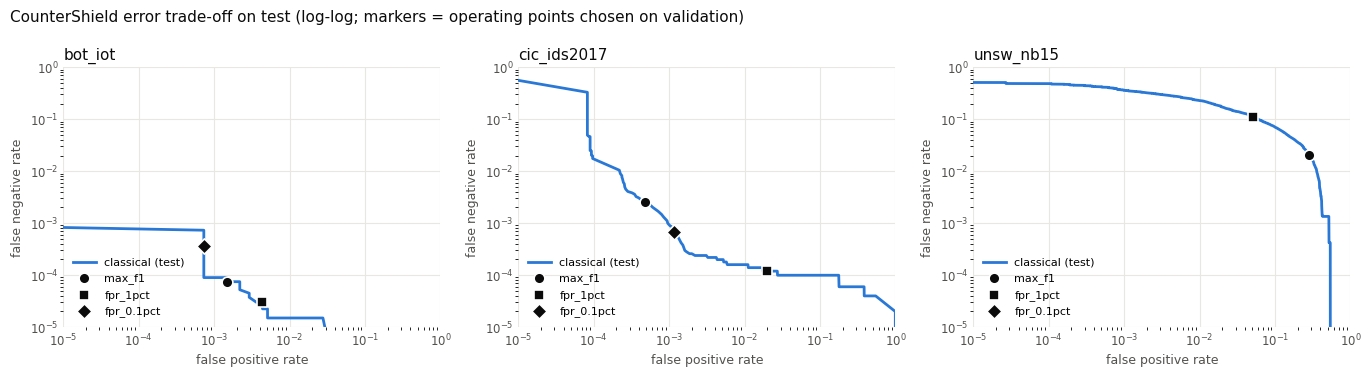

In [ ]:
fpfn = det[["dataset", "detector", "operating_point", "threshold", "fp", "tn", "fn", "tp", "fpr", "fnr", "alerts_per_100k_benign", "missed_per_100k_attacks"]].copy()
fpfn["precision_of_alerts"] = fpfn.tp / (fpfn.tp + fpfn.fp).clip(lower=1)
fpfn.to_csv(RES / "fp_fn_by_operating_point.csv", index=False)
display(fpfn.round(5))

miss = perclass[(perclass.is_attack == 1)].copy(); miss["missed"] = (1 - miss.detection_rate) * miss.rows
top_missed = miss.sort_values(["dataset", "operating_point", "missed"], ascending=[True, True, False]).groupby(["dataset", "operating_point"]).head(3)
top_missed.to_csv(RES / "top_missed_classes.csv", index=False)
print("Classes contributing most false negatives:"); display(top_missed[["dataset", "operating_point", "y_class", "rows", "detection_rate", "missed"]].round(4))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.6 * len(DATASETS), 3.8))
OP_MARK = {"max_f1": "o", "fpr_1pct": "s", "fpr_0.1pct": "D"}
for ax, k in zip(axes, DATASETS):
    d = PRED[k]; y = d.y_binary.values; p = d[f"p_{SEL[k]}"].values
    fpr, tpr, _ = roc_curve(y, p); keep = np.unique(np.linspace(0, len(fpr) - 1, min(len(fpr), 3000)).astype(int))
    ax.plot(np.clip(fpr[keep], 1e-6, 1), np.clip(1 - tpr[keep], 1e-6, 1), color=MODEL_COLOR[SEL[k]], linewidth=2, label=f"{SEL[k]} (test)")
    for op, thr in OPS[k].items():
        r = det[(det.dataset == k) & (det.operating_point == op)].iloc[0]
        ax.scatter(max(r.fpr, 1e-6), max(r.fnr, 1e-6), marker=OP_MARK[op], s=60, color=INK, edgecolor="white", linewidth=1.2, zorder=3, label=op)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-5, 1); ax.set_ylim(1e-5, 1)
    ax.set_xlabel("false positive rate", color=MUTED, fontsize=9); ax.set_ylabel("false negative rate", color=MUTED, fontsize=9)
    ax.set_title(k, loc="left", fontsize=11, color=INK); style_axes(ax); ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("CounterShield error trade-off on test (log-log; markers = operating points chosen on validation)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "fp_fn_tradeoff.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.4 · Robustness analysis

bot_iot      done (100,000 rows, detector classical)
cic_ids2017  done (100,000 rows, detector classical)
unsw_nb15    done (82,332 rows, detector classical)


,dataset,perturbation,strength,f1_macro,fpr,fnr,roc_auc,f1_drop
0,bot_iot,none,0.00,0.9980,0.0010,0.0001,1.0000,0.0000
1,bot_iot,gaussian_noise,0.05,0.9927,0.0178,0.0001,0.9986,0.0053
2,bot_iot,gaussian_noise,0.10,0.9820,0.0485,0.0002,0.9983,0.0160
3,bot_iot,gaussian_noise,0.25,0.9413,0.1118,0.0012,0.9948,0.0567
4,bot_iot,gaussian_noise,0.50,0.7956,0.3225,0.0061,0.9707,0.2024
5,bot_iot,feature_dropout,0.10,0.9927,0.0208,0.0001,0.9992,0.0053
6,bot_iot,feature_dropout,0.25,0.9664,0.1128,0.0001,0.9969,0.0316
7,bot_iot,feature_dropout,0.50,0.8538,0.4313,0.0003,0.9726,0.1443
8,bot_iot,threshold_shift,-0.10,0.9980,0.0020,0.0001,1.0000,0.0000
9,bot_iot,threshold_shift,-0.05,0.9978,0.0020,0.0001,1.0000,0.0003


MLP seed stability (std of validation macro-F1 over seeds):


dataset,bot_iot,cic_ids2017,unsw_nb15
experiment,,,
mlp_128_64,0.00851,0.00009,0.00186
mlp_256_128_64,0.00439,0.00004,0.00161
mlp_512_256,0.00455,0.00016,0.00118


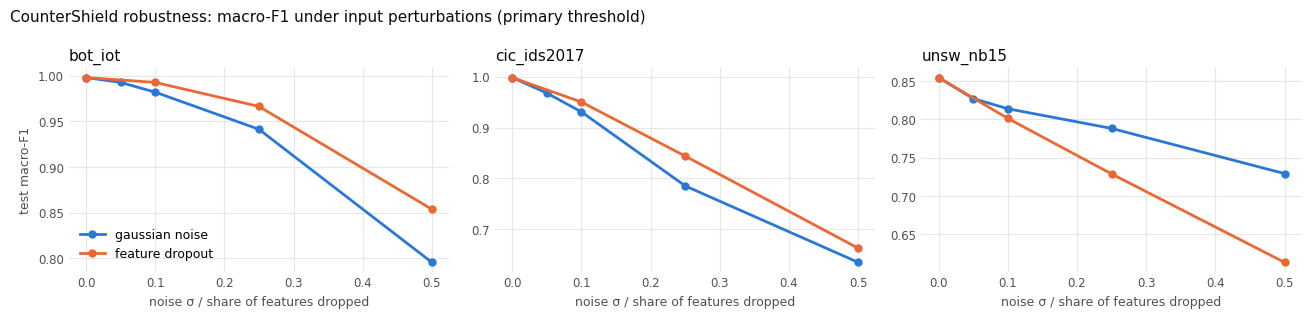

In [ ]:
rng = np.random.default_rng(SEED)
rob = []
for k in DATASETS:
    X, y, cl, rows = load_split(BASE, M3, k, "test", cap=ROBUSTNESS["n_rows"], seed=SEED)
    det_name = SEL[k]
    clf = joblib.load(BASE / M4["final_models"][k]["path"])["model"] if det_name in ("classical", "ensemble") else None
    mlp = load_mlp(BASE / M5["final_models"][k]["path"]) if det_name in ("mlp", "ensemble") else None
    def score(Xp):
        if det_name == "classical": return classical_proba(clf, Xp)
        if det_name == "mlp": return mlp_proba(mlp, Xp)
        return (classical_proba(clf, Xp) + mlp_proba(mlp, Xp)) / 2
    thr = OPS[k][PRIMARY_OP]; p0 = score(X); base_m = binary_metrics(y, p0, thr)
    rob.append({"dataset": k, "perturbation": "none", "strength": 0.0, **{m: base_m[m] for m in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    for s in ROBUSTNESS["noise_sigma"]:
        m = binary_metrics(y, score(X + rng.normal(0, s, X.shape).astype(np.float32)), thr)
        rob.append({"dataset": k, "perturbation": "gaussian_noise", "strength": s, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    for q in ROBUSTNESS["feature_dropout"]:
        Xd = X.copy(); Xd[rng.random(X.shape) < q] = 0.0
        m = binary_metrics(y, score(Xd), thr)
        rob.append({"dataset": k, "perturbation": "feature_dropout", "strength": q, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
        del Xd
    for dlt in ROBUSTNESS["threshold_shift"]:
        m = binary_metrics(y, p0, float(np.clip(thr + dlt, 1e-6, 1 - 1e-6)))
        rob.append({"dataset": k, "perturbation": "threshold_shift", "strength": dlt, **{kk: m[kk] for kk in ["f1_macro", "fpr", "fnr", "roc_auc"]}})
    print(f"{k:<12} done ({len(y):,} rows, detector {det_name})")
    del X, clf, mlp; gc.collect()
rob = pd.DataFrame(rob)
rob["f1_drop"] = rob.groupby("dataset").f1_macro.transform(lambda s: s.iloc[0]) - rob.f1_macro
rob.to_csv(RES / "robustness.csv", index=False)
display(rob.round(4))
seed_std = pd.read_csv(BASE / "results/module5/validation_summary.csv")
print("MLP seed stability (std of validation macro-F1 over seeds):")
display(seed_std.pivot(index="experiment", columns="dataset", values="f1_macro_std").round(5))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.4 * len(DATASETS), 3.2))
for ax, k in zip(axes, DATASETS):
    t = rob[rob.dataset == k]; b = t[t.perturbation == "none"].f1_macro.iloc[0]
    for (pert, col) in [("gaussian_noise", SERIES[0]), ("feature_dropout", SERIES[1])]:
        s = t[t.perturbation == pert]
        ax.plot([0] + s.strength.tolist(), [b] + s.f1_macro.tolist(), color=col, linewidth=2, marker="o", markersize=5, label=pert.replace("_", " "))
    ax.set_title(k, loc="left", fontsize=11, color=INK); ax.set_xlabel("noise σ / share of features dropped", color=MUTED, fontsize=9); style_axes(ax)
axes[0].set_ylabel("test macro-F1", color=MUTED, fontsize=9); axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("CounterShield robustness: macro-F1 under input perturbations (primary threshold)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "robustness.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.5 · Cross-dataset results

In [ ]:
xd = det[det.operating_point == PRIMARY_OP][["dataset", "detector", "threshold", "f1_macro", "f1_macro_lo", "f1_macro_hi", "recall_attack", "fpr", "roc_auc", "pr_auc"]]
display(xd.round(4))
fam = []
for k in DATASETS:
    d = PRED[k]; pred = d[f"p_{SEL[k]}"].values >= OPS[k][PRIMARY_OP]
    g = pd.DataFrame({"family": d.y_family, "pred": pred}).groupby("family").pred.agg(["size", "mean"])
    for f, r in g.iterrows():
        fam.append({"dataset": k, "family": f, "rows": int(r["size"]), "rate": 1 - r["mean"] if f == "benign" else r["mean"]})
fam = pd.DataFrame(fam); fam.to_csv(RES / "family_detection_cross_dataset.csv", index=False)
print("Detection rate by attack family (benign = specificity):"); display(fam.pivot(index="family", columns="dataset", values="rate").round(4))
tr_path = BASE / "results/module6/cross_dataset_transfer.csv"
transfer = pd.read_csv(tr_path) if tr_path.exists() else pd.DataFrame()
print("Cross-dataset transfer (Module 6, shared Argus features):"); display(transfer.round(4) if len(transfer) else "run Module 6 first")

,dataset,detector,threshold,f1_macro,f1_macro_lo,f1_macro_hi,recall_attack,fpr,roc_auc,pr_auc
0,bot_iot,classical,0.66,0.9978,0.9964,0.9989,0.9999,0.0015,1.0000,1.0000
3,cic_ids2017,classical,0.79,0.9985,0.9983,0.9986,0.9974,0.0005,0.9999,0.9988
6,unsw_nb15,classical,0.48,0.8544,0.8521,0.8569,0.9795,0.2835,0.9775,0.9831


Detection rate by attack family (benign = specificity):


dataset,bot_iot,cic_ids2017,unsw_nb15
family,,,
benign,0.9985,0.9995,0.7165
botnet,NaN,0.6667,NaN
brute_force,NaN,0.9956,NaN
ddos,1.0000,0.9995,NaN
dos,1.0000,0.9991,0.9768
exfiltration_theft,0.9748,NaN,NaN
exploit,NaN,0.5714,0.9877
malware_backdoor,NaN,NaN,0.9856
other,NaN,NaN,0.9740


Cross-dataset transfer (Module 6, shared Argus features):


,train_on,test_on,setting,f1_macro,roc_auc,pr_auc,fpr,fnr,test_attack_rate
0,bot_iot,bot_iot,in-domain,0.9893,0.9996,1.0000,0.0080,0.0004,0.9899
1,bot_iot,unsw_nb15,cross-domain,0.3097,0.3458,0.4871,0.6901,0.6892,0.5506
2,unsw_nb15,bot_iot,cross-domain,0.2572,0.1489,0.9661,0.9555,0.6517,0.9899
3,unsw_nb15,unsw_nb15,in-domain,0.8467,0.9719,0.9784,0.2917,0.0271,0.5506


## 7.6 · Final CounterShield results table

In [ ]:
final = []
for k in DATASETS:
    for op in OPERATING_POINTS:
        r = det[(det.dataset == k) & (det.operating_point == op)].iloc[0]
        worst = rob[(rob.dataset == k) & rob.perturbation.isin(["gaussian_noise", "feature_dropout"]) & (rob.strength <= 0.25)].f1_drop.max()
        final.append({"Dataset": k, "Detector": {"classical": MODEL_NAME[k]["classical"], "mlp": MODEL_NAME[k]["mlp"],
                                   "ensemble": f"{MODEL_NAME[k]['classical']} + {MODEL_NAME[k]['mlp']} (mean prob.)"}[SEL[k]],
                      "Operating point": op, "Threshold": r.threshold, "Macro-F1": r.f1_macro, "Macro-F1 95% CI": f"[{r.f1_macro_lo:.4f}, {r.f1_macro_hi:.4f}]",
                      "Attack F1": r.f1_attack, "Precision": r.precision_attack, "Recall": r.recall_attack, "MCC": r.mcc,
                      "ROC-AUC": r.roc_auc, "PR-AUC": r.pr_auc, "FPR": r.fpr, "FNR": r.fnr,
                      "Alerts / 100k benign": r.alerts_per_100k_benign, "Worst F1 drop (noise/dropout ≤ 0.25)": worst if op == PRIMARY_OP else np.nan,
                      "Note": "unattainable: too many validation benign rows tied at the top score" if r.threshold > 1 else ""})
final = pd.DataFrame(final)
final.to_csv(RES / "final_countershield_results.csv", index=False)
num = [c for c in final.columns if final[c].dtype.kind == "f"]
def md_table(df):
    try:
        return df.to_markdown(index=False, floatfmt=".4f")
    except ImportError:
        cols = list(df.columns)
        fmt = lambda v: f"{v:.4f}" if isinstance(v, float) else str(v)
        return "\n".join(["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)] + ["| " + " | ".join(fmt(v) for v in r) + " |" for r in df.itertuples(index=False)])
(RES / "final_countershield_results.md").write_text(md_table(final))
try:
    (RES / "final_countershield_results.tex").write_text(final.style.format({c: "{:.4f}" for c in num}).hide(axis="index").to_latex(hrules=True))
except Exception as e:
    print("LaTeX export skipped:", e)
display(final.style.format({c: "{:.4f}" for c in num}, na_rep="").hide(axis="index"))

Dataset,Detector,Operating point,Threshold,Macro-F1,Macro-F1 95% CI,Attack F1,Precision,Recall,MCC,ROC-AUC,PR-AUC,FPR,FNR,Alerts / 100k benign,Worst F1 drop (noise/dropout ≤ 0.25),Note
bot_iot,random_forest,max_f1,0.6600,0.9978,"[0.9964, 0.9989]",1.0000,1.0000,0.9999,0.9956,1.0000,1.0000,0.0015,0.0001,145.8789,0.0567,
bot_iot,random_forest,fpr_1pct,0.4933,0.9982,"[0.9970, 0.9993]",1.0000,1.0000,1.0000,0.9963,1.0000,1.0000,0.0044,0.0000,437.6368,,
bot_iot,random_forest,fpr_0.1pct,0.9600,0.9909,"[0.9882, 0.9932]",0.9998,1.0000,0.9996,0.9820,1.0000,1.0000,0.0007,0.0004,72.9395,,
cic_ids2017,hist_gb,max_f1,0.7900,0.9985,"[0.9983, 0.9986]",0.9974,0.9973,0.9974,0.9969,0.9999,0.9988,0.0005,0.0026,48.3244,0.2133,
cic_ids2017,hist_gb,fpr_1pct,0.0045,0.9692,"[0.9684, 0.9700]",0.9483,0.9018,0.9999,0.9402,0.9999,0.9988,0.0196,0.0001,1964.4762,,
cic_ids2017,hist_gb,fpr_0.1pct,0.4970,0.9979,"[0.9977, 0.9981]",0.9965,0.9936,0.9993,0.9958,0.9999,0.9988,0.0012,0.0007,115.6206,,
unsw_nb15,hist_gb,max_f1,0.4800,0.8544,"[0.8521, 0.8569]",0.8861,0.8089,0.9795,0.7345,0.9775,0.9831,0.2835,0.0205,28351.3514,0.1257,
unsw_nb15,hist_gb,fpr_1pct,0.9094,0.9156,"[0.9138, 0.9175]",0.9209,0.9550,0.8892,0.8339,0.9775,0.9831,0.0513,0.1108,5132.4324,,
unsw_nb15,hist_gb,fpr_0.1pct,0.9991,0.6782,"[0.6750, 0.6814]",0.6117,1.0000,0.4406,0.5113,0.9775,0.9831,0.0000,0.5594,0.0000,,


## 7.7 · Reproducibility / checkpoint audit

In [ ]:
audit = []
def A(area, item, ok, detail=""):
    audit.append({"area": area, "item": item, "status": "PASS" if ok is True else ("WARN" if ok is None else "FAIL"), "detail": str(detail)})
def check_file(area, rel, sha=None):
    f = BASE / rel
    if not f.exists(): return A(area, rel, False, "missing")
    if sha is None: return A(area, rel, True, "present (no hash recorded)")
    h = sha256_file(f); A(area, rel, h == sha, "sha256 ok" if h == sha else f"sha256 mismatch ({h[:12]} vs {sha[:12]})")
prov = BASE / "processed/provenance/provenance.json"
if prov.exists():
    P1 = json.loads(prov.read_text())
    for k in DATASETS:
        if k in P1 and "processed_file" in P1[k]: check_file("module1", P1[k]["processed_file"], P1[k].get("processed_sha256"))
        A("module1", f"{k} Kaggle version recorded", P1.get(k, {}).get("kaggle_version") is not None or None, P1.get(k, {}).get("kaggle_version"))
else:
    A("module1", "processed/provenance/provenance.json", False, "missing")
m2p = BASE / "results/module2/module2_manifest.json"
if m2p.exists():
    M2 = json.loads(m2p.read_text())
    for k, v in M2["datasets"].items():
        check_file("module2", v["input"], v["input_sha256"]); check_file("module2", v["output"], v["output_sha256"])
else:
    A("module2", "module2_manifest.json", False, "missing")
for k, v in M3["datasets"].items():
    check_file("module3", v["preprocessor"], v["preprocessor_sha256"]); check_file("module3", v["split_manifest"])
    for s, fv in v["files"].items(): check_file("module3", fv["path"], fv["sha256"])
for k, v in M4["final_models"].items(): check_file("module4", v["path"], v["sha256"])
for k, v in M5["final_models"].items(): check_file("module5", v["path"], v["sha256"])
for rel in ["configs/feature_schema.json", "configs/preprocessing_config.json", "results/module4/training_config.json",
            "results/module5/mlp_config.json", "results/module6/module6_manifest.json", "results/module7/evaluation_config.json"]:
    check_file("configs", rel)
pc = json.loads((BASE / "configs/preprocessing_config.json").read_text())
A("seeds", "split seed (Module 3)", all("seed" in v for v in pc["split"].values()), {k: v["seed"] for k, v in pc["split"].items()})
A("seeds", "training seed (Module 4)", "seed" in json.loads((BASE / "results/module4/training_config.json").read_text()))
A("seeds", "MLP seeds (Module 5)", "seeds" in json.loads((BASE / "results/module5/mlp_config.json").read_text()))
for k in DATASETS:
    X, _, _, _ = load_split(BASE, M3, k, "test"); X = X[:2000]
    try:
        clf = joblib.load(BASE / M4["final_models"][k]["path"])["model"]
        ok = np.allclose(classical_proba(clf, X), PRED[k].p_classical.values[:2000], atol=1e-6); A("determinism", f"{k} classical reproduces saved predictions", ok)
    except Exception as e:
        A("determinism", f"{k} classical reproduces saved predictions", False, repr(e)[:120])
    try:
        mlp = load_mlp(BASE / M5["final_models"][k]["path"])
        diff = float(np.abs(mlp_proba(mlp, X) - PRED[k].p_mlp.values[:2000]).max())
        A("determinism", f"{k} MLP reproduces saved predictions", True if diff < 1e-4 else (None if diff < 1e-2 else False), f"max |diff| {diff:.2e}")
    except Exception as e:
        A("determinism", f"{k} MLP reproduces saved predictions", False, repr(e)[:120])
A("environment", "scikit-learn version", True if sklearn.__version__ == M3["sklearn"] else None, f"now {sklearn.__version__}; Module 3/4 {M3['sklearn']}")
A("environment", "torch version", True if torch.__version__ == M5["torch"] else None, f"now {torch.__version__}; Module 5 {M5['torch']}")
audit = pd.DataFrame(audit); audit.to_csv(RES / "reproducibility_audit.csv", index=False)
print(audit.status.value_counts().to_string()); display(audit)

status
PASS    50


,area,item,status,detail
0,module1,processed/bot_iot.parquet,PASS,sha256 ok
1,module1,bot_iot Kaggle version recorded,PASS,1
2,module1,processed/cic_ids2017.parquet,PASS,sha256 ok
3,module1,cic_ids2017 Kaggle version recorded,PASS,2
4,module1,processed/unsw_nb15.parquet,PASS,sha256 ok
5,module1,unsw_nb15 Kaggle version recorded,PASS,2
6,module2,processed/bot_iot.parquet,PASS,sha256 ok
7,module2,processed/clean/bot_iot_clean.parquet,PASS,sha256 ok
8,module2,processed/cic_ids2017.parquet,PASS,sha256 ok
9,module2,processed/clean/cic_ids2017_clean.parquet,PASS,sha256 ok


### Module 7 summary

In [ ]:
lines = ["# Module 7 — CounterShield evaluation", "",
         "CounterShield = per-dataset detector chosen on validation among classical (Module 4), MLP (Module 5) and their probability-average ensemble; "
         "operating points chosen on validation; everything below is on the held-out test split.", "",
         "## Selected detectors", ""] + [f"- **{k}**: {SEL[k]} — thresholds " + ", ".join(f"{op} {t:.4f}" for op, t in OPS[k].items()) for k in DATASETS]
lines += ["", "## Final results", "", md_table(final.drop(columns=["Detector"])), "",
          "## Robustness (primary operating point, worst macro-F1 drop)", ""]
for k in DATASETS:
    t = rob[(rob.dataset == k) & (rob.perturbation != "none")]
    lines.append(f"- {k}: " + "; ".join(f"{p} worst drop {t[t.perturbation == p].f1_drop.max():+.4f}" for p in ["gaussian_noise", "feature_dropout", "threshold_shift"]))
lines += ["", f"## Reproducibility audit: {int((audit.status == 'PASS').sum())} pass, {int((audit.status == 'WARN').sum())} warn, {int((audit.status == 'FAIL').sum())} fail"]
lines += [f"- {r['status']}: {r['area']} / {r['item']} ({r['detail']})" for _, r in audit[audit.status != "PASS"].iterrows()]
(RES / "summary.md").write_text("\n".join(lines))
(RES / "module7_manifest.json").write_text(json.dumps({"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "module": "7 - CounterShield evaluation", "selection": {k: {"detector": SEL[k], "thresholds": OPS[k]} for k in DATASETS},
    "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "torch": torch.__version__, "device": str(DEVICE)},
    "outputs": sorted(str(p.relative_to(BASE)) for p in RES.rglob("*") if p.is_file())}, indent=2, default=str))
print("\n".join(lines))

# Module 7 — CounterShield evaluation

CounterShield = per-dataset detector chosen on validation among classical (Module 4), MLP (Module 5) and their probability-average ensemble; operating points chosen on validation; everything below is on the held-out test split.

## Selected detectors

- **bot_iot**: classical — thresholds max_f1 0.6600, fpr_1pct 0.4933, fpr_0.1pct 0.9600
- **cic_ids2017**: classical — thresholds max_f1 0.7900, fpr_1pct 0.0045, fpr_0.1pct 0.4970
- **unsw_nb15**: classical — thresholds max_f1 0.4800, fpr_1pct 0.9094, fpr_0.1pct 0.9991

## Final results

| Dataset     | Operating point   |   Threshold |   Macro-F1 | Macro-F1 95% CI   |   Attack F1 |   Precision |   Recall |    MCC |   ROC-AUC |   PR-AUC |    FPR |    FNR |   Alerts / 100k benign |   Worst F1 drop (noise/dropout ≤ 0.25) | Note   |
|:------------|:------------------|------------:|-----------:|:------------------|------------:|------------:|---------:|-------:|----------:|---------:|-------:|-------:|--